# Atividade 03 — Métodos de Explicação Local
## CP · ICE · LIME · SHAP · Contrafactuais — hesitação de digitação (dataset **KeyRecs**)

**Disciplina:** Aprendizado de Máquina Explicável — Prof. Dr. Anderson Ara (DEST/LEG/UFPR)

**Grupo:** Débora Zanoello (Doutorado) · Allysson Souza e Marcelo Carvalho (Mestrado) · Alex St Clair (Graduação)

---

### Continuidade com a Atividade 02

A ATV2 ajustou **dois modelos interpretáveis por construção** (linear e árvore) sobre o KeyRecs. A ATV3 muda a
pergunta: agora o modelo é tratado como **caixa-preta** (uma *Random Forest*) e a explicação vem de
**métodos post-hoc, locais e agnósticos ao modelo** — exatamente o cenário que a Entrega 1 previa (modelo
complexo + SHAP) e que a ATV2 deixou como *tensão em aberto*.

> **Pergunta de pesquisa (inalterada):** controlando a destreza motora medida na tarefa de texto fixo,
> quanta hesitação ainda resta quando a mesma pessoa precisa ler e transcrever texto?
>
> **Pergunta da ATV3:** para **este participante**, *por que* o modelo previu **esta** hesitação — e as
> diferentes explicações concordam entre si?

### ⚠️ Enquadramento ético (mantido da ATV2)

O dataset **não contém rótulo clínico**. Nada aqui detecta, diagnostica ou rastreia dislexia, disgrafia ou
qualquer condição. O objeto é um **padrão comportamental observável** (pausas entre teclas). Cada explicação
descreve **o comportamento do modelo**, não uma causa — a mesma ressalva que os SLIDES 05, 06 e 07 fazem
(*"a curva descreve o comportamento do modelo, e não necessariamente uma relação existente no mundo real"*;
*"o peso não representa efeito causal, importância global nem mudança garantida após uma intervenção"*;
*"SHAP explica o comportamento preditivo do modelo para uma observação; não necessariamente o mecanismo que gerou os dados"*).

### O que a ATV3 exige (e onde está neste notebook)

| Etapa sugerida na ATV3 | Seção |
|---|---|
| 1. Problema, dados e modelo | §1 |
| 2. Observações de interesse (escolha justificada) | §2 |
| 3. CP Plot e ICE | §3 |
| 4. LIME | §4 |
| 5. SHAP | §5 |
| 6. Método adicional à escolha do grupo → **explicações contrafactuais** | §6 |
| 7. Comparação: semelhanças, diferenças, vantagens, limitações | §7 |
| 8. Comentários finais: quando cada método é mais informativo | §8 |

### Conceitos das aulas aplicados explicitamente

- **SLIDE 01 (Fundamentos):** explicação **global × local**; **post-hoc × intrínseca**; explicações
  **contrastivas** (*"por que A e não B?"*) e **seletivas**; acurácia não é explicação (*Clever Hans*).
- **SLIDE 02 (Dependências):** antes de explicar, investigar dependência entre variáveis (correlação, **informação
  mútua normalizada** com regra de Freedman–Diaconis). Operações de perturbação criam combinações improváveis.
- **SLIDE 03 (Modelos lineares) e SLIDE 04 (Árvores):** decomposição *baseline + contribuições* — usada aqui como
  **referência exata** para calibrar os métodos post-hoc (no modelo linear a explicação verdadeira é conhecida).
- **SLIDE 05 (Métodos locais e agnósticos):** **CP** (construção da curva, escolha da grade, interpretação,
  combinações irreais) e **ICE** (curvas individuais, c-ICE, d-ICE, interações por cor).
- **SLIDE 06 (LIME):** formulação, kernel, esparsidade (*K*), **fidelidade local** ($R^2_w$), **estabilidade**
  (Jaccard entre sementes), número de perturbações, plausibilidade e o *protocolo mínimo de uso responsável*.
- **SLIDE 07 (Valores de Shapley / SHAP):** da teoria dos jogos ao SHAP (jogador = variável, coalizão = subconjunto),
  fórmula e **propriedades** (eficiência, simetria, jogador nulo, aditividade), $v(S)=\mathbb E[f(x_S,X_{\bar S})]$, baseline,
  interpretação (e por que **não** é efeito causal), **gráficos** (barra local, cascata, força), custo $2^P$, **KernelSHAP × TreeSHAP**
  e **dependência entre variáveis**. A decomposição $\phi_{ij}=\beta_j x_{ij}$ do SLIDE 03 **é** o SHAP do modelo linear.

---

**Como usar:** execute as células em ordem. As células estão numeradas (`C01`, `C02`, …).
Toda a aleatoriedade passa por `SEMENTE`, então os números são reprodutíveis.

---
## §0 · Preparação do ambiente

**Objetivo:** garantir que todas as bibliotecas existam antes de qualquer análise e registrar no próprio notebook
em que ambiente os resultados foram produzidos (reprodutibilidade).

Além de `pandas`, `numpy`, `scipy`, `scikit-learn` e `matplotlib` (já usados na ATV2), esta atividade precisa de
**`shap`** (valores de Shapley) e **`lime`** (a implementação de referência do LIME, citada no SLIDE 06).
CP, ICE, contrafactuais e o Shapley exato por enumeração são **implementados aqui, passo a passo**, para que cada
etapa do algoritmo fique visível — e depois conferidos contra bibliotecas.

In [1]:
# ══ C01 · Verificação e instalação de dependências ═══════════════════════
import importlib
import subprocess
import sys

NECESSARIOS = {
    "pandas": "pandas",
    "numpy": "numpy",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "shap": "shap",
    "lime": "lime",
}

faltando = []
for modulo, pacote in NECESSARIOS.items():
    try:
        importlib.import_module(modulo)
    except ImportError:
        faltando.append(pacote)

if faltando:
    print("Instalando pacotes ausentes:", ", ".join(faltando))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltando])
    print("Instalação concluída. Reinicie o kernel se algum import falhar abaixo.")
else:
    print("Todas as dependências já estão instaladas.")

print()
print("Python:", sys.version.split()[0])
for modulo, pacote in NECESSARIOS.items():
    try:
        m = importlib.import_module(modulo)
        print(f"  {pacote:<15s} {getattr(m, '__version__', '?')}")
    except ImportError:
        print(f"  {pacote:<15s} FALHOU")

c:\users\marce\appdata\local\programs\python\python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Todas as dependências já estão instaladas.

Python: 3.9.0
  pandas          2.3.3
  numpy           2.0.2
  scipy           1.13.1
  scikit-learn    1.6.1
  matplotlib      3.9.4
  shap            0.49.1
  lime            ?


### C02 · Imports, semente e identidade visual

**Objetivo:** centralizar a configuração. A `SEMENTE` controla **toda** a aleatoriedade (split, validação
cruzada, floresta, perturbações do LIME, reamostragens) — sem ela os números mudam a cada execução.

A paleta é a mesma da ATV2, validada para daltonismo: **azul → laranja → aqua → amarelo** são as quatro primeiras
cores categóricas (aqui: as **quatro observações de interesse**), e o par **azul↔vermelho** com cinza no meio
codifica valores **com sinal** (contribuições positivas/negativas). Como o amarelo tem pouco contraste sobre fundo
claro, **toda série também tem marcador e estilo de linha próprios** — a identidade nunca depende só da cor.

In [2]:
# ══ C02 · Imports, configuração global e paleta ══════════════════════════
import math
import re
import shutil
import time
import urllib.request
import warnings
from itertools import combinations, permutations, product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats

SEMENTE = 42
np.random.seed(SEMENTE)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# ── Paleta (validada para deficiência de visão de cores) ─────────────────
COR = {
    "superficie": "#fcfcfb",
    "tinta":      "#0b0b0b",   # texto primário
    "tinta2":     "#52514e",   # texto secundário
    "suave":      "#898781",   # eixos e rótulos
    "grade":      "#e1e0d9",   # linha de grade (fina)
    "eixo":       "#c3c2b7",
    "s1":         "#2a78d6",   # categórica 1 — azul
    "s2":         "#eb6834",   # categórica 2 — laranja
    "s3":         "#1baf7a",   # categórica 3 — aqua
    "s4":         "#eda100",   # categórica 4 — amarelo
    "s5":         "#e87ba4",   # categórica 5 — magenta
    "s7":         "#4a3aa7",   # categórica 7 — violeta
    "neg":        "#2a78d6",   # divergente polo frio
    "meio":       "#f0efec",   # divergente ponto neutro
    "pos":        "#e34948",   # divergente polo quente
}

mpl.rcParams.update({
    "figure.facecolor":  COR["superficie"],
    "axes.facecolor":    COR["superficie"],
    "savefig.facecolor": COR["superficie"],
    "axes.edgecolor":    COR["eixo"],
    "axes.labelcolor":   COR["tinta2"],
    "axes.titlecolor":   COR["tinta"],
    "axes.titlesize":    12,
    "axes.titleweight":  "bold",
    "axes.titlelocation": "left",
    "axes.titlepad":     12,
    "axes.labelsize":    10,
    "axes.grid":         True,
    "axes.axisbelow":    True,
    "grid.color":        COR["grade"],
    "grid.linewidth":    0.8,
    "xtick.color":       COR["suave"],
    "ytick.color":       COR["suave"],
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.frameon":    False,
    "legend.fontsize":   9,
    "figure.dpi":        110,
    "savefig.dpi":       200,
    "savefig.bbox":      "tight",
    "font.size":         10,
})


def limpar_eixos(ax, manter=("left", "bottom")):
    # Remove molduras desnecessárias: a grade já organiza a leitura.
    for lado, spine in ax.spines.items():
        spine.set_visible(lado in manter)
    return ax


def boxplot_compat(ax, dados, rotulos, **kw):
    # matplotlib >= 3.9 renomeou 'labels' para 'tick_labels'.
    try:
        return ax.boxplot(dados, tick_labels=rotulos, **kw)
    except TypeError:
        return ax.boxplot(dados, labels=rotulos, **kw)


DIR_DADOS = Path("dados/keyrecs")
DIR_ATV2 = Path("../Atividade 2")           # origem dos dados já baixados e da tabela de referência
DIR_SAIDA = Path("saidas")
DIR_DADOS.mkdir(parents=True, exist_ok=True)
DIR_SAIDA.mkdir(parents=True, exist_ok=True)

print("Configuração aplicada. Semente =", SEMENTE)
print("Dados  ->", DIR_DADOS.resolve())
print("Saídas ->", DIR_SAIDA.resolve())

Configuração aplicada. Semente = 42
Dados  -> G:\Meu Drive\XAI-pessoal\Atividade 3\dados\keyrecs
Saídas -> G:\Meu Drive\XAI-pessoal\Atividade 3\saidas


---
# §1 · Etapa 1 — Problema, dados e modelo

**Objetivo da seção:** apresentar brevemente (a) o problema, (b) o conjunto de dados — **o mesmo da ATV2** —
e (c) o modelo que será explicado. Como o enunciado exige **o mesmo conjunto de dados**, esta seção
**reconstrói a tabela analítica da ATV2** com o mesmo código e **verifica numericamente** que o resultado é
idêntico à tabela salva naquela atividade.

### O problema (resumo)

| Item | Definição |
|---|---|
| **Tipo** | **Regressão** |
| **Unidade de análise** | 1 participante (n = 99 no KeyRecs; **96** após o filtro de qualidade da ATV2) |
| **Resposta** `hesitacao_livre` | mediana do *flight time* (`DD − dwell(key1)`) na tarefa **linguística** (texto livre), em segundos |
| **Explicativas** (7) | 4 features da tarefa **motora** (texto fixo): `fix_dwell_med`, `fix_flight_med`, `fix_total_cv`, `fix_ganho_pratica` · 3 demográficas: `dem_idade`, `dem_genero`, `dem_lateralidade` |
| **Regra de ouro** | nenhuma feature do texto livre entra como explicativa (evita circularidade) |

### Por que um modelo caixa-preta agora?

Os métodos desta atividade são **agnósticos** (SLIDE 05): usam só a função de predição $x \mapsto \hat f(x)$.
Faz sentido exercitá-los num modelo que **não** seja legível por construção. Escolhemos a **Random Forest**
(a mesma do exemplo do SLIDE 05 e da Entrega 1). O **modelo linear da ATV2** será mantido como **referência**:
nele a explicação exata é conhecida, o que permite *calibrar* os métodos post-hoc (§3–§5).

### C03 · Obtenção dos dados (com cache)

**Objetivo:** garantir os três CSVs do KeyRecs (Zenodo `10.5281/zenodo.7886743`, **CC-BY 4.0**). A ordem de
busca é: (1) cache local desta pasta; (2) cópia dos arquivos já baixados na ATV2; (3) download do Zenodo.
Assim o notebook roda offline e **garante que os dados são exatamente os da ATV2**.

In [3]:
# ══ C03 · Dados com cache: local → ATV2 → Zenodo ═════════════════════════
BASE_ZENODO = "https://zenodo.org/records/7886743/files/"
ARQUIVOS = ["demographics.csv", "fixed-text.csv", "free-text.csv"]

for nome in ARQUIVOS:
    destino = DIR_DADOS / nome
    origem_atv2 = DIR_ATV2 / "dados" / "keyrecs" / nome
    if destino.exists() and destino.stat().st_size > 0:
        print(f"[cache ] {nome:<18s} {destino.stat().st_size/1e6:7.2f} MB")
    elif origem_atv2.exists() and origem_atv2.stat().st_size > 0:
        shutil.copy(origem_atv2, destino)
        print(f"[ATV2  ] {nome:<18s} {destino.stat().st_size/1e6:7.2f} MB  (copiado da Atividade 2)")
    else:
        print(f"[baixar] {nome:<18s} ...", end=" ", flush=True)
        urllib.request.urlretrieve(BASE_ZENODO + nome + "?download=1", destino)
        print(f"ok ({destino.stat().st_size/1e6:.2f} MB)")

print("\nFonte: KeyRecs, Zenodo 10.5281/zenodo.7886743 — licença CC-BY 4.0 (atribuição nas referências, §9).")

[cache ] demographics.csv      0.00 MB
[cache ] fixed-text.csv        5.68 MB
[cache ] free-text.csv        25.40 MB

Fonte: KeyRecs, Zenodo 10.5281/zenodo.7886743 — licença CC-BY 4.0 (atribuição nas referências, §9).


### C04 · Carga e descoberta do esquema (resumo da ATV2: C04–C07)

**Objetivo:** carregar os arquivos e fixar o mapeamento de colunas. A ATV2 documentou três particularidades que
continuam valendo e que o carregador abaixo já trata:

1. **Não existe família `H`:** o tempo de pressionamento (*dwell*) é codificado como `DU.k.k`.
2. **Nomes de coluna duplicados** (a senha `vpwjkeurkb` tem dois `k`) — resolvidos com sufixo `__1`.
3. **Cabeçalho do `free-text.csv` termina em vírgula** (coluna anônima, descartada) e há **linhas desalinhadas**
   (texto dentro de coluna numérica) — convertidas com `errors="coerce"`.

Também permanece a decisão central da ATV2 (C08): `UD` tem **sinais opostos** nos dois arquivos; por isso o
*flight time* é **sempre calculado por nós** como `DD − dwell(key1)`, construto idêntico nas duas tarefas.

In [4]:
# ══ C04 · Carga robusta + esquema (condensado da ATV2) ═══════════════════
def carregar_keyrecs(caminho):
    # Lê o cabeçalho bruto para (a) preservar rótulos, (b) resolver duplicatas, (c) descartar coluna sem nome.
    with open(caminho, encoding="utf-8") as fh:
        brutos = [c.strip() for c in fh.readline().rstrip("\r\n").split(",")]
    vistos, nomes = {}, []
    for c in brutos:
        k = vistos.get(c, 0)
        vistos[c] = k + 1
        nomes.append(c if k == 0 else f"{c}__{k}")
    df = pd.read_csv(caminho, header=0, names=nomes, low_memory=False)
    rotulos = dict(zip(nomes, brutos))
    for n in [n for n, r in rotulos.items() if r == ""]:
        df = df.drop(columns=[n], errors="ignore")
        rotulos.pop(n)
    return df, rotulos


def partes_rotulo(rotulo):
    # 'DU.v.v' -> ('DU', 'v', 'v');  qualquer outro formato -> None
    p = str(rotulo).split(".")
    if len(p) == 3 and p[0].upper() in ("DD", "DU", "UD", "UU"):
        return p[0].upper(), p[1], p[2]
    return None


def detectar_blocos(df, rotulos):
    # Bloco de dígrafo = dwell(k1) seguido de DD/DU/UD/UU do par k1->k2.
    cols, blocos, i = list(df.columns), [], 0
    while i < len(cols):
        p = partes_rotulo(rotulos.get(cols[i], ""))
        if p and p[0] == "DU" and p[1] == p[2] and i + 4 < len(cols):
            seq = [partes_rotulo(rotulos.get(cols[i + k], "")) for k in range(1, 5)]
            if all(seq) and [s[0] for s in seq] == ["DD", "DU", "UD", "UU"]:
                blocos.append({"tecla": p[1], "par": rotulos[cols[i + 1]], "hold": cols[i],
                               "DD": cols[i + 1], "DU": cols[i + 2], "UD": cols[i + 3], "UU": cols[i + 4]})
                i += 5
                continue
        i += 1
    return blocos


demo = pd.read_csv(DIR_DADOS / "demographics.csv")
fixo, rot_fixo = carregar_keyrecs(DIR_DADOS / "fixed-text.csv")
livre, rot_livre = carregar_keyrecs(DIR_DADOS / "free-text.csv")

# ── texto fixo ───────────────────────────────────────────────────────────
HOLDS_FIXO = [c for c in fixo.columns if partes_rotulo(rot_fixo[c])
              and partes_rotulo(rot_fixo[c])[0] == "DU"
              and partes_rotulo(rot_fixo[c])[1] == partes_rotulo(rot_fixo[c])[2]]
BLOCOS_FIXO = detectar_blocos(fixo, rot_fixo)
col_sessao_fixo = next(c for c in fixo.columns if c.lower().startswith("session"))
col_total = next(c for c in fixo.columns if "total" in rot_fixo[c].lower())

# ── texto livre ──────────────────────────────────────────────────────────
col_k1 = next(c for c in livre.columns if c.lower() in ("key1", "k1"))
col_k2 = next(c for c in livre.columns if c.lower() in ("key2", "k2"))
COLS_LAT_LIVRE = [c for c in livre.columns if partes_rotulo(rot_livre[c])]
HOLD_LIVRE = next(c for c in COLS_LAT_LIVRE
                  if partes_rotulo(rot_livre[c])[1] == partes_rotulo(rot_livre[c])[2])
COL_DD_LIVRE = next(c for c in COLS_LAT_LIVRE if partes_rotulo(rot_livre[c])[0] == "DD")

# ── saneamento numérico (linhas desalinhadas viram NaN) ──────────────────
cols_num_fixo = (HOLDS_FIXO + [c for b in BLOCOS_FIXO for c in (b["DD"], b["DU"], b["UD"], b["UU"])]
                 + [col_total])
for df, cols in ((livre, COLS_LAT_LIVRE), (fixo, cols_num_fixo)):
    for c in cols:
        if df[c].dtype == object:
            df[c] = pd.to_numeric(df[c], errors="coerce")

assert HOLDS_FIXO and BLOCOS_FIXO and HOLD_LIVRE and COL_DD_LIVRE, "Esquema não detectado."

print(f"demographics : {demo.shape}   participantes = {demo['participant'].nunique()}")
print(f"fixed-text   : {fixo.shape}   dwell = {len(HOLDS_FIXO)}   dígrafos = {len(BLOCOS_FIXO)}")
print(f"free-text    : {livre.shape}   (formato longo: 1 linha por dígrafo digitado)")
print(f"\nMapeamento: dwell_livre={HOLD_LIVRE!r}  DD_livre={COL_DD_LIVRE!r}  total_fixo={col_total!r}")

demographics : (99, 5)   participantes = 99
fixed-text   : (19772, 50)   dwell = 10   dígrafos = 9
free-text    : (562583, 9)   (formato longo: 1 linha por dígrafo digitado)

Mapeamento: dwell_livre='DU.key1.key1'  DD_livre='DD.key1.key2'  total_fixo='total time'


### C05 · Filtro de qualidade, features motoras e resposta (resumo da ATV2: C11–C14)

**Objetivo:** reproduzir, com o mesmo código, a **tabela analítica de uma linha por participante**.
As decisões (todas herdadas da ATV2) são:

| Decisão | Justificativa |
|---|---|
| *Flight time* = `DD − dwell(key1)` | construto idêntico nas duas tarefas (C08 da ATV2) |
| Remover pausas/dwell **> 10 s** e senhas **> 60 s** | interrupções da sessão, não digitação |
| **Manter flight negativo** | *rollover* (digitação rápida legítima) |
| **Mediana** na agregação | latências têm cauda longa |
| `hesitacao_livre > 0` | exigido pela escala log testada na ATV2 — mantido para que o conjunto seja **idêntico** |
| Excluir `fix_total_med` do modelo | quase soma de dwell + flight (VIF alto na ATV2) |

Ao final, a tabela é **comparada linha a linha** com `Atividade 2/saidas/tabela_analitica.csv`.

In [5]:
# ══ C05 · Tabela analítica (mesma construção da ATV2) ════════════════════
LIMITE_PAUSA = 10.0    # s — acima disso, interrupção da sessão
LIMITE_SENHA = 60.0    # s

# ── Texto livre: flight por dígrafo e filtro ─────────────────────────────
livre["flight"] = livre[COL_DD_LIVRE] - livre[HOLD_LIVRE]
mask_livre = (livre["flight"].abs() <= LIMITE_PAUSA) & livre["flight"].notna() \
             & (livre[HOLD_LIVRE].abs() <= LIMITE_PAUSA)
livre_ok = livre.loc[mask_livre].copy()

# ── Texto fixo: filtro + flight explícito por dígrafo ────────────────────
mask_fixo = fixo[col_total].between(0, LIMITE_SENHA) & fixo[col_total].notna()
for c in HOLDS_FIXO:
    mask_fixo &= fixo[c].abs() <= LIMITE_PAUSA
fixo_ok = fixo.loc[mask_fixo].copy()

COLS_FLIGHT_FIXO = []
for b in BLOCOS_FIXO:
    nome = "flight." + b["par"].split(".", 1)[1]
    fixo_ok[nome] = fixo_ok[b["DD"]] - fixo_ok[b["hold"]]
    COLS_FLIGHT_FIXO.append(nome)


def mediana_geral(df, colunas, chave="participant", limite=LIMITE_PAUSA):
    # Mediana de TODOS os valores das colunas indicadas, por participante, sem implausíveis.
    longo = df.melt(id_vars=[chave], value_vars=list(colunas), value_name="v")
    longo = longo[longo["v"].abs() <= limite]
    return longo.groupby(chave)["v"].median()


# ── Features da tarefa MOTORA (explicativas) ─────────────────────────────
fix_dwell_med = mediana_geral(fixo_ok, HOLDS_FIXO).rename("fix_dwell_med")
fix_flight_med = mediana_geral(fixo_ok, COLS_FLIGHT_FIXO).rename("fix_flight_med")
g = fixo_ok.groupby("participant")[col_total]
fix_total_med = g.median().rename("fix_total_med")
fix_total_cv = (g.std() / g.mean()).rename("fix_total_cv")
med_sessao = fixo_ok.groupby(["participant", col_sessao_fixo])[col_total].median().unstack()
s_ord = sorted(med_sessao.columns)
fix_ganho_pratica = ((med_sessao[s_ord[0]] - med_sessao[s_ord[1]]) / med_sessao[s_ord[0]]).rename("fix_ganho_pratica")
features_fixo = pd.concat([fix_dwell_med, fix_flight_med, fix_total_med, fix_total_cv, fix_ganho_pratica], axis=1)

# ── Resposta (tarefa LINGUÍSTICA) ────────────────────────────────────────
hesitacao_livre = livre_ok.groupby("participant")["flight"].median().rename("hesitacao_livre")
p90_global = livre_ok["flight"].quantile(0.90)
taxa_pausa_longa = (livre_ok.assign(_l=livre_ok["flight"] > p90_global)
                    .groupby("participant")["_l"].mean().rename("taxa_pausa_longa"))
eh_rev = (livre_ok[col_k1].astype(str).isin(["Backspace", "Delete"])
          | livre_ok[col_k2].astype(str).isin(["Backspace", "Delete"]))
taxa_revisao = livre_ok.assign(_r=eh_rev).groupby("participant")["_r"].mean().rename("taxa_revisao")
n_digrafos = livre_ok.groupby("participant").size().rename("n_digrafos_livre")

# ── Montagem ─────────────────────────────────────────────────────────────
dados = (demo.set_index("participant")
         .rename(columns={"age": "dem_idade", "gender": "dem_genero", "handedness": "dem_lateralidade"})
         [["dem_idade", "dem_genero", "dem_lateralidade", "nationality"]]
         .join(features_fixo, how="inner").join(hesitacao_livre, how="inner")
         .join(taxa_pausa_longa, how="inner").join(taxa_revisao, how="inner").join(n_digrafos, how="inner"))
antes = len(dados)
dados = dados[dados["hesitacao_livre"] > 0]
dados = dados.dropna(subset=["hesitacao_livre", "fix_dwell_med", "fix_flight_med",
                             "fix_total_cv", "fix_ganho_pratica", "dem_idade"])

print(f"Eventos usados — texto livre: {len(livre_ok):,}   texto fixo (repetições): {len(fixo_ok):,}")
print(f"Participantes: {antes} -> {len(dados)}  (removidos {antes - len(dados)} por hesitação <= 0)")
assert len(dados) >= 30, "Poucos participantes — revisar mapeamento/filtros."

# ── Verificação: idêntica à tabela da ATV2? ──────────────────────────────
ref_path = DIR_ATV2 / "saidas" / "tabela_analitica.csv"
if ref_path.exists():
    ref = pd.read_csv(ref_path, index_col=0)
    num = [c for c in ref.columns if ref[c].dtype.kind in "fi"]
    mesmo_idx = ref.index.equals(dados.index)
    dif = float((ref[num] - dados[num].reindex(ref.index)).abs().max().max()) if mesmo_idx else np.nan
    print(f"\nCOMPARAÇÃO COM A ATV2 — mesmos participantes: {mesmo_idx}   "
          f"maior diferença numérica: {dif:.2e}")
    assert mesmo_idx and dif < 1e-9, "A tabela analítica difere da ATV2!"
    print("-> Conjunto de dados IDÊNTICO ao da Atividade 02.")
else:
    print("\n(tabela da ATV2 não encontrada; verificação ignorada)")

dados.to_csv(DIR_SAIDA / "tabela_analitica.csv")
display(dados.drop(columns=["nationality"]).describe().T[["count", "mean", "std", "min", "50%", "max"]])

Eventos usados — texto livre: 559,514   texto fixo (repetições): 19,767
Participantes: 99 -> 96  (removidos 3 por hesitação <= 0)

COMPARAÇÃO COM A ATV2 — mesmos participantes: True   maior diferença numérica: 4.44e-16
-> Conjunto de dados IDÊNTICO ao da Atividade 02.


,count,mean,std,min,50%,max
dem_idade,96.0000,24.5625,7.1345,18.0000,22.0000,51.0000
fix_dwell_med,96.0000,0.0936,0.0206,0.0580,0.0890,0.1520
fix_flight_med,96.0000,0.1305,0.0638,0.0240,0.1190,0.4780
fix_total_med,96.0000,2.4994,0.8487,0.8855,2.4590,7.0210
fix_total_cv,96.0000,0.4036,0.1791,0.1175,0.3574,1.1826
fix_ganho_pratica,96.0000,0.2567,0.1437,-0.0677,0.2626,0.9887
hesitacao_livre,96.0000,0.0863,0.0450,0.0020,0.0810,0.2430
taxa_pausa_longa,96.0000,0.1030,0.0705,0.0076,0.0830,0.3195
taxa_revisao,96.0000,0.0983,0.0568,0.0098,0.0952,0.4760
n_digrafos_livre,96.0000,"5,645.9792",390.2371,"4,609.0000","5,598.0000","6,773.0000"


### C06 · Dicionário de variáveis, resposta e **dependências entre explicativas**

**Objetivo:** apresentar as variáveis e — seguindo o SLIDE 02 (*"antes de explicar, investigue as dependências"*)
— medir a dependência entre as explicativas **antes** de qualquer explicação. Isto importa porque CP, ICE, LIME
e SHAP **perturbam** variáveis e criam observações artificiais; se as variáveis são dependentes, essas
observações podem ser **improváveis ou impossíveis** (SLIDE 05, p. 14; SLIDE 06, pp. 28–29).

Duas medidas, como no SLIDE 02:

- **Correlação de Pearson** (associação linear, com sinal);
- **Informação mútua normalizada (NMI)** — detecta dependência **não linear**. Variáveis numéricas são
  discretizadas pela **regra de Freedman–Diaconis**: $h = 2\,\mathrm{IQR}(X)/n^{1/3}$ e $k=\lceil (\max X-\min X)/h\rceil$.

**Cautela do slide:** a NMI depende do número de classes — por isso é lida **junto** com a correlação e com os gráficos.

,variável,grupo,definição,unidade
0,hesitacao_livre,RESPOSTA,mediana de DD − dwell(key1) no texto livre,s
1,fix_dwell_med,motora,mediana do tempo de pressionamento (senha),s
2,fix_flight_med,motora,mediana da pausa entre teclas (senha),s
3,fix_total_cv,motora,coef. de variação do tempo total da senha (con...,—
4,fix_ganho_pratica,motora,(mediana s1 − mediana s2) / mediana s1 (aprend...,—
5,dem_idade,demográfica,idade,anos
6,dem_genero,demográfica,gênero (categórica),—
7,dem_lateralidade,demográfica,lateralidade (categórica),—


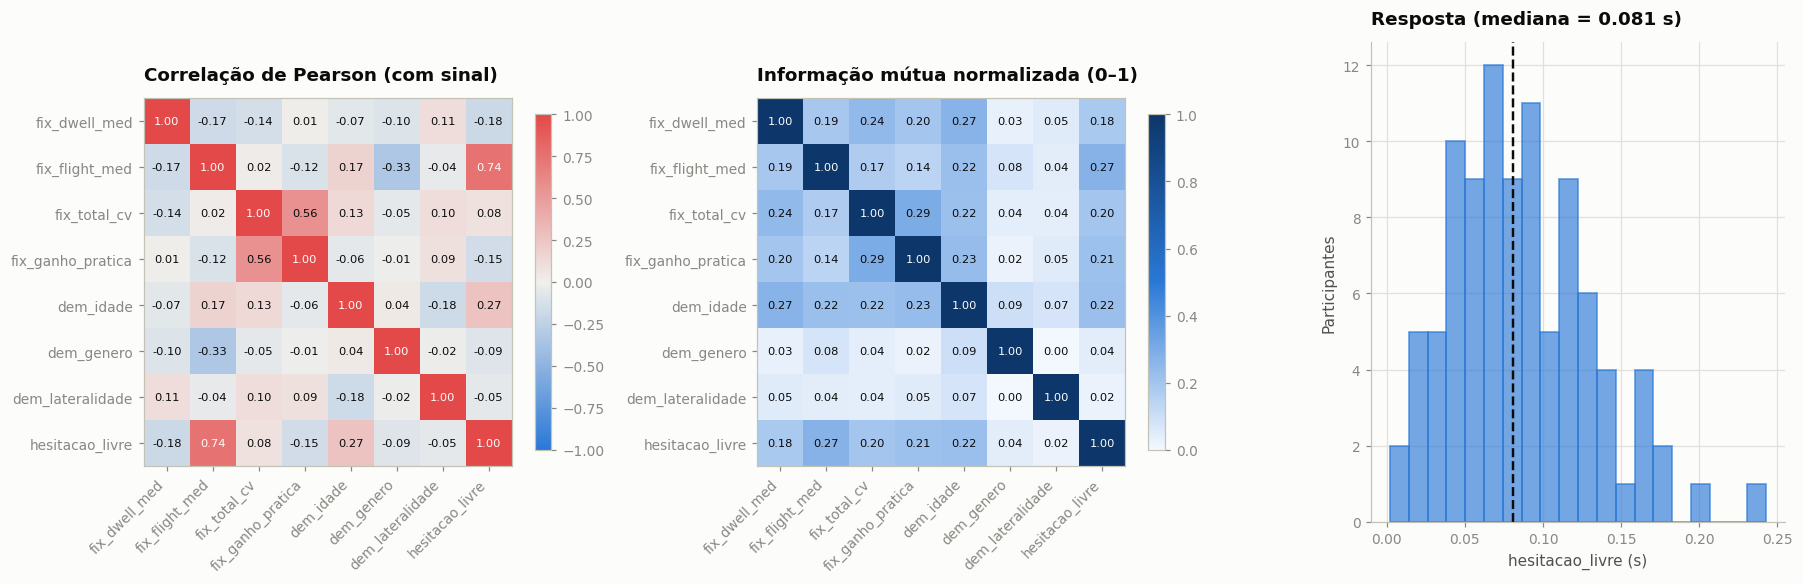

Pares de EXPLICATIVAS com |r| > 0,5 ou NMI > 0,3 (candidatos a combinações irreais nas perturbações):
  fix_total_cv       × fix_ganho_pratica   r = +0.56   NMI = 0.29

Associação de cada explicativa com a RESPOSTA:
                        r    NMI
fix_flight_med     0.7381 0.2726
dem_idade          0.2655 0.2205
fix_ganho_pratica -0.1486 0.2135
fix_total_cv       0.0825 0.1981
fix_dwell_med     -0.1800 0.1801
dem_genero        -0.0885 0.0424
dem_lateralidade  -0.0523 0.0198


In [6]:
# ══ C06 · Dicionário, resposta e dependências ════════════════════════════
from sklearn.metrics import normalized_mutual_info_score

ALVO = "hesitacao_livre"
EXPLICATIVAS = ["fix_dwell_med", "fix_flight_med", "fix_total_cv", "fix_ganho_pratica",
                "dem_idade", "dem_genero", "dem_lateralidade"]

dicionario = pd.DataFrame([
    ["hesitacao_livre", "RESPOSTA", "mediana de DD − dwell(key1) no texto livre", "s"],
    ["fix_dwell_med", "motora", "mediana do tempo de pressionamento (senha)", "s"],
    ["fix_flight_med", "motora", "mediana da pausa entre teclas (senha)", "s"],
    ["fix_total_cv", "motora", "coef. de variação do tempo total da senha (consistência)", "—"],
    ["fix_ganho_pratica", "motora", "(mediana s1 − mediana s2) / mediana s1 (aprendizagem)", "—"],
    ["dem_idade", "demográfica", "idade", "anos"],
    ["dem_genero", "demográfica", "gênero (categórica)", "—"],
    ["dem_lateralidade", "demográfica", "lateralidade (categórica)", "—"],
], columns=["variável", "grupo", "definição", "unidade"])
display(dicionario)


def discretizar_fd(x):
    # Freedman–Diaconis (SLIDE 02): largura h = 2*IQR/n^(1/3); k = ceil((max-min)/h) classes.
    x = np.asarray(x, dtype=float)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    h = 2 * iqr / len(x) ** (1 / 3)
    if not np.isfinite(h) or h <= 0:
        return np.zeros(len(x), dtype=int)
    k = max(int(np.ceil((x.max() - x.min()) / h)), 2)
    return np.digitize(x, np.linspace(x.min(), x.max(), k + 1)[1:-1])


def como_codigos(serie):
    return pd.Categorical(serie).codes if serie.dtype == object else discretizar_fd(serie)


cols_dep = EXPLICATIVAS + [ALVO]
cod = {c: como_codigos(dados[c]) for c in cols_dep}
numerica = {c: (dados[c].astype("category").cat.codes if dados[c].dtype == object else dados[c])
            for c in cols_dep}
M_corr = pd.DataFrame({a: {b: np.corrcoef(numerica[a], numerica[b])[0, 1] for b in cols_dep} for a in cols_dep})
M_nmi = pd.DataFrame({a: {b: normalized_mutual_info_score(cod[a], cod[b]) for b in cols_dep} for a in cols_dep})

cmap_div = mpl.colors.LinearSegmentedColormap.from_list("div", [COR["neg"], COR["meio"], COR["pos"]])
cmap_seq = mpl.colors.LinearSegmentedColormap.from_list("seq", ["#f3f8fe", COR["s1"], "#0d366b"])

fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.4), gridspec_kw={"width_ratios": [1, 1, 0.9]})
for ax, M, cm, vmin, titulo in [(axes[0], M_corr, cmap_div, -1, "Correlação de Pearson (com sinal)"),
                                (axes[1], M_nmi, cmap_seq, 0, "Informação mútua normalizada (0–1)")]:
    im = ax.imshow(M.values, cmap=cm, vmin=vmin, vmax=1)
    ax.set_xticks(range(len(cols_dep))); ax.set_xticklabels(cols_dep, rotation=45, ha="right")
    ax.set_yticks(range(len(cols_dep))); ax.set_yticklabels(cols_dep)
    for i in range(len(cols_dep)):
        for j in range(len(cols_dep)):
            v = M.values[i, j]
            forte = (abs(v) > 0.6) if vmin < 0 else (v > 0.5)
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                    color=COR["superficie"] if forte else COR["tinta"])
    ax.set_title(titulo); ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.7)

ax = axes[2]
ax.hist(dados[ALVO], bins=20, color=COR["s1"], alpha=0.65, edgecolor=COR["s1"], linewidth=1.2)
ax.axvline(dados[ALVO].median(), color=COR["tinta"], linestyle="--", linewidth=1.6)
ax.set_xlabel("hesitacao_livre (s)"); ax.set_ylabel("Participantes")
ax.set_title(f"Resposta (mediana = {dados[ALVO].median():.3f} s)")
limpar_eixos(ax)
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig01_dependencias.png")
plt.show()

print("Pares de EXPLICATIVAS com |r| > 0,5 ou NMI > 0,3 (candidatos a combinações irreais nas perturbações):")
achou = False
for i, a in enumerate(EXPLICATIVAS):
    for b in EXPLICATIVAS[i + 1:]:
        if abs(M_corr.loc[a, b]) > 0.5 or M_nmi.loc[a, b] > 0.3:
            print(f"  {a:<18s} × {b:<18s}  r = {M_corr.loc[a, b]:+.2f}   NMI = {M_nmi.loc[a, b]:.2f}")
            achou = True
if not achou:
    print("  nenhum.")
print("\nAssociação de cada explicativa com a RESPOSTA:")
print(pd.DataFrame({"r": M_corr[ALVO], "NMI": M_nmi[ALVO]}).drop(index=ALVO).sort_values("NMI", ascending=False).to_string())

### C07 · Divisão treino/teste e matriz de desenho

**Objetivo:** fixar o protocolo **idêntico ao da ATV2**:

- **Hold-out de 30%** (`random_state = SEMENTE`) — o **treino** ajusta o modelo e define as distribuições de
  referência dos explicadores (grades do CP, *background* do SHAP, vizinhança do LIME); o **teste** fornece as
  observações a explicar — indivíduos que o modelo **não viu** (como no exemplo do SLIDE 06, p. 42);
- **CV 5×10 repetida** → métrica principal de comparação de modelos (n pequeno → um único split é instável);
- **Categóricas → dummies** com categoria de referência = a mais frequente (o intercepto/baseline descreve esse perfil).

> Como a Random Forest e a árvore são invariantes a escala (SLIDE 04), **só o modelo linear** padroniza as
> contínuas (z-score ajustado no treino). Os explicadores, porém, trabalham sempre na **escala original** — as
> explicações saem em segundos e em unidades de cada variável.

In [7]:
# ══ C07 · Split, desenho e CV ═════════════════════════════════════════════
from sklearn.model_selection import train_test_split, RepeatedKFold

X_bruto = dados[EXPLICATIVAS].copy()
y_bruto = dados[ALVO].copy()
X_tr, X_te, y_tr, y_te = train_test_split(X_bruto, y_bruto, test_size=0.30, random_state=SEMENTE)
cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEMENTE)


def montar_desenho(X, categorias):
    # Dummies com categoria de referência explícita (a mais frequente).
    X = X.copy()
    refs = {}
    for c in X.select_dtypes(include=["object", "category"]).columns:
        cats = categorias[c]
        refs[c] = cats[0]
        X[c] = pd.Categorical(X[c], categories=cats)
    return pd.get_dummies(X, drop_first=True, dtype=float), refs


CATEGORIAS = {c: list(X_bruto[c].value_counts().index) for c in X_bruto.select_dtypes(include=["object"]).columns}
D_tr, referencias = montar_desenho(X_tr, CATEGORIAS)
D_te, _ = montar_desenho(X_te, CATEGORIAS)
D_te = D_te.reindex(columns=D_tr.columns, fill_value=0.0)

COLS = list(D_tr.columns)
COLS_DUM = [c for c in COLS if set(D_tr[c].unique()) <= {0.0, 1.0}]
COLS_CONT = [c for c in COLS if c not in COLS_DUM]
D_all = pd.concat([D_tr, D_te])
y_all = pd.concat([y_tr, y_te])

print(f"Total {len(D_all)}  |  treino {len(D_tr)}  |  teste (hold-out) {len(D_te)}  |  CV 5×10 = {cv.get_n_splits()} ajustes")
print(f"\nColunas do modelo ({len(COLS)}): {COLS}")
print(f"  contínuas : {COLS_CONT}")
print(f"  dummies   : {COLS_DUM}")
print("\nCategorias de REFERÊNCIA (dummy = 0):", referencias)
for c in COLS_DUM:
    print(f"  {c}: {int(D_all[c].sum())} participantes com valor 1 de {len(D_all)}")

Total 96  |  treino 67  |  teste (hold-out) 29  |  CV 5×10 = 50 ajustes

Colunas do modelo (7): ['fix_dwell_med', 'fix_flight_med', 'fix_total_cv', 'fix_ganho_pratica', 'dem_idade', 'dem_genero_Female', 'dem_lateralidade_Left-Handed']
  contínuas : ['fix_dwell_med', 'fix_flight_med', 'fix_total_cv', 'fix_ganho_pratica', 'dem_idade']
  dummies   : ['dem_genero_Female', 'dem_lateralidade_Left-Handed']

Categorias de REFERÊNCIA (dummy = 0): {'dem_genero': 'Male', 'dem_lateralidade': 'Right-Handed'}
  dem_genero_Female: 39 participantes com valor 1 de 96
  dem_lateralidade_Left-Handed: 8 participantes com valor 1 de 96


### C08 · Os modelos: baseline, linear (ATV2), árvore (ATV2) e **Random Forest** (a explicar)

**Objetivo:** ajustar os quatro modelos sob o mesmo protocolo e **medir** o desempenho — porque o SLIDE 01 já
avisou: *"acurácia não é explicação"* e *"o modelo acerta pelos motivos certos?"* só faz sentido perguntar sobre
um modelo cujo desempenho conhecemos.

| Modelo | Papel nesta atividade |
|---|---|
| **Baseline** (mediana do treino) | piso de desempenho |
| **Linear** (OLS, contínuas em z-score) | *explicação exata conhecida* → calibra os métodos post-hoc |
| **Árvore podada** (ATV2, poda custo-complexidade + regra do 1-EP) | terceiro formato de superfície (degraus) para comparar CP |
| **Random Forest** | **o modelo explicado** (caixa-preta) |

Os hiperparâmetros da floresta (`min_samples_leaf`, `max_features`) são escolhidos por **CV interna no treino**;
`n_estimators = 500` fixo. O desempenho comparativo usa a **CV 5×10 sobre os 96 participantes** — ligeiramente
otimista para a floresta (os hiperparâmetros viram parte da seleção), o que declaramos.

Árvore — alpha (1-EP) = 0.000083


Random Forest — melhores hiperparâmetros: {'max_features': 1.0, 'min_samples_leaf': 10}   (RMSE interno 0.0304 s, 26 s)


,RMSE,RMSE_dp,MAE,R2,R2_dp,RMSE_holdout
modelo,,,,,,
Baseline (mediana),0.0450,0.0085,0.0360,-0.1018,0.1329,0.0544
Linear (ATV2),0.0310,0.0047,0.0249,0.4390,0.2028,0.0334
Árvore podada (ATV2),0.0353,0.0065,0.0282,0.2908,0.2658,0.0421
Random Forest,0.0342,0.0058,0.0277,0.3426,0.2015,0.0422


RMSE(Linear (ATV2)) − RMSE(Random Forest): t = -1.24  p = 0.221   (positivo = floresta melhor; diferença NÃO conclusiva)
RMSE(Árvore podada (ATV2)) − RMSE(Random Forest): t = +0.79  p = 0.432   (positivo = floresta melhor; diferença NÃO conclusiva)


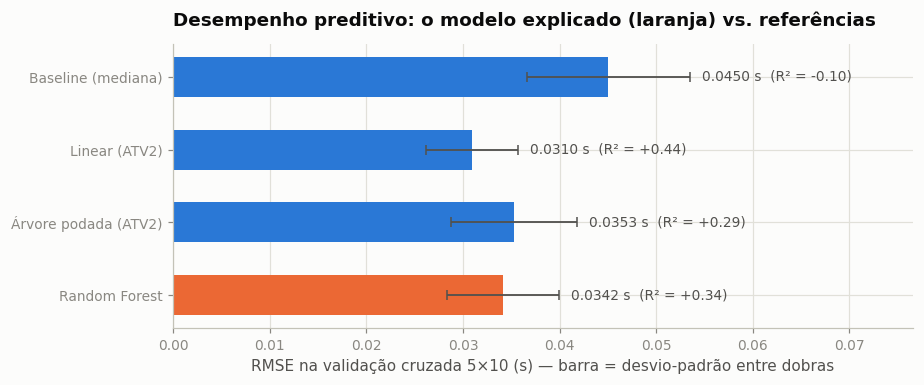

In [8]:
# ══ C08 · Ajuste e desempenho dos modelos ════════════════════════════════
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, cross_val_score, cross_validate


def novo_linear():
    # z-score só nas contínuas; dummies ficam 0/1 (mesma escolha da ATV2). A saída mantém nomes de colunas.
    ct = ColumnTransformer([("z", StandardScaler(), COLS_CONT)], remainder="passthrough",
                           verbose_feature_names_out=False).set_output(transform="pandas")
    return make_pipeline(ct, LinearRegression())


# ── Árvore: poda custo-complexidade, regra do 1-EP (como na ATV2, C27) ───
arv_base = DecisionTreeRegressor(random_state=SEMENTE, min_samples_leaf=10, max_depth=5)
alphas = np.unique(arv_base.cost_complexity_pruning_path(D_tr, y_tr).ccp_alphas.clip(min=0))
poda = []
for a in alphas:
    arv_a = DecisionTreeRegressor(random_state=SEMENTE, min_samples_leaf=10, max_depth=5, ccp_alpha=a)
    sc = cross_val_score(arv_a, D_tr, y_tr, cv=cv, scoring="neg_root_mean_squared_error")
    poda.append({"alpha": a, "folhas": arv_a.fit(D_tr, y_tr).get_n_leaves(),
                 "rmse_cv": -sc.mean(), "ep": sc.std() / np.sqrt(len(sc))})
poda = pd.DataFrame(poda)
i_min = poda["rmse_cv"].idxmin()
cand = poda[poda["rmse_cv"] <= poda.loc[i_min, "rmse_cv"] + poda.loc[i_min, "ep"]]
ALPHA_ARV = float(poda.loc[cand["folhas"].idxmin(), "alpha"])
print(f"Árvore — alpha (1-EP) = {ALPHA_ARV:.6f}")

# ── Random Forest: hiperparâmetros por CV interna no treino ──────────────
t0 = time.time()
busca = GridSearchCV(
    RandomForestRegressor(n_estimators=500, random_state=SEMENTE, n_jobs=1),
    {"min_samples_leaf": [3, 5, 10, 15, 20], "max_features": [0.4, 0.7, 1.0]},
    cv=RepeatedKFold(n_splits=5, n_repeats=2, random_state=SEMENTE),
    scoring="neg_root_mean_squared_error", n_jobs=-1).fit(D_tr, y_tr)
HP_RF = dict(busca.best_params_)
print(f"Random Forest — melhores hiperparâmetros: {HP_RF}   (RMSE interno {-busca.best_score_:.4f} s, "
      f"{time.time()-t0:.0f} s)")


def novo_rf():
    return RandomForestRegressor(n_estimators=500, random_state=SEMENTE, n_jobs=-1, **HP_RF)


def nova_arvore():
    return DecisionTreeRegressor(random_state=SEMENTE, min_samples_leaf=10, max_depth=5, ccp_alpha=ALPHA_ARV)


FABRICAS = {"Baseline (mediana)": lambda: DummyRegressor(strategy="median"),
            "Linear (ATV2)": novo_linear,
            "Árvore podada (ATV2)": nova_arvore,
            "Random Forest": novo_rf}

# ── CV 5×10 sobre os 96 participantes (mesmas dobras para todos) ─────────
linhas, rmse_folds = [], {}
for nome, fab in FABRICAS.items():
    r = cross_validate(fab(), D_all, y_all, cv=cv, n_jobs=1,
                       scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"})
    rmse_folds[nome] = -r["test_rmse"]
    linhas.append({"modelo": nome, "RMSE": -r["test_rmse"].mean(), "RMSE_dp": r["test_rmse"].std(),
                   "MAE": -r["test_mae"].mean(), "R2": r["test_r2"].mean(), "R2_dp": r["test_r2"].std()})
desempenho = pd.DataFrame(linhas).set_index("modelo")

# ── Ajuste final no TREINO e desempenho no hold-out ──────────────────────
modelos = {nome: fab().fit(D_tr, y_tr) for nome, fab in FABRICAS.items()}
rmse_ho = {n: float(np.sqrt(np.mean((y_te - m.predict(D_te)) ** 2))) for n, m in modelos.items()}
desempenho["RMSE_holdout"] = pd.Series(rmse_ho)
display(desempenho)
desempenho.to_csv(DIR_SAIDA / "tabela_desempenho_modelos.csv")

# ── Teste pareado (Nadeau & Bengio, 2003) — dobras de CV não são independentes ──
def teste_corrigido(a, b, razao_te_tr=0.25):
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    t = d.mean() / np.sqrt((1 / k + razao_te_tr) * d.var(ddof=1))
    return t, 2 * stats.t.sf(abs(t), k - 1)


for rival in ["Linear (ATV2)", "Árvore podada (ATV2)"]:
    t, p = teste_corrigido(rmse_folds[rival], rmse_folds["Random Forest"])
    print(f"RMSE({rival}) − RMSE(Random Forest): t = {t:+.2f}  p = {p:.3f}   "
          f"(positivo = floresta melhor; {'diferença NÃO conclusiva' if p > 0.05 else 'diferença significativa'})")

fig, ax = plt.subplots(figsize=(8.5, 3.6))
nomes = list(desempenho.index)[::-1]
ax.barh(range(len(nomes)), desempenho.loc[nomes, "RMSE"], xerr=desempenho.loc[nomes, "RMSE_dp"],
        color=[COR["s2"] if n == "Random Forest" else COR["s1"] for n in nomes], height=0.55,
        error_kw={"ecolor": COR["tinta2"], "capsize": 3, "linewidth": 1.2})
for i, n in enumerate(nomes):
    ax.text(desempenho.loc[n, "RMSE"] + desempenho.loc[n, "RMSE_dp"] + 0.0012, i,
            f"{desempenho.loc[n, 'RMSE']:.4f} s  (R² = {desempenho.loc[n, 'R2']:+.2f})", va="center", fontsize=9,
            color=COR["tinta2"])
ax.set_yticks(range(len(nomes))); ax.set_yticklabels(nomes)
ax.set_xlabel("RMSE na validação cruzada 5×10 (s) — barra = desvio-padrão entre dobras")
ax.set_xlim(0, desempenho["RMSE"].max() * 1.7)
ax.set_title("Desempenho preditivo: o modelo explicado (laranja) vs. referências")
limpar_eixos(ax)
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig02_desempenho_modelos.png")
plt.show()

### C09 · O modelo a explicar, funções de predição e **o que o desempenho permite concluir**

**Objetivo:** fixar os objetos que o resto do notebook usa e registrar, **antes** de qualquer explicação, o que o
desempenho autoriza afirmar.

Todos os métodos (CP, ICE, LIME, SHAP, contrafactuais) consomem **apenas** uma função
$x\mapsto\hat f(x)$ — é o que significa ser *agnóstico ao modelo* (SLIDE 05, p. 4). As funções abaixo aceitam
`DataFrame` **ou** `ndarray` (o LIME e o `KernelExplainer` passam arrays).

**Leitura obrigatória (SLIDE 01):** se o desempenho da floresta for modesto, as explicações descrevem **o que o
modelo aprendeu, inclusive ruído** — não a realidade. Isso não invalida os métodos (eles explicam o *modelo*),
mas limita o que se pode dizer sobre digitação.

In [9]:
# ══ C09 · Modelo explicado e funções de predição ═════════════════════════
rf = modelos["Random Forest"]
lin = modelos["Linear (ATV2)"]
arv = modelos["Árvore podada (ATV2)"]


def como_predict(modelo):
    # Aceita DataFrame ou ndarray; sempre entrega ao modelo um DataFrame com as colunas nomeadas.
    def f(X):
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(np.atleast_2d(X), columns=COLS)
        return np.asarray(modelo.predict(X[COLS]), dtype=float)
    return f


f_rf, f_lin, f_arv = como_predict(rf), como_predict(lin), como_predict(arv)
MODELOS_F = {"Linear (ATV2)": f_lin, "Árvore (ATV2)": f_arv, "Random Forest": f_rf}

BASELINE_RF = float(f_rf(D_tr).mean())          # E[f(X)] sobre o treino — o "baseline" das explicações aditivas
print(f"Random Forest: {rf.n_estimators} árvores   hiperparâmetros = {HP_RF}")
print(f"Predição média no treino (baseline das explicações aditivas) : {BASELINE_RF:.4f} s")
print(f"Média observada no treino                                    : {y_tr.mean():.4f} s")
print(f"Intervalo das predições no hold-out                          : "
      f"[{f_rf(D_te).min():.4f}, {f_rf(D_te).max():.4f}] s  (observado: [{y_te.min():.4f}, {y_te.max():.4f}] s)")

R2_RF, RMSE_RF = desempenho.loc["Random Forest", "R2"], desempenho.loc["Random Forest", "RMSE"]
RMSE_BASE = desempenho.loc["Baseline (mediana)", "RMSE"]
print(f"\nGanho da floresta sobre o baseline: {100*(RMSE_BASE-RMSE_RF)/RMSE_BASE:+.1f}% em RMSE   (R² CV = {R2_RF:+.3f})")
if R2_RF < 0.1:
    print("ALERTA: sinal preditivo muito fraco — as explicações descreverão sobretudo ruído.")
else:
    print("Há sinal preditivo real; as explicações a seguir descrevem estrutura que o modelo de fato usa.")
print("\nSLIDE 01: 'acurácia não é explicação'. Esta tabela só diz QUANTO o modelo acerta — não POR QUÊ.")

Random Forest: 500 árvores   hiperparâmetros = {'max_features': 1.0, 'min_samples_leaf': 10}
Predição média no treino (baseline das explicações aditivas) : 0.0851 s
Média observada no treino                                    : 0.0846 s


Intervalo das predições no hold-out                          : [0.0474, 0.1210] s  (observado: [0.0170, 0.2430] s)

Ganho da floresta sobre o baseline: +24.2% em RMSE   (R² CV = +0.343)
Há sinal preditivo real; as explicações a seguir descrevem estrutura que o modelo de fato usa.

SLIDE 01: 'acurácia não é explicação'. Esta tabela só diz QUANTO o modelo acerta — não POR QUÊ.


---
# §2 · Etapa 2 — Observações de interesse

**Objetivo da seção:** escolher **poucas** observações a explicar e **justificar** a escolha. Duas razões para a
seletividade (SLIDE 01: *"boas explicações são seletivas"*; SLIDE 06: *"declare o indivíduo, a saída e a versão
do modelo"*): (i) uma explicação local só existe para **um** indivíduo — explicar os 96 não é explicar ninguém;
(ii) cada método terá de ser **repetido** (sementes, perturbações, kernels), então o número de casos precisa
ser pequeno.

### Critério

Todas vêm do **hold-out** (indivíduos que o modelo **não viu** no ajuste) e cobrem **situações qualitativamente
diferentes** do comportamento do modelo:

| Obs. | Regra de escolha | Pergunta que ela permite fazer |
|---|---|---|
| **A** | **maior** hesitação *prevista* | *O que empurra o modelo para uma previsão alta?* |
| **B** | **menor** hesitação *prevista* | *O mesmo, para o outro extremo* — e o contraste A × B (explicação **contrastiva**, SLIDE 01) |
| **C** | previsão mais próxima da **mediana** das predições | *Como é uma explicação "sem nada de especial"?* — o caso em que contribuições se cancelam |
| **D** | **maior erro absoluto** (|observado − previsto|) | *Quando o modelo erra feio, a explicação mostra por quê?* — o teste do *Clever Hans* (SLIDE 01) |

> Escolher por **extremos** de previsão (A, B) é deliberado: é onde as explicações têm mais a dizer. Escolher
> também um caso **típico** (C) e um **erro** (D) evita a ilusão de que o método só funciona nos casos fáceis.

### C10 · Seleção e perfil das observações

,participante,observado (s),previsto RF (s),previsto linear (s),resíduo RF (s),percentil da previsão (hold-out)
A,p016,0.0900,0.1210,0.1128,-0.0310,100.0000
B,p092,0.0940,0.0474,0.0634,0.0466,3.4483
C,p031,0.1210,0.0782,0.0613,0.0428,51.7241
D,p041,0.2430,0.1209,0.2880,0.1221,96.5517


Valores das explicativas e posição no treino (percentil):


,A,B,C,D
fix_dwell_med,0.0830,0.0880,0.1360,0.0925
fix_flight_med,0.1875,0.0820,0.1070,0.4780
fix_total_cv,0.3543,0.1842,0.4269,0.3564
fix_ganho_pratica,0.3489,0.0524,0.2734,0.0138
dem_idade,31.0000,21.0000,20.0000,18.0000
dem_genero_Female,1.0000,0.0000,1.0000,1.0000
dem_lateralidade_Left-Handed,0.0000,0.0000,0.0000,0.0000



Percentil no treino (0 = menor valor, 100 = maior):


,A,B,C,D
fix_dwell_med,37.0000,49.0000,93.0000,63.0000
fix_flight_med,88.0000,19.0000,43.0000,100.0000
fix_total_cv,45.0000,1.0000,73.0000,45.0000
fix_ganho_pratica,78.0000,4.0000,55.0000,3.0000
dem_idade,88.0000,45.0000,30.0000,4.0000



Baseline (média das predições no treino): 0.0851 s   |   mediana observada no treino: 0.0810 s


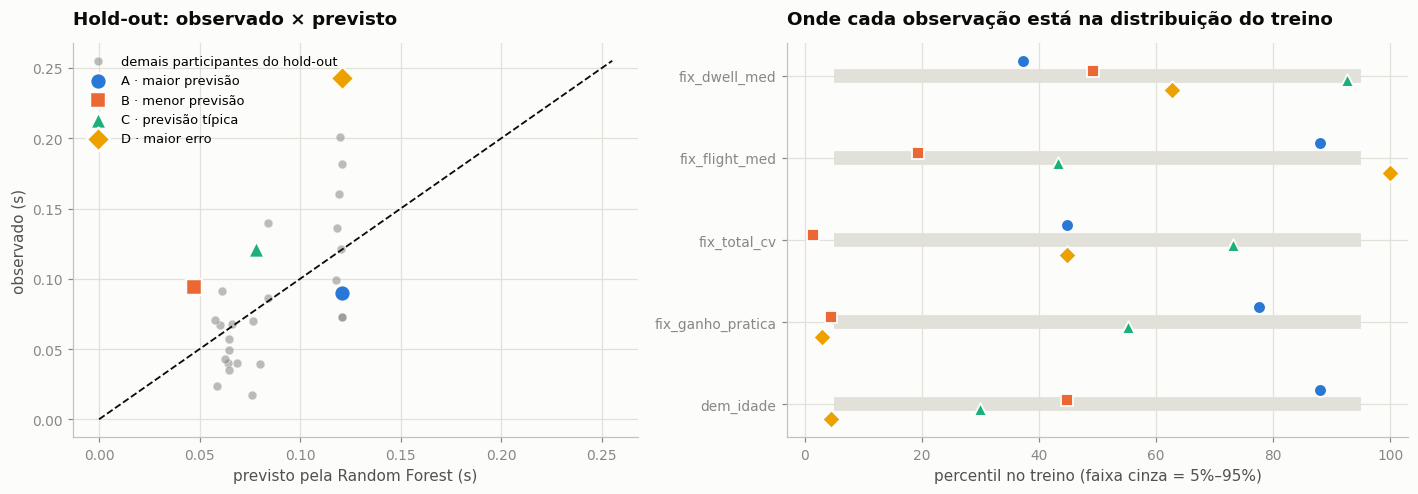

In [10]:
# ══ C10 · Seleção das observações de interesse ═══════════════════════════
pred_te = pd.Series(f_rf(D_te), index=D_te.index)
res_te = y_te - pred_te
med_pred_tr = float(np.median(f_rf(D_tr)))

usados = []


def escolher(serie, criterio):
    pid = criterio(serie.drop(index=usados))
    usados.append(pid)
    return pid


OBS = {"A": escolher(pred_te, lambda s: s.idxmax()),
       "B": escolher(pred_te, lambda s: s.idxmin()),
       "C": escolher(pred_te, lambda s: (s - med_pred_tr).abs().idxmin()),
       "D": escolher(res_te, lambda s: s.abs().idxmax())}
ROTULO = {"A": "A · maior previsão", "B": "B · menor previsão", "C": "C · previsão típica", "D": "D · maior erro"}
ESTILO = {"A": dict(color=COR["s1"], ls="-", marker="o"),
          "B": dict(color=COR["s2"], ls="--", marker="s"),
          "C": dict(color=COR["s3"], ls="-.", marker="^"),
          "D": dict(color=COR["s4"], ls=":", marker="D")}
X_OBS = {k: D_all.loc[pid, COLS].astype(float) for k, pid in OBS.items()}     # Series (uma por observação)

tab_obs = pd.DataFrame({
    "participante": pd.Series(OBS),
    "observado (s)": pd.Series({k: y_all[p] for k, p in OBS.items()}),
    "previsto RF (s)": pd.Series({k: float(f_rf(X_OBS[k].to_frame().T)[0]) for k in OBS}),
    "previsto linear (s)": pd.Series({k: float(f_lin(X_OBS[k].to_frame().T)[0]) for k in OBS}),
})
tab_obs["resíduo RF (s)"] = tab_obs["observado (s)"] - tab_obs["previsto RF (s)"]
tab_obs["percentil da previsão (hold-out)"] = [100 * (pred_te <= tab_obs.loc[k, "previsto RF (s)"]).mean() for k in OBS]
display(tab_obs)

print("Valores das explicativas e posição no treino (percentil):")
perfil = pd.DataFrame({k: X_OBS[k] for k in OBS})
pct_obs = pd.DataFrame({k: [100 * (D_tr[v] <= X_OBS[k][v]).mean() for v in COLS_CONT] for k in OBS}, index=COLS_CONT)
display(perfil)
print("\nPercentil no treino (0 = menor valor, 100 = maior):")
display(pct_obs.round(0))

print(f"\nBaseline (média das predições no treino): {BASELINE_RF:.4f} s   |   mediana observada no treino: {y_tr.median():.4f} s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
ax.scatter(pred_te, y_te, s=34, color=COR["suave"], alpha=0.55, edgecolor=COR["superficie"], linewidth=0.6,
           label="demais participantes do hold-out")
lim = [0, max(pred_te.max(), y_te.max()) * 1.05]
ax.plot(lim, lim, color=COR["tinta"], linewidth=1.2, linestyle="--")
for k, pid in OBS.items():
    ax.scatter(pred_te[pid], y_te[pid], s=120, zorder=4, edgecolor=COR["superficie"], linewidth=1.6,
               color=ESTILO[k]["color"], marker=ESTILO[k]["marker"], label=ROTULO[k])
ax.set_xlabel("previsto pela Random Forest (s)"); ax.set_ylabel("observado (s)")
ax.set_title("Hold-out: observado × previsto")
ax.legend(loc="upper left", fontsize=8.5)
limpar_eixos(ax)

ax = axes[1]
for i, v in enumerate(COLS_CONT):
    ax.hlines(i, 5, 95, color=COR["grade"], linewidth=9, zorder=1)
for k in OBS:
    ax.scatter(pct_obs[k], np.arange(len(COLS_CONT)) + (list(OBS).index(k) - 1.5) * 0.12, s=70, zorder=3,
               edgecolor=COR["superficie"], linewidth=1.2, color=ESTILO[k]["color"], marker=ESTILO[k]["marker"])
ax.set_yticks(range(len(COLS_CONT))); ax.set_yticklabels(COLS_CONT); ax.invert_yaxis()
ax.set_xlim(-3, 103); ax.set_xlabel("percentil no treino (faixa cinza = 5%–95%)")
ax.set_title("Onde cada observação está na distribuição do treino")
limpar_eixos(ax)
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig03_observacoes.png")
plt.show()

---
# §3 · Etapa 3 — CP (*Ceteris Paribus*) e ICE

**Objetivo da seção:** analisar **como alterações em uma variável, mantidas as demais fixas, alteram a predição**
— primeiro para **uma** observação (CP), depois para **todas** (ICE).

Ambos são, na classificação do SLIDE 05: **locais** (explicam um perfil fixado), **post-hoc** (aplicados depois do
ajuste) e **agnósticos** (só precisam de $\hat f$).

### Construção da curva CP (SLIDE 05, p. 8) — o algoritmo, em 4 passos

Para a observação $x^{(i)}=(x^{(i)}_1,\dots,x^{(i)}_p)$ e a variável $x_j$:

1. **definir uma grade** $z_1,\dots,z_K$ de valores para $x_j$;
2. **substituir** $x_j$ por cada $z_k$, **sem alterar** as demais: $x^{(i)}_{x_j:=z_k}=(x^{(i)}_1,\dots,z_k,\dots,x^{(i)}_p)$;
3. **predizer** $\hat f\big(x^{(i)}_{x_j:=z_k}\big)$ para cada $k$;
4. **traçar** $z_k\mapsto\hat f(x^{(i)}_{x_j:=z_k})$ e **destacar** o ponto real $\big(x^{(i)}_j,\hat f(x^{(i)})\big)$.

### Escolha da grade (SLIDE 05, p. 9)

| Grade | Vantagem | Risco |
|---|---|---|
| **Quantis** (tradicional: até 101 pontos) | resolução onde há dados; robusta a extremos | — |
| Intervalo completo (mín–máx) | visão ampla | combinações pouco realistas |
| Intervalo **local** (ao redor do valor do indivíduo) | adequada à explicação local | visão restrita |
| Valores observados | evita regiões sem suporte | grade irregular |

Usamos **quantis** como padrão e comparamos as demais em C15.

### Como ler uma curva CP (SLIDE 05, p. 10)

- **inclinação** = sensibilidade local da predição;  **curvatura** = não linearidade do modelo;
- **patamares/saltos** = regiões em que o modelo responde de forma discreta (típico de árvores);
- **ponto destacado** = valor real do indivíduo.

> ⚠️ **A curva descreve o comportamento do MODELO, não necessariamente uma relação do mundo real** — e, como o
> SLIDE 05 (p. 14) adverte, *variar uma característica mantendo as demais fixas pode criar observações improváveis
> ou impossíveis*. Por isso, cada ponto de cada curva abaixo é **testado quanto ao suporte nos dados** (C11) e
> as regiões sem suporte aparecem **tracejadas**.

### C11 · Implementação do CP e **teste de suporte nos dados**

**Objetivo:** implementar o algoritmo acima do zero e **verificá-lo** de três formas:

1. **Consistência:** a curva, avaliada no valor observado, **tem de devolver exatamente** $\hat f(x^{(i)})$;
2. **Validação cruzada com biblioteca:** as curvas do ICE são comparadas com `sklearn.inspection.partial_dependence`;
3. **Plausibilidade (boas práticas do SLIDE 05):** para cada ponto perturbado calculamos a **distância ao dado de
   treino mais próximo** (no espaço padronizado) e a comparamos com a distribuição das distâncias
   *leave-one-out* entre os próprios dados reais. Pontos além do **percentil 95** dessa distribuição são marcados
   como **"sem suporte"** — operacionaliza a recomendação *"sinalizar regiões com pouco suporte"*.

In [11]:
# ══ C11 · CP do zero + suporte nos dados ═════════════════════════════════
from sklearn.neighbors import NearestNeighbors

MU, SD = D_tr[COLS_CONT].mean(), D_tr[COLS_CONT].std(ddof=0)


def padronizar(X):
    # z-score das contínuas (dummies ficam 0/1). Só serve para MEDIR DISTÂNCIAS (suporte nos dados).
    Z = X[COLS].astype(float).copy()
    Z[COLS_CONT] = (Z[COLS_CONT] - MU) / SD
    return Z.to_numpy()


NN_TREINO = NearestNeighbors(n_neighbors=1).fit(padronizar(D_tr))
d_loo = NearestNeighbors(n_neighbors=2).fit(padronizar(D_tr)).kneighbors(padronizar(D_tr))[0][:, 1]
LIM_SUPORTE = float(np.quantile(d_loo, 0.95))


def dist_ao_treino(X):
    return NN_TREINO.kneighbors(padronizar(X))[0][:, 0]


print(f"Distância ao vizinho mais próximo ENTRE dados reais (leave-one-out, espaço z): "
      f"mediana {np.median(d_loo):.2f}   p95 = {LIM_SUPORTE:.2f}")
print("-> perturbações com distância > p95 são tratadas como 'sem suporte'.\n")


def grade_cp(var, modo="quantis", n=101, x_obs=None):
    # Passo 1 do CP: a grade de valores z_1..z_K.
    v = D_tr[var].to_numpy()
    if var in COLS_DUM:
        g = np.array([0.0, 1.0])
    elif modo == "quantis":
        g = np.unique(np.quantile(v, np.linspace(0, 1, n)))
    elif modo == "completo":
        g = np.linspace(v.min(), v.max(), n)
    elif modo == "p5_p95":
        g = np.linspace(*np.quantile(v, [0.05, 0.95]), n)
    elif modo == "observados":
        g = np.unique(v)
    elif modo == "local":
        g = np.linspace(x_obs - v.std(), x_obs + v.std(), n)
    else:
        raise ValueError(modo)
    return np.union1d(g, [x_obs]) if x_obs is not None else g


def perfil_cp(f, x, var, grade):
    # Passos 2 e 3: substitui x_j por cada z_k (demais fixas) e prediz.
    X = pd.DataFrame(np.tile(x[COLS].to_numpy(float), (len(grade), 1)), columns=COLS)
    X[var] = grade
    return f(X), X


# ── Teste 1: consistência (curva no valor observado == predição) ─────────
erro_max = 0.0
for k, x in X_OBS.items():
    fx = float(f_rf(x.to_frame().T)[0])
    for v in COLS:
        g = grade_cp(v, x_obs=x[v])
        y_cp, _ = perfil_cp(f_rf, x, v, g)
        erro_max = max(erro_max, abs(y_cp[np.argmin(np.abs(g - x[v]))] - fx))
print(f"TESTE 1 — |CP(valor observado) − f(x)|, máximo sobre 4 observações × 7 variáveis: {erro_max:.2e}")
assert erro_max < 1e-10

# ── Teste 3: quanto da grade 'quantis' de cada variável está sem suporte? ─
print("\nTESTE 3 — fração da grade sem suporte nos dados (por observação e variável):")
linhas = []
for k, x in X_OBS.items():
    for v in COLS_CONT:
        g = grade_cp(v, x_obs=x[v])
        _, Xp = perfil_cp(f_rf, x, v, g)
        linhas.append({"obs": k, "variável": v, "% da grade sem suporte": 100 * np.mean(dist_ao_treino(Xp) > LIM_SUPORTE)})
tab_sup = pd.DataFrame(linhas).pivot(index="variável", columns="obs", values="% da grade sem suporte")
display(tab_sup.round(0))

Distância ao vizinho mais próximo ENTRE dados reais (leave-one-out, espaço z): mediana 1.08   p95 = 2.03
-> perturbações com distância > p95 são tratadas como 'sem suporte'.



TESTE 1 — |CP(valor observado) − f(x)|, máximo sobre 4 observações × 7 variáveis: 4.16e-17

TESTE 3 — fração da grade sem suporte nos dados (por observação e variável):


obs,A,B,C,D
variável,,,,
dem_idade,5.0000,0.0000,0.0000,100.0000
fix_dwell_med,0.0000,0.0000,0.0000,100.0000
fix_flight_med,0.0000,0.0000,0.0000,1.0000
fix_ganho_pratica,1.0000,2.0000,2.0000,100.0000
fix_total_cv,0.0000,3.0000,4.0000,100.0000


### C12 · Curvas CP das quatro observações

**Objetivo:** responder, para cada observação, *"como a predição mudaria se **apenas** esta característica
assumisse outros valores?"* (SLIDE 05, p. 3).

**Como ler a figura:** cada painel é **uma variável** (eixo x, na escala original); cada curva é **uma
observação**; o marcador grande é o **valor real** do indivíduo sobre a sua própria curva. O eixo y é a predição
da floresta em segundos, **comum a todos os painéis** — assim a **altura** de cada curva mostra diretamente a
**importância relativa** da variável para aquele indivíduo. Os "tracinhos" na base são os valores reais do treino
(*rug*): onde não há tracinhos, **não há dados**. **Trecho tracejado = sem suporte nos dados** (C11).

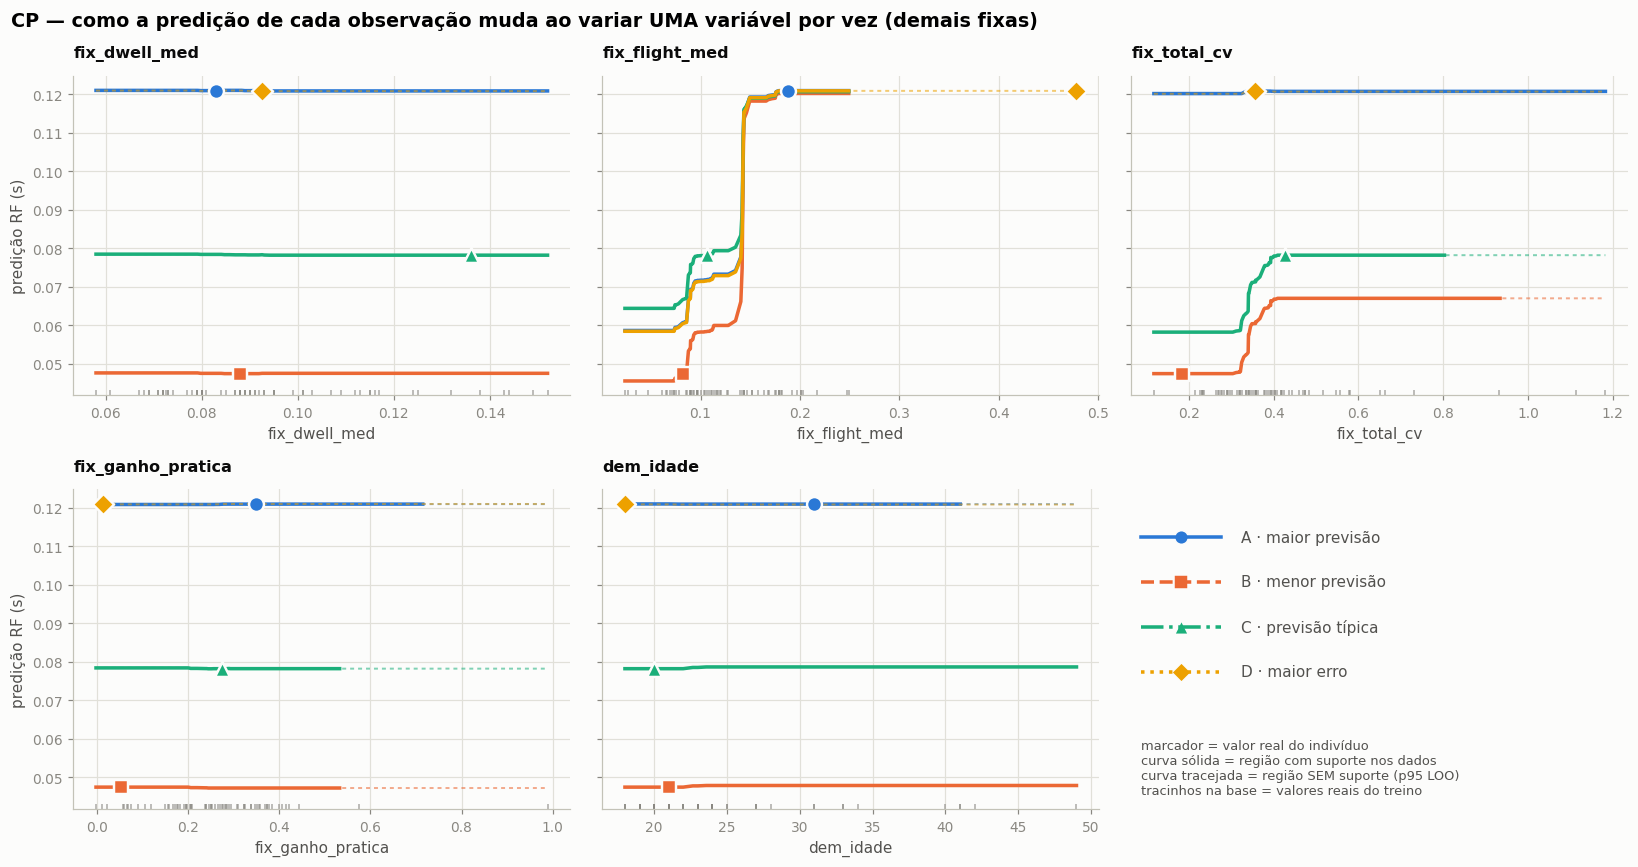

In [12]:
# ══ C12 · CP — 4 observações × 5 variáveis contínuas ═════════════════════
CURVAS_CP = {}      # (obs, var) -> (grade, predição, suporte)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, v in zip(axes.ravel(), COLS_CONT):
    for k, x in X_OBS.items():
        g = grade_cp(v, x_obs=x[v])
        y_cp, Xp = perfil_cp(f_rf, x, v, g)
        sup = dist_ao_treino(Xp) <= LIM_SUPORTE
        CURVAS_CP[(k, v)] = (g, y_cp, sup)
        e = ESTILO[k]
        ax.plot(g, y_cp, color=e["color"], linewidth=1.3, linestyle=(0, (2, 2)), alpha=0.55)          # tudo, tracejado
        ax.plot(g, np.where(sup, y_cp, np.nan), color=e["color"], linewidth=2.3, linestyle="-")       # só o que tem suporte
        ax.scatter([x[v]], [float(f_rf(x.to_frame().T)[0])], s=95, zorder=5, color=e["color"], marker=e["marker"],
                   edgecolor=COR["superficie"], linewidth=1.6)
    ax.plot(D_tr[v], np.zeros(len(D_tr)), "|", transform=ax.get_xaxis_transform(), color=COR["suave"], alpha=0.7, markersize=7)
    ax.set_xlabel(v); ax.set_title(v, fontsize=10.5)
    limpar_eixos(ax)
axes[0, 0].set_ylabel("predição RF (s)"); axes[1, 0].set_ylabel("predição RF (s)")
ax = axes[1, 2]; ax.axis("off")
for i, k in enumerate(OBS):
    e = ESTILO[k]
    ax.plot([0.02, 0.18], [0.85 - i * 0.14] * 2, color=e["color"], linestyle=e["ls"], linewidth=2.3, transform=ax.transAxes)
    ax.scatter([0.10], [0.85 - i * 0.14], s=80, color=e["color"], marker=e["marker"], transform=ax.transAxes, edgecolor=COR["superficie"])
    ax.text(0.22, 0.85 - i * 0.14, ROTULO[k], va="center", transform=ax.transAxes, color=COR["tinta2"])
ax.text(0.02, 0.22, "marcador = valor real do indivíduo\ncurva sólida = região com suporte nos dados\ncurva tracejada = região SEM suporte (p95 LOO)\ntracinhos na base = valores reais do treino",
        transform=ax.transAxes, fontsize=8.5, color=COR["tinta2"], va="top")
fig.suptitle("CP — como a predição de cada observação muda ao variar UMA variável por vez (demais fixas)", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig04_cp_observacoes.png")
plt.show()

### C13 · Quantificando o que os gráficos mostram

**Objetivo:** transformar a leitura visual em números comparáveis. Para cada observação e variável:

- **amplitude CP** = $\max-\min$ da curva **restrita à região com suporte** (quanto a predição pode variar);
- **efeito local por 1 DP** = $\hat f(x_j+\tfrac12\sigma_j)-\hat f(x_j-\tfrac12\sigma_j)$ — a **inclinação local** (SLIDE 05: "sensibilidade local");
- **delta CP** = $\hat f(x)-\hat f(x_{j:=\text{ref}})$, com *ref* = mediana do treino (contínuas) ou categoria de
  referência (dummies): *"quanto a predição desce se esta variável fosse a típica?"* — uma contribuição
  **construída só com CP**, que será comparada com LIME e SHAP na §7.

In [13]:
# ══ C13 · Amplitude, inclinação local e delta CP ═════════════════════════
def ponto_cp(f, x, var, valor):
    X = x[COLS].to_frame().T.astype(float).copy()
    X[var] = valor
    return float(f(X)[0])


REF = {v: float(D_tr[v].median()) if v in COLS_CONT else 0.0 for v in COLS}
linhas = []
for k, x in X_OBS.items():
    fx = float(f_rf(x.to_frame().T)[0])
    for v in COLS:
        if v in COLS_CONT:
            g, y_cp, sup = CURVAS_CP[(k, v)]
            ampl = float(np.nanmax(np.where(sup, y_cp, np.nan)) - np.nanmin(np.where(sup, y_cp, np.nan))) if sup.any() else np.nan
            ef_local = ponto_cp(f_rf, x, v, x[v] + 0.5 * SD[v]) - ponto_cp(f_rf, x, v, x[v] - 0.5 * SD[v])
        else:
            ampl, ef_local = np.nan, np.nan
        linhas.append({"obs": k, "variável": v, "valor": x[v], "amplitude CP (s)": ampl,
                       "efeito local por 1 DP (s)": ef_local, "delta CP vs ref. (s)": fx - ponto_cp(f_rf, x, v, REF[v])})
tab_cp = pd.DataFrame(linhas)
display(tab_cp.pivot(index="variável", columns="obs", values="amplitude CP (s)").loc[COLS_CONT].round(4)
        .style.set_caption("Amplitude CP (s) na região com suporte"))
display(tab_cp.pivot(index="variável", columns="obs", values="efeito local por 1 DP (s)").loc[COLS_CONT].round(4)
        .style.set_caption("Efeito local por 1 DP (s)"))
DELTA_CP = tab_cp.pivot(index="variável", columns="obs", values="delta CP vs ref. (s)").loc[COLS]
display(DELTA_CP.round(4).style.set_caption("Delta CP vs referência (s): f(x) − f(x com a variável no valor de referência)"))
tab_cp.to_csv(DIR_SAIDA / "tabela_cp.csv", index=False)

obs,A,B,C,D
variável,,,,
fix_dwell_med,0.000100,0.000200,0.000300,nan
fix_flight_med,0.062300,0.074700,0.056300,0.062500
fix_total_cv,0.000800,0.019600,0.020000,nan
fix_ganho_pratica,0.000100,0.000200,0.000200,nan
dem_idade,0.000000,0.000400,0.000500,nan


obs,A,B,C,D
variável,,,,
fix_dwell_med,-0.000100,-0.000100,0.000000,-0.000100
fix_flight_med,0.001700,0.012900,0.013800,0.000000
fix_total_cv,0.000600,0.000000,0.015200,0.000600
fix_ganho_pratica,0.000000,0.000000,-0.000200,0.000000
dem_idade,0.000000,0.000400,0.000300,0.000000


obs,A,B,C,D
variável,,,,
fix_dwell_med,0.000000,0.000000,-0.000100,-0.000000
fix_flight_med,0.047700,-0.012500,-0.001200,0.048000
fix_total_cv,0.000000,-0.013500,0.006500,-0.000000
fix_ganho_pratica,0.000100,0.000200,0.000000,-0.000000
dem_idade,0.000000,0.000000,0.000000,0.000000
dem_genero_Female,-0.000000,0.000000,0.000000,-0.000000
dem_lateralidade_Left-Handed,0.000000,0.000000,-0.000000,-0.000000


### C14 · A mesma observação, **três modelos**: linear × árvore × floresta

**Objetivo:** reproduzir a ideia do SLIDE 05, p. 11 — *"duas técnicas podem apresentar desempenhos semelhantes,
mas usar uma variável de maneiras muito diferentes"*:

- **linear:** variação linear;  **árvore:** degraus e regiões constantes;  **floresta:** transições mais graduais.

Usamos a variável de **maior associação com a resposta** (`fix_flight_med`). As três curvas partem da mesma
observação e do mesmo conjunto de dados; só muda o modelo.

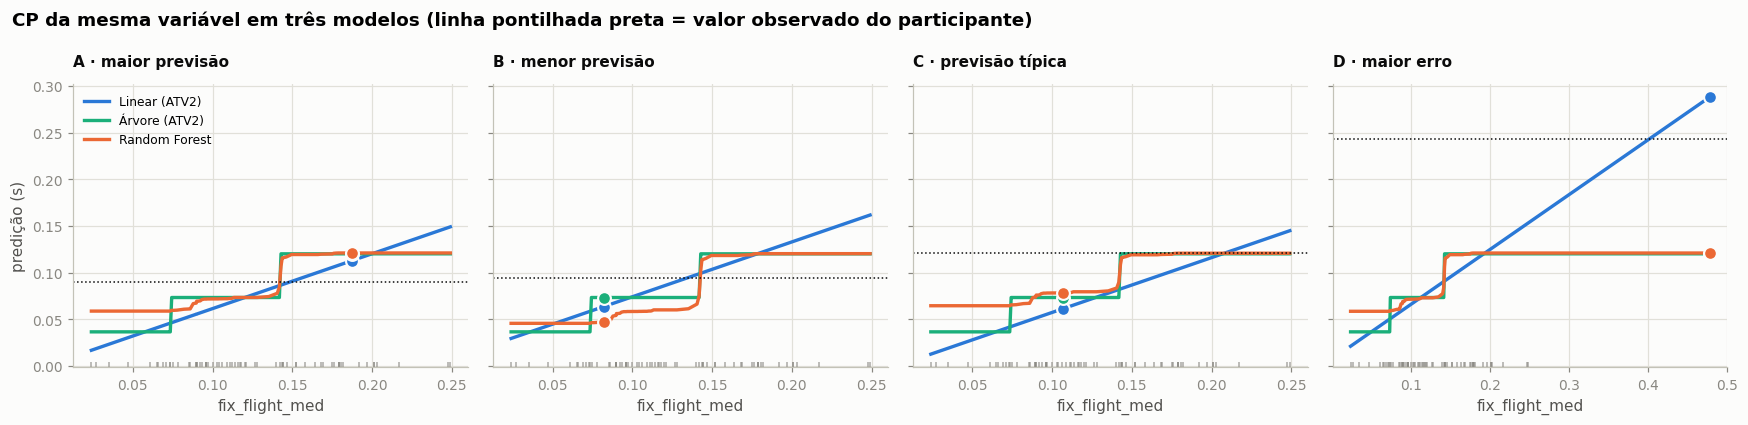

Valores distintos que cada modelo prediz ao longo da grade de fix_flight_med (obs. A):
  Linear (ATV2)   :  95 valores distintos em 96 pontos   amplitude = 0.1324 s
  Árvore (ATV2)   :   3 valores distintos em 96 pontos   amplitude = 0.0837 s
  Random Forest   :  33 valores distintos em 96 pontos   amplitude = 0.0623 s


In [14]:
# ══ C14 · CP de 3 modelos para a mesma variável ══════════════════════════
COR_MOD = {"Linear (ATV2)": COR["s1"], "Árvore (ATV2)": COR["s3"], "Random Forest": COR["s2"]}
VAR_PRINCIPAL = "fix_flight_med"

fig, axes = plt.subplots(1, 4, figsize=(16, 3.9), sharey=True)
for ax, (k, x) in zip(axes, X_OBS.items()):
    g = grade_cp(VAR_PRINCIPAL, x_obs=x[VAR_PRINCIPAL])
    for nome, f in MODELOS_F.items():
        y_cp, _ = perfil_cp(f, x, VAR_PRINCIPAL, g)
        ax.plot(g, y_cp, color=COR_MOD[nome], linewidth=2.2, label=nome)
        ax.scatter([x[VAR_PRINCIPAL]], [float(f(x.to_frame().T)[0])], s=70, color=COR_MOD[nome], zorder=5,
                   edgecolor=COR["superficie"], linewidth=1.4)
    ax.plot(D_tr[VAR_PRINCIPAL], np.zeros(len(D_tr)), "|", transform=ax.get_xaxis_transform(), color=COR["suave"], alpha=0.7, markersize=7)
    ax.axhline(y_all[OBS[k]], color=COR["tinta"], linewidth=1, linestyle=":")
    ax.set_title(ROTULO[k], fontsize=10); ax.set_xlabel(VAR_PRINCIPAL)
    limpar_eixos(ax)
axes[0].set_ylabel("predição (s)")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("CP da mesma variável em três modelos (linha pontilhada preta = valor observado do participante)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig05_cp_tres_modelos.png")
plt.show()

print("Valores distintos que cada modelo prediz ao longo da grade de", VAR_PRINCIPAL, "(obs. A):")
gA = grade_cp(VAR_PRINCIPAL, x_obs=X_OBS["A"][VAR_PRINCIPAL])
for nome, f in MODELOS_F.items():
    yy, _ = perfil_cp(f, X_OBS["A"], VAR_PRINCIPAL, gA)
    print(f"  {nome:<16s}: {len(np.unique(yy.round(8))):>3d} valores distintos em {len(gA)} pontos   amplitude = {yy.max()-yy.min():.4f} s")

### C15 · Sensibilidade à **escolha da grade**

**Objetivo:** o SLIDE 05 (p. 9) lista quatro formas de escolher a grade. Verificamos se a conclusão sobre
`fix_flight_med` na **observação A** depende dessa escolha. Se dependesse, a curva seria um artefato da grade e
não do modelo.

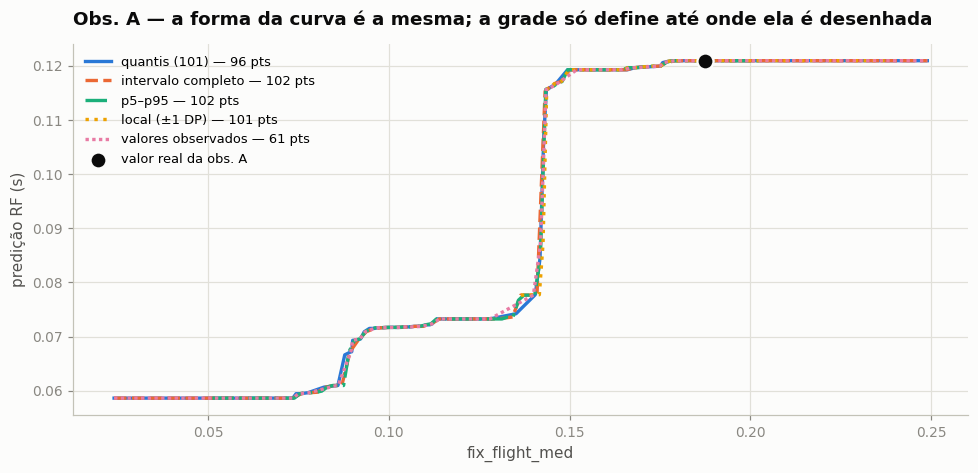

,pontos,min grade,max grade,pred. mín (s),pred. máx (s),% sem suporte
grade,,,,,,
quantis (101),96,0.0240,0.2490,0.0586,0.1210,0.0000
intervalo completo,102,0.0240,0.2490,0.0586,0.1210,0.0000
p5–p95,102,0.0512,0.2024,0.0586,0.1210,0.0000
local (±1 DP),101,0.1366,0.2384,0.0777,0.1210,0.0000
valores observados,61,0.0240,0.2490,0.0586,0.1210,0.0000


In [15]:
# ══ C15 · Quatro grades para a mesma curva CP ════════════════════════════
xA = X_OBS["A"]
grades = {"quantis (101)": "quantis", "intervalo completo": "completo", "p5–p95": "p5_p95",
          "local (±1 DP)": "local", "valores observados": "observados"}
estilos = [(COR["s1"], "-"), (COR["s2"], "--"), (COR["s3"], "-."), (COR["s4"], ":"), (COR["s5"], (0, (1, 1)))]

fig, ax = plt.subplots(figsize=(9, 4.4))
resumo = []
for (nome, modo), (cor, ls) in zip(grades.items(), estilos):
    g = grade_cp(VAR_PRINCIPAL, modo, x_obs=xA[VAR_PRINCIPAL])
    y_cp, Xp = perfil_cp(f_rf, xA, VAR_PRINCIPAL, g)
    ax.plot(g, y_cp, color=cor, linestyle=ls, linewidth=2.2, label=f"{nome} — {len(g)} pts")
    resumo.append({"grade": nome, "pontos": len(g), "min grade": g.min(), "max grade": g.max(),
                   "pred. mín (s)": y_cp.min(), "pred. máx (s)": y_cp.max(),
                   "% sem suporte": 100 * np.mean(dist_ao_treino(Xp) > LIM_SUPORTE)})
ax.scatter([xA[VAR_PRINCIPAL]], [float(f_rf(xA.to_frame().T)[0])], s=110, color=COR["tinta"], zorder=6,
           edgecolor=COR["superficie"], linewidth=1.5, label="valor real da obs. A")
ax.set_xlabel(VAR_PRINCIPAL); ax.set_ylabel("predição RF (s)")
ax.set_title("Obs. A — a forma da curva é a mesma; a grade só define até onde ela é desenhada")
ax.legend(fontsize=8.5, loc="upper left")
limpar_eixos(ax)
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig06_cp_grades.png")
plt.show()
display(pd.DataFrame(resumo).set_index("grade").round(4))

### C16 · CP para variáveis **categóricas** (gênero, lateralidade)

**Objetivo:** para variáveis categóricas, "variar $x_j$" significa **trocar de categoria** (a grade tem só os
níveis existentes). O CP vira uma comparação entre **dois pontos**: a predição com a categoria real do indivíduo
e com a outra, mantendo todo o resto.

In [16]:
# ══ C16 · CP categórico ══════════════════════════════════════════════════
linhas = []
for k, x in X_OBS.items():
    fx = float(f_rf(x.to_frame().T)[0])
    for v in COLS_DUM:
        outro = 1.0 - x[v]
        linhas.append({"obs": k, "variável": v, "categoria real (1=sim)": int(x[v]),
                       "predição real (s)": fx, "predição trocando de categoria (s)": ponto_cp(f_rf, x, v, outro),
                       "variação (s)": ponto_cp(f_rf, x, v, outro) - fx})
tab_cat = pd.DataFrame(linhas)
display(tab_cat.round(4))
print("Amplitude típica de uma troca de categoria:", f"{tab_cat['variação (s)'].abs().median():.4f} s",
      "— compare com a amplitude das variáveis contínuas em C13.")

,obs,variável,categoria real (1=sim),predição real (s),predição trocando de categoria (s),variação (s)
0,A,dem_genero_Female,1,0.1210,0.1210,0.0000
1,A,dem_lateralidade_Left-Handed,0,0.1210,0.1210,0.0000
2,B,dem_genero_Female,0,0.0474,0.0474,0.0000
3,B,dem_lateralidade_Left-Handed,0,0.0474,0.0474,0.0000
4,C,dem_genero_Female,1,0.0782,0.0782,0.0000
5,C,dem_lateralidade_Left-Handed,0,0.0782,0.0782,0.0000
6,D,dem_genero_Female,1,0.1209,0.1209,0.0000
7,D,dem_lateralidade_Left-Handed,0,0.1209,0.1209,0.0000


Amplitude típica de uma troca de categoria: 0.0000 s — compare com a amplitude das variáveis contínuas em C13.


### Interpretação — CP

**1. A floresta responde, na prática, a uma única variável — com uma segunda entrando em um trecho.**
As curvas de `fix_dwell_med`, `fix_ganho_pratica`, `dem_idade` são **horizontais** nas quatro observações
(amplitude ≤ 0,0005 s), contra **0,056–0,075 s** de `fix_flight_med`. Trocar a categoria de gênero ou de lateralidade
**não altera a predição em nenhum dos 8 casos testados (variação exatamente 0)**: a floresta nunca divide por elas.
É o oposto do modelo linear da ATV2, que atribui a `dem_genero_Female` um coeficiente de −0,013 s.

**2. `fix_flight_med`: um degrau, não uma reta.** A predição fica em patamares de ≈ 0,045–0,07 s e **salta para
≈ 0,115–0,12 s em torno de 0,14 s**; acima disso, **satura** (não sobe mais, mesmo com flight de 0,48 s). Consequências
que a figura torna visíveis e que um único coeficiente esconderia:

- a **amplitude** CP (≈ 0,06 s) é grande para as quatro observações, mas a **sensibilidade local** de A e D é
  **≈ 0** (efeito por 1 DP = 0,0017 e 0,0000 s): elas já estão **no patamar superior**. Para B e C, abaixo do degrau,
  o efeito local é 0,013–0,014 s por DP. *Amplitude e inclinação local respondem a perguntas diferentes* (SLIDE 05, p. 10);
- `fix_total_cv` tem seu próprio degrau (≈ 0,33) e **só importa para B e C** (amplitude 0,020 s; para A, 0,0008 s; em
  D nenhum trecho da curva tem suporte): quem já está no teto de `flight` não tem mais "espaço" para `cv` mover a predição — um indício de **interação**
  que o ICE vai quantificar.

**3. A observação D mostra o limite do CP.** Com `fix_flight_med = 0,478 s` (o treino chega a 0,249 s), **100% da grade
de quatro das cinco variáveis está sem suporte** (C11): o indivíduo é um *outlier* na distribuição conjunta. A curva
diz o que o modelo faz **ali** — prever 0,121 s, o teto da floresta — mas o observado é **0,243 s**. O CP **não explica o
erro**; ele apenas revela que o modelo **não tem como prever** esse valor (a floresta **não extrapola**; o linear,
sim, e prevê 0,288 s).

**4. Três modelos, três usos da mesma variável (C14).** Para a obs. A, a curva do **linear** tem 95 valores distintos
e amplitude de 0,132 s (reta que extrapola); a **árvore**, 3 valores (degraus, 0,084 s); a **floresta**, 33 valores
(degraus suavizados, 0,062 s). Desempenhos semelhantes (RMSE 0,031–0,035 s) escondem **comportamentos muito diferentes** —
exatamente a mensagem do SLIDE 05, p. 11.

**5. A escolha da grade não altera a forma (C15).** Quantis, intervalo completo, p5–p95 e valores observados dão a mesma
curva (predição entre 0,0586 e 0,121 s); a grade **local** (±1 DP) mostra só um recorte (0,078–0,121 s) — por isso
**a grade deve ser declarada junto com a curva**.

**6. O delta CP depende da referência (C13).** Para C, `fix_flight_med` tem delta CP de apenas −0,0012 s: a **mediana**
do treino (0,119 s) cai **no mesmo patamar** que o valor de C (0,107 s). Já em B o delta é −0,0125 s. O delta CP é
"contribuição **em relação a um ponto**"; veremos na §7 que o SHAP, que usa a **média sobre os dados**, dá −0,0139 s para
o mesmo caso.

> **Ressalva (SLIDE 05, p. 14):** tudo acima descreve o **comportamento do modelo**, não uma relação de digitação.
> `flight` da senha e `flight` do texto livre são **construtos próximos** (pausas entre teclas); o degrau em 0,14 s é uma
> propriedade desta floresta e desta amostra de 96 pessoas.

---
## ICE — *Individual Conditional Expectation*

### O que o ICE acrescenta ao CP (SLIDE 05, pp. 18–29)

O ICE é, **fundamentalmente, o conjunto de todas as curvas CP de um conjunto de dados reunidas em um único
gráfico** — uma linha por instância. Cada curva continua sendo **individual e local** ao perfil fixado
(SLIDE 05, p. 31); o conjunto permite investigar **heterogeneidade** no nível da amostra:

- curvas **aproximadamente paralelas** → o efeito da variável é parecido para todos (pouca interação);
- curvas que **se cruzam / divergem** → o efeito **depende** das outras variáveis (**interação**).

Quatro variantes que o slide apresenta e que usamos:

| Variante | Definição | Para que serve |
|---|---|---|
| **ICE** | $\hat f(x_j, x_{-j}^{(i)})$ | ver cada instância |
| **PDP** | média das curvas ICE | o efeito **médio** (difícil de enxergar só no ICE) |
| **c-ICE** | $\hat f(x_j,x_{-j}^{(i)})-\hat f(a,x_{-j}^{(i)})$ | **centraliza** em um ponto de ancoragem $a$ para comparar **formas** |
| **d-ICE** | $\partial\hat f/\partial x_j$ (diferenças finitas) | derivada individual; **se as derivadas diferem entre indivíduos, há interação** |

Cuidados que o slide registra e que seguimos: **(i)** só **uma** variável por vez; **(ii)** as curvas sofrem com
**correlação** entre variáveis (combinações fora da distribuição conjunta); **(iii)** com muitas linhas, usar
**transparência**; **(iv)** o d-ICE é **sensível à grade e instável** em modelos não suaves (árvores e
*ensembles* de árvores — exatamente o nosso caso).

### C17 · ICE de todos os 96 participantes + PDP, **validado contra o scikit-learn**

**Objetivo:** calcular o ICE para as cinco contínuas, sobrepor o **PDP** e destacar as quatro observações da §2.
Antes, **validamos a nossa implementação**: as matrizes ICE devem coincidir com
`sklearn.inspection.partial_dependence(kind="individual")` na mesma grade.

VALIDAÇÃO — máx |ICE (nosso) − ICE (scikit-learn)| sobre as 5 variáveis, 96 curvas cada: 6.94e-17


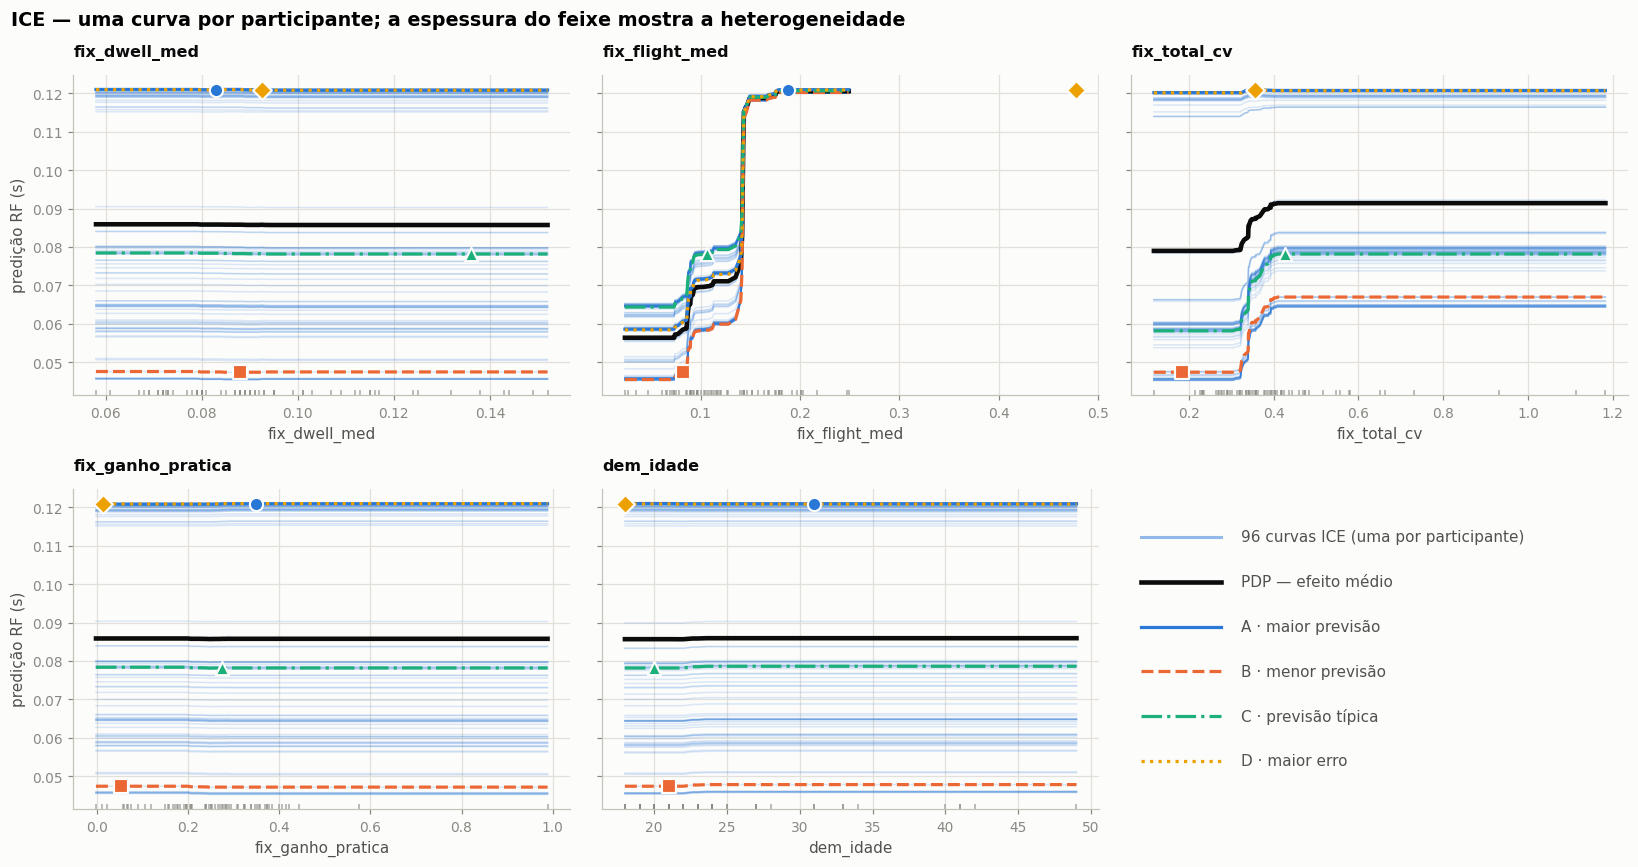

In [17]:
# ══ C17 · ICE (do zero) + validação contra scikit-learn ══════════════════
from sklearn.inspection import partial_dependence


def ice_matriz(f, X, var, grade):
    # Uma linha por instância, uma coluna por ponto da grade: ICE[i, k] = f(x_i com x_j := z_k).
    n, G = len(X), len(grade)
    Xr = X[COLS].iloc[np.repeat(np.arange(n), G)].copy()
    Xr[var] = np.tile(grade, n)
    return f(Xr).reshape(n, G)


GRADE_ICE = {v: grade_cp(v, "quantis") for v in COLS_CONT}
ICE = {v: ice_matriz(f_rf, D_all, v, GRADE_ICE[v]) for v in COLS_CONT}
PDP = {v: ICE[v].mean(axis=0) for v in COLS_CONT}

# ── Validação cruzada com a biblioteca ───────────────────────────────────
dif_max = 0.0
for v in COLS_CONT:
    # O scikit-learn escolhe a PRÓPRIA grade; avaliamos o nosso ICE exatamente nela e comparamos curva a curva.
    r = partial_dependence(rf, D_all[COLS], [v], kind="individual", percentiles=(0.0, 1.0), grid_resolution=40)
    grade_sk = np.asarray(r["grid_values"][0] if "grid_values" in r else r["values"][0])
    dif_max = max(dif_max, float(np.abs(r["individual"][0] - ice_matriz(f_rf, D_all, v, grade_sk)).max()))
print(f"VALIDAÇÃO — máx |ICE (nosso) − ICE (scikit-learn)| sobre as 5 variáveis, 96 curvas cada: {dif_max:.2e}")
assert dif_max < 1e-9

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, v in zip(axes.ravel(), COLS_CONT):
    g = GRADE_ICE[v]
    for i in range(len(D_all)):
        ax.plot(g, ICE[v][i], color=COR["s1"], alpha=0.16, linewidth=1)
    ax.plot(g, PDP[v], color=COR["tinta"], linewidth=3, label="PDP (média das curvas)", zorder=4)
    for k, x in X_OBS.items():
        i = list(D_all.index).index(OBS[k])
        ax.plot(g, ICE[v][i], color=ESTILO[k]["color"], linewidth=2.1, linestyle=ESTILO[k]["ls"], zorder=5)
        ax.scatter([x[v]], [float(f_rf(x.to_frame().T)[0])], s=75, zorder=6, color=ESTILO[k]["color"],
                   marker=ESTILO[k]["marker"], edgecolor=COR["superficie"], linewidth=1.4)
    ax.plot(D_tr[v], np.zeros(len(D_tr)), "|", transform=ax.get_xaxis_transform(), color=COR["suave"], alpha=0.7, markersize=7)
    ax.set_xlabel(v); ax.set_title(v, fontsize=10.5)
    limpar_eixos(ax)
axes[0, 0].set_ylabel("predição RF (s)"); axes[1, 0].set_ylabel("predição RF (s)")
ax = axes[1, 2]; ax.axis("off")
ax.plot([0.02, 0.18], [0.85] * 2, color=COR["s1"], alpha=0.5, linewidth=2, transform=ax.transAxes)
ax.text(0.22, 0.85, "96 curvas ICE (uma por participante)", va="center", transform=ax.transAxes, color=COR["tinta2"])
ax.plot([0.02, 0.18], [0.71] * 2, color=COR["tinta"], linewidth=3, transform=ax.transAxes)
ax.text(0.22, 0.71, "PDP — efeito médio", va="center", transform=ax.transAxes, color=COR["tinta2"])
for i, k in enumerate(OBS):
    ax.plot([0.02, 0.18], [0.57 - i * 0.14] * 2, color=ESTILO[k]["color"], linestyle=ESTILO[k]["ls"], linewidth=2.1, transform=ax.transAxes)
    ax.text(0.22, 0.57 - i * 0.14, ROTULO[k], va="center", transform=ax.transAxes, color=COR["tinta2"])
fig.suptitle("ICE — uma curva por participante; a espessura do feixe mostra a heterogeneidade", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig07_ice.png")
plt.show()

### C18 · c-ICE — comparando **formas** em vez de níveis

**Objetivo:** no ICE, curvas que partem de predições iniciais diferentes dificultam comparar o *formato*. O c-ICE
subtrai de cada curva o seu valor no **ponto de ancoragem** $a$ (SLIDE 05, p. 24). Escolhemos $a$ = **percentil 5**
do treino de cada variável (em vez do mínimo, que é um valor raro e instável). Todas as curvas passam por zero em
$a$; a **dispersão** das curvas à direita mede a **heterogeneidade do efeito**.

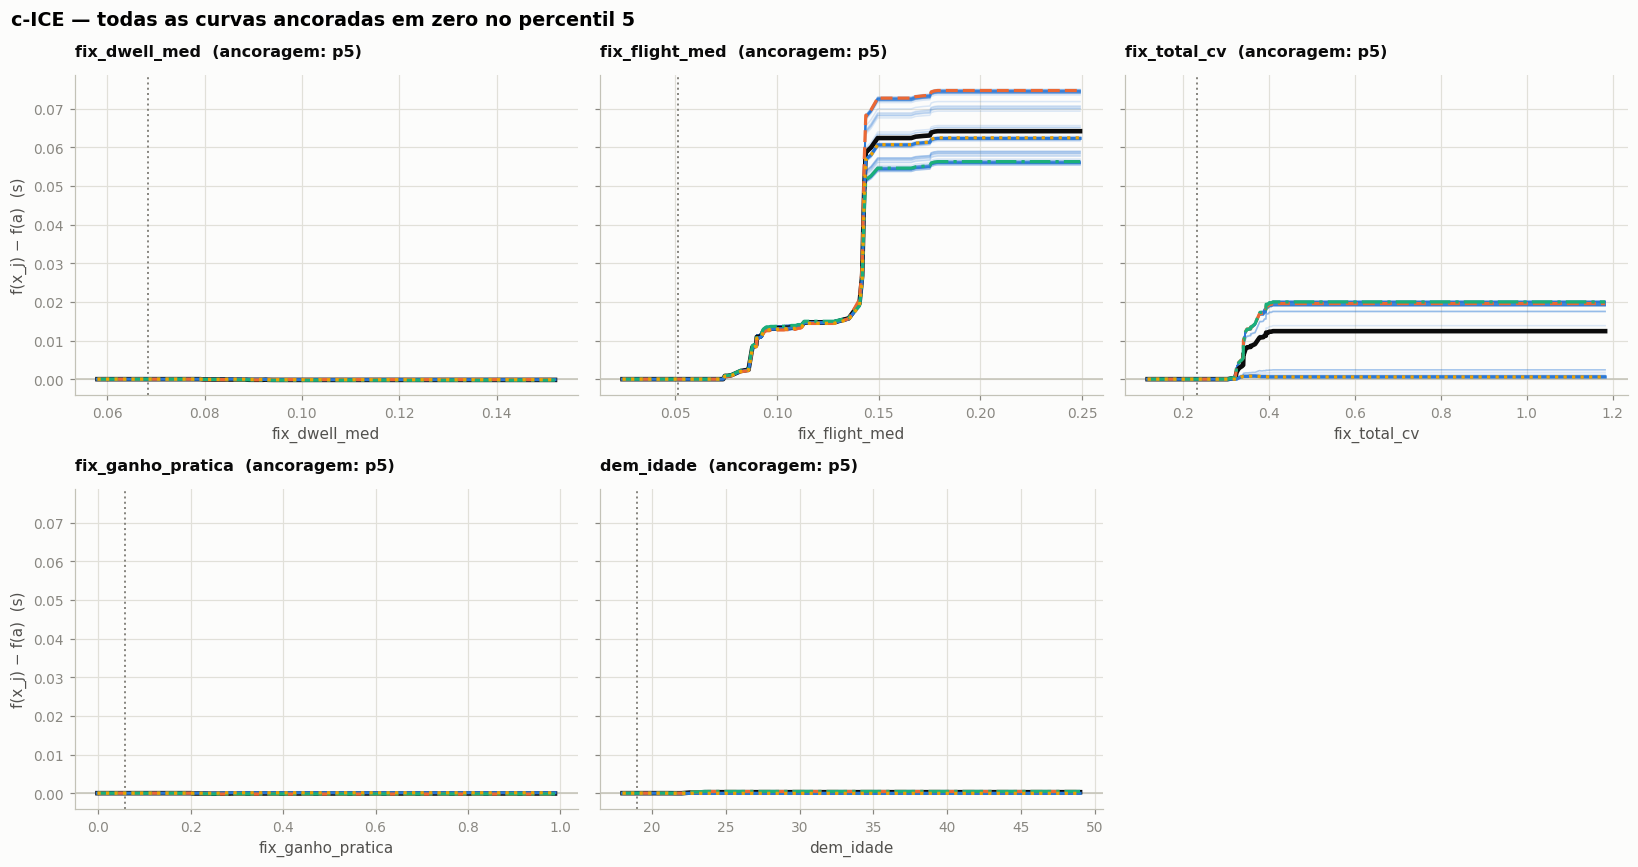

In [18]:
# ══ C18 · c-ICE ══════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, v in zip(axes.ravel(), COLS_CONT):
    g = GRADE_ICE[v]
    ia = int(np.argmin(np.abs(g - np.quantile(D_tr[v], 0.05))))
    C = ICE[v] - ICE[v][:, [ia]]
    for i in range(len(D_all)):
        ax.plot(g, C[i], color=COR["s1"], alpha=0.16, linewidth=1)
    ax.plot(g, C.mean(axis=0), color=COR["tinta"], linewidth=3, zorder=4)
    for k, x in X_OBS.items():
        i = list(D_all.index).index(OBS[k])
        ax.plot(g, C[i], color=ESTILO[k]["color"], linewidth=2.1, linestyle=ESTILO[k]["ls"], zorder=5)
    ax.axvline(g[ia], color=COR["suave"], linestyle=":", linewidth=1.3)
    ax.axhline(0, color=COR["eixo"], linewidth=1)
    ax.set_xlabel(v); ax.set_title(f"{v}  (ancoragem: p5)", fontsize=10.5)
    limpar_eixos(ax)
axes[0, 0].set_ylabel("f(x_j) − f(a)  (s)"); axes[1, 0].set_ylabel("f(x_j) − f(a)  (s)")
axes[1, 2].axis("off")
fig.suptitle("c-ICE — todas as curvas ancoradas em zero no percentil 5", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig08_cice.png")
plt.show()

### C19 · Quantificando a heterogeneidade: **índice de não-paralelismo** e d-ICE

**Objetivo:** "curvas paralelas" e "curvas que divergem" são juízos visuais. Aqui os tornamos um número.

Se **não há interação** entre $x_j$ e as demais variáveis, o modelo é aditivo nessa direção,
$\hat f(x)=g(x_j)+h(x_{-j})$ (SLIDE 05, p. 27), e **todas as curvas ICE são cópias deslocadas uma da outra**:
$\mathrm{ICE}_{ik}=a_i+g(z_k)$. Medimos o quanto isso é violado com

$$U_j \;=\; \frac{\sum_{i,k}\big(\mathrm{ICE}_{ik}-\overline{\mathrm{ICE}}_{i\cdot}-\mathrm{PDP}_k+\overline{\mathrm{PDP}}\big)^2}{\sum_{i,k}\big(\mathrm{ICE}_{ik}-\overline{\mathrm{ICE}}_{i\cdot}\big)^2}\in[0,1]$$

— a **fração da variação ao longo de $x_j$ que é específica de cada indivíduo** (e não comum a todos).
$U_j=0$ ⇒ curvas perfeitamente paralelas. Como $U_j$ é **relativo** (uma variável com efeito minúsculo pode ter $U_j$
alto sem importância prática), reportamos também $H_j$, o **tamanho absoluto em segundos** da parte não paralela
(raiz do erro quadrático médio do numerador), e a **amplitude do PDP** (o efeito médio). **Sanidade:** para o
**modelo linear** (aditivo por construção) $U_j$ e $H_j$ devem ser **zero**; é o nosso *controle negativo*.

O **d-ICE** (derivada individual por diferenças finitas) é mostrado para as duas variáveis de maior $U_j$.
Lembrete do slide: ele é **instável** em florestas (superfície em degraus), então lemos a **tendência**, não os
picos.

modelo,Linear (ATV2),Random Forest,Árvore (ATV2)
variável,,,
dem_idade,0.000000,0.428400,1.000000
fix_dwell_med,0.000000,0.223400,nan
fix_flight_med,0.000000,0.021100,0.000000
fix_ganho_pratica,0.000000,0.709800,0.386300
fix_total_cv,0.000000,0.345400,0.386300


modelo,Linear (ATV2),Random Forest,Árvore (ATV2)
variável,,,
dem_idade,0.000000,0.000100,0.000000
fix_dwell_med,0.000000,0.000000,0.000000
fix_flight_med,0.000000,0.003900,0.000000
fix_ganho_pratica,0.000000,0.000100,0.000000
fix_total_cv,0.000000,0.004000,0.000000


,amplitude do PDP (s),H (s),U (fração)
variável,,,
fix_dwell_med,0.000200,0.000000,0.223400
fix_flight_med,0.064200,0.003900,0.021100
fix_total_cv,0.012400,0.004000,0.345400
fix_ganho_pratica,0.000100,0.000100,0.709800
dem_idade,0.000300,0.000100,0.428400


Controle negativo — modelo linear: U máximo = 1.43e-28  (deve ser ~0)

Variáveis de maior heterogeneidade ABSOLUTA na floresta: ['fix_total_cv', 'fix_flight_med']


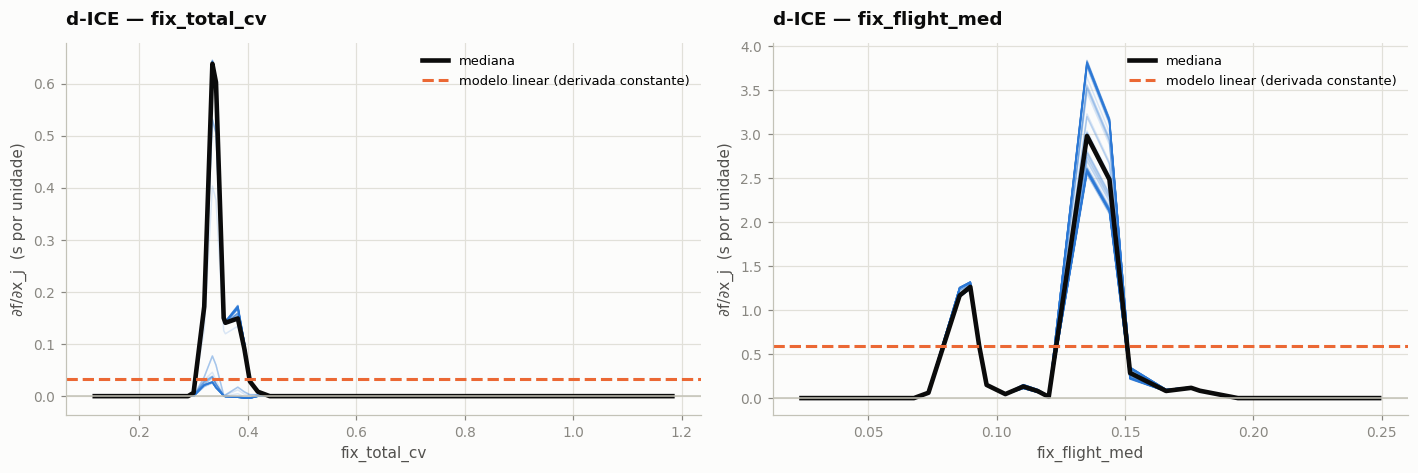

In [19]:
# ══ C19 · Índice de não-paralelismo U_j e d-ICE ══════════════════════════
def nao_paralelismo(M):
    # Devolve (U, H): U relativo (fração), H absoluto (raiz do erro quadrático médio da parte não aditiva, em s).
    centro_i = M.mean(axis=1, keepdims=True)
    pdp = M.mean(axis=0, keepdims=True)
    interacao = M - centro_i - pdp + M.mean()
    den = ((M - centro_i) ** 2).sum()
    return (float((interacao ** 2).sum() / den) if den > 0 else np.nan), float(np.sqrt((interacao ** 2).mean()))


linhas = []
for nome, f in MODELOS_F.items():
    for v in COLS_CONT:
        M = ice_matriz(f, D_all, v, GRADE_ICE[v])
        u, h = nao_paralelismo(M)
        linhas.append({"modelo": nome, "variável": v, "U (fração)": u, "H (s)": h,
                       "amplitude do PDP (s)": float(M.mean(axis=0).max() - M.mean(axis=0).min())})
tab_U = pd.DataFrame(linhas)
display(tab_U.pivot(index="variável", columns="modelo", values="U (fração)").round(4)
        .style.set_caption("U_j — fração da variação que é específica de cada indivíduo (0 = curvas paralelas; NaN = variável não usada)"))
display(tab_U.pivot(index="variável", columns="modelo", values="H (s)").round(4)
        .style.set_caption("H_j — tamanho absoluto (s) da parte não paralela das curvas"))
display(tab_U[tab_U["modelo"] == "Random Forest"].set_index("variável")[["amplitude do PDP (s)", "H (s)", "U (fração)"]].round(4)
        .style.set_caption("Floresta: efeito médio (PDP) vs. heterogeneidade"))
print(f"Controle negativo — modelo linear: U máximo = {tab_U[tab_U['modelo']=='Linear (ATV2)']['U (fração)'].max():.2e}  (deve ser ~0)")
assert tab_U[tab_U["modelo"] == "Linear (ATV2)"]["H (s)"].max() < 1e-12
tab_U.to_csv(DIR_SAIDA / "tabela_nao_paralelismo.csv", index=False)

# U é relativo: uma variável quase sem efeito pode ter U alto sem importar. Ordenamos pelo tamanho ABSOLUTO (H).
top2 = list(tab_U[tab_U["modelo"] == "Random Forest"].sort_values("H (s)", ascending=False)["variável"][:2])
print(f"\nVariáveis de maior heterogeneidade ABSOLUTA na floresta: {top2}")

# ── d-ICE em grade mais grossa (21 quantis) para reduzir o ruído de diferenças finitas ──
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=False)
for ax, v in zip(axes, top2):
    g = np.unique(np.quantile(D_tr[v], np.linspace(0, 1, 21)))
    M = ice_matriz(f_rf, D_all, v, g)
    d = np.gradient(M, g, axis=1)
    mid = g
    for i in range(len(D_all)):
        ax.plot(mid, d[i], color=COR["s1"], alpha=0.16, linewidth=1)
    ax.plot(mid, np.median(d, axis=0), color=COR["tinta"], linewidth=3, label="mediana")
    beta_lin = float(lin[-1].coef_[COLS_CONT.index(v)] / SD[v])      # β_z / σ: derivada constante, em s por unidade de x_j
    ax.axhline(beta_lin, color=COR["s2"], linestyle="--", linewidth=2, label="modelo linear (derivada constante)")
    ax.axhline(0, color=COR["eixo"], linewidth=1)
    ax.set_xlabel(v); ax.set_ylabel("∂f/∂x_j  (s por unidade)")
    ax.set_title(f"d-ICE — {v}")
    ax.legend(fontsize=8.5)
    limpar_eixos(ax)
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig09_dice.png")
plt.show()

### C20 · Explorando **interações** com ICE colorido

**Objetivo:** seguindo o SLIDE 05 (pp. 20–21), **colorir as curvas ICE pelo valor de outra variável** para
descobrir *com quem* a variável de maior $U_j$ interage. Em vez de escolher a variável de cor "no olho", usamos um
critério: calculamos a **inclinação** de cada curva entre os percentis 10 e 90 e escolhemos como parceira a variável
cujo valor mais se **correlaciona (Spearman)** com a inclinação. Se nenhuma se correlaciona, o feixe é heterogêneo
mas sem parceira clara.

**Cuidado do slide:** ao interpretar, olhar a distribuição conjunta — regiões raras (poucos indivíduos) não
sustentam conclusões.

,Spearman com a inclinação,p-valor
fix_flight_med,-0.688000,0.000000
dem_genero_Female,-0.167000,0.103800
dem_idade,-0.131700,0.201000
fix_dwell_med,0.110800,0.282500
fix_ganho_pratica,-0.066500,0.519500
dem_lateralidade_Left-Handed,-0.017700,0.864100


Parceira de interação escolhida (maior |ρ|): fix_flight_med   ρ = -0.688   p = 0.0000


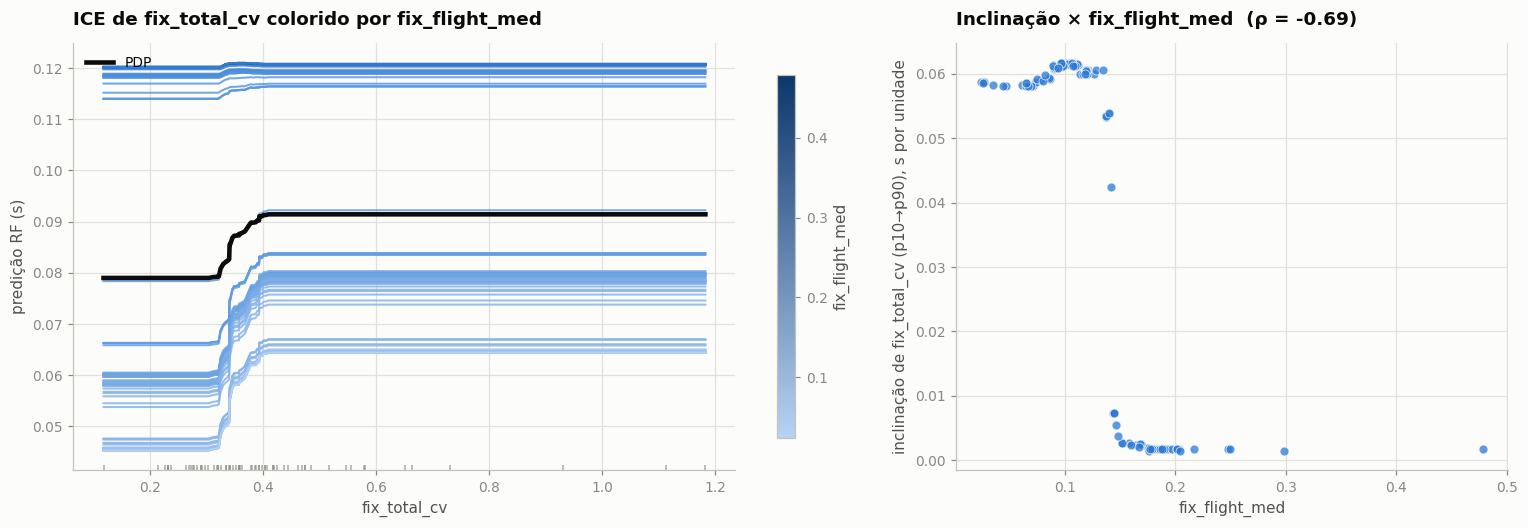

In [20]:
# ══ C20 · ICE colorido pela variável parceira ════════════════════════════
VAR_INT = top2[0]
g = GRADE_ICE[VAR_INT]
ia, ib = int(np.argmin(np.abs(g - np.quantile(D_tr[VAR_INT], 0.10)))), int(np.argmin(np.abs(g - np.quantile(D_tr[VAR_INT], 0.90))))
inclin = (ICE[VAR_INT][:, ib] - ICE[VAR_INT][:, ia]) / (g[ib] - g[ia])

parceiras = pd.DataFrame({p: {"Spearman com a inclinação": stats.spearmanr(D_all[p], inclin)[0],
                              "p-valor": stats.spearmanr(D_all[p], inclin)[1]}
                          for p in COLS if p != VAR_INT}).T.sort_values("Spearman com a inclinação", key=abs, ascending=False)
display(parceiras.round(4).style.set_caption(f"Quem modula a inclinação de {VAR_INT} entre p10 e p90?"))
PARCEIRA = parceiras.index[0]
print(f"Parceira de interação escolhida (maior |ρ|): {PARCEIRA}   ρ = {parceiras.iloc[0, 0]:+.3f}   p = {parceiras.iloc[0, 1]:.4f}")

vals = D_all[PARCEIRA].to_numpy()
norm = mpl.colors.Normalize(vals.min(), vals.max())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for i in range(len(D_all)):
    ax.plot(g, ICE[VAR_INT][i], color=cmap_seq(0.15 + 0.85 * norm(vals[i])), alpha=0.85, linewidth=1.3)
ax.plot(g, PDP[VAR_INT], color=COR["tinta"], linewidth=3, label="PDP")
ax.plot(D_tr[VAR_INT], np.zeros(len(D_tr)), "|", transform=ax.get_xaxis_transform(), color=COR["suave"], alpha=0.7, markersize=7)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=mpl.colors.LinearSegmentedColormap.from_list("s", [cmap_seq(0.15), cmap_seq(1.0)]))
fig.colorbar(sm, ax=ax, label=PARCEIRA, shrink=0.85)
ax.set_xlabel(VAR_INT); ax.set_ylabel("predição RF (s)")
ax.set_title(f"ICE de {VAR_INT} colorido por {PARCEIRA}")
ax.legend(loc="upper left")
limpar_eixos(ax)

ax = axes[1]
ax.scatter(vals, inclin, s=34, color=COR["s1"], alpha=0.75, edgecolor=COR["superficie"], linewidth=0.6)
ax.set_xlabel(PARCEIRA); ax.set_ylabel(f"inclinação de {VAR_INT} (p10→p90), s por unidade")
ax.set_title(f"Inclinação × {PARCEIRA}  (ρ = {parceiras.iloc[0, 0]:+.2f})")
limpar_eixos(ax)
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig10_ice_interacao.png")
plt.show()

### Interpretação — ICE

**1. O efeito médio (PDP) é quase só de `fix_flight_med`.** Amplitude do PDP: `flight` **0,064 s**, `cv` **0,012 s**, demais
≤ 0,0003 s. O gráfico confirma o que o CP de quatro pessoas sugeria — e agora para **96**.

**2. `fix_flight_med`: curvas praticamente paralelas.** Todas as 96 curvas têm o **mesmo degrau em ≈ 0,14 s**, apenas
deslocadas em altura (o nível individual é dado, sobretudo, por `cv`): $U=0{,}02$ e $H=0{,}004$ s. Para essa variável,
**um único "efeito" descreve quase todo mundo** — o caso do SLIDE 05, p. 19 (*"curvas aproximadamente paralelas ⇒
pouca heterogeneidade"*, sem descartar outras interações).

**3. `fix_total_cv`: heterogeneidade real — uma interação.** $U=0{,}35$ e $H=0{,}004$ s (a maior parte absoluta de
heterogeneidade, empatada com `flight`). O ICE colorido (C20) mostra **com quem**: a inclinação de `cv` entre os percentis
10 e 90 **cai de ≈ 0,06 s por unidade (quando `flight` < 0,14 s) para ≈ 0,002 (quando `flight` > 0,14 s)** —
$\rho=-0{,}69$ com `fix_flight_med` ($p<0{,}001$). Em linguagem de modelo: **a variabilidade de execução só altera a
previsão para quem ainda não está no patamar alto de `flight`** — um efeito de teto, e exatamente o tipo de padrão
que um modelo linear (curvas paralelas por construção) **não consegue representar**.

**4. $U$ sozinho engana — por isso reportamos $H$.** `fix_ganho_pratica` tem o **maior** $U$ (0,71) e `dem_idade` 0,43,
mas $H\le0{,}0001$ s: são frações de uma variação **praticamente nula**. Escolher variáveis para analisar interação
só por $U$ levaria a investigar ruído — por isso C19 ordena pelo tamanho **absoluto** $H$.

**5. Controles de validade.** O ICE reproduz o `scikit-learn` com erro de $5{,}6\times10^{-17}$ e o **controle negativo**
(modelo linear) dá $U\approx10^{-28}$: a medida de não-paralelismo mede o que diz medir.

**6. c-ICE e d-ICE.** O c-ICE (ancorado no percentil 5) remove os níveis individuais e deixa só a **forma**. Em `flight`
todas as curvas têm o mesmo perfil — um patamar de ≈ +0,013 s (entre 0,09 e 0,13 s) e o salto em 0,14 s — e só a **altura
final** varia entre indivíduos (≈ +0,055 a +0,075 s). Em `cv` aparecem **dois grupos nítidos**: curvas que sobem ≈ +0,02 s
(quem tem `flight` abaixo do degrau) e curvas **coladas em zero** (quem já está no teto) — a interação de C20 vista de outro
ângulo. O d-ICE confirma: a derivada é **zero fora dos degraus** e concentra-se neles (em `flight`, ≈ 2–4 s/s no salto contra
a derivada **constante** de 0,59 s/s do linear; em `cv`, um pico para a maioria e ≈ 0 para o grupo no teto). Como o slide
avisa, o d-ICE é **sensível à grade** (21 quantis aqui) e **instável** em florestas: lemos **onde** estão os picos, não a
sua altura exata.

**Limitações.** (i) as curvas ICE variam uma variável por vez e a dependência entre `fix_total_cv` e `fix_ganho_pratica`
(r = 0,56) pode gerar combinações improváveis nessas duas; (ii) os 96 participantes incluem os 29 do teste, então não
se trata de uma avaliação *out-of-sample* — o ICE descreve o **modelo**, onde quer que o perguntemos.

---
# §4 · Etapa 4 — LIME (*Local Interpretable Model-agnostic Explanations*)

**Objetivo da seção:** obter e **interpretar** a explicação local do LIME para as quatro observações — e,
seguindo o SLIDE 06, **avaliar a própria explicação** (fidelidade, estabilidade, sensibilidade a escolhas,
plausibilidade), porque *"uma explicação visualmente convincente ainda exige diagnóstico"*.

### Ideia (SLIDE 06, pp. 3–7)

O CP perturba **uma** característica e mantém as demais fixas. O **LIME perturba vários atributos de uma vez**,
**pondera as perturbações pela proximidade** ao indivíduo $x_0$ e **ajusta um modelo simples local** $g$ que imita
$\hat f$ **apenas na vizinhança** de $x_0$:

$$\xi(x_0)=\arg\min_{g\in G}\Big\{\mathcal L(\hat f,g,\pi_{x_0})+\Omega(g)\Big\},\qquad
\mathcal L=\sum_{i=1}^{m}\pi_{x_0}(z_i)\,\big[\hat f(z_i)-g(z_i')\big]^2 .$$

*Interpretamos $g$, mas a predição operacional continua vindo de $\hat f$.* Os coeficientes de $g$ são uma
**aproximação local** — **não** são os parâmetros do modelo original.

### Algoritmo (SLIDE 06, p. 11) e como o `lime` o executa aqui

| # | Passo do slide | Implementação / parâmetro |
|---|---|---|
| 1 | escolher o indivíduo e a saída a explicar | observações A–D; saída = **hesitação prevista (s)** (regressão) |
| 2 | gerar versões perturbadas | $m=5000$ amostras de treino-like; contínuas **discretizadas em quartis**, categóricas amostradas pela frequência empírica |
| 3 | obter $\hat f(z_i)$ para cada perturbação | a Random Forest é consultada $m$ vezes (**só entradas e saídas**) |
| 4 | calcular a proximidade | **kernel exponencial** $\pi_{x_0}(z)=\exp\{-D(x_0,z)^2/\sigma^2\}$, $\sigma=0{,}75\sqrt{p}\approx1{,}98$ |
| 5 | ajustar o modelo interpretável ponderado | regressão **ridge** ponderada |
| 6 | apresentar atributos e pesos | **esparsidade $K=5$** (de 7) por *forward selection* |
| 7 | verificar fidelidade e estabilidade | $R^2_w$ do substituto; **30 sementes**; Jaccard (C22–C25) |

### Como ler um peso (SLIDE 06, p. 18)

- **peso positivo**: a condição **eleva** a predição localmente; **negativo**: a **reduz**;
- **magnitude**: contribuição **no substituto local**;
- **condição**: o intervalo/categoria em que o indivíduo está (ex.: `fix_flight_med > 0.16`).

> O peso **não** representa efeito causal, importância global nem mudança garantida após uma intervenção.

### C21 · LIME para as quatro observações (semente fixa)

**Objetivo:** obter a explicação de referência — semente `SEMENTE`, $m=5000$, $K=5$, kernel padrão — e registrar,
para cada caso, a **fidelidade local** $R^2_w$: *quanto o substituto reproduz as predições da floresta na
vizinhança?* (SLIDE 06, p. 24: desempenho preditivo mede *modelo × valores observados*; **fidelidade** mede
*substituto × predições do modelo*.)

,obs,condição (bin do indivíduo),peso (s),R² local,pred. substituto (s),pred. RF (s)
0,A,fix_flight_med > 0.17,0.0484,0.6016,0.1165,0.1210
1,A,0.30 < fix_total_cv <= 0.36,-0.0038,0.6016,0.1165,0.1210
2,A,dem_idade > 24.00,-0.0015,0.6016,0.1165,0.1210
3,A,dem_lateralidade_Left-Handed=0,0.0009,0.6016,0.1165,0.1210
4,A,dem_genero_Female=1,-0.0002,0.6016,0.1165,0.1210
5,B,fix_flight_med <= 0.09,-0.0360,0.3764,0.0509,0.0474
6,B,fix_total_cv <= 0.30,-0.0102,0.3764,0.0509,0.0474
7,B,20.00 < dem_idade <= 22.00,0.0012,0.3764,0.0509,0.0474
8,B,dem_lateralidade_Left-Handed=0,0.0010,0.3764,0.0509,0.0474
9,B,0.08 < fix_dwell_med <= 0.09,0.0007,0.3764,0.0509,0.0474


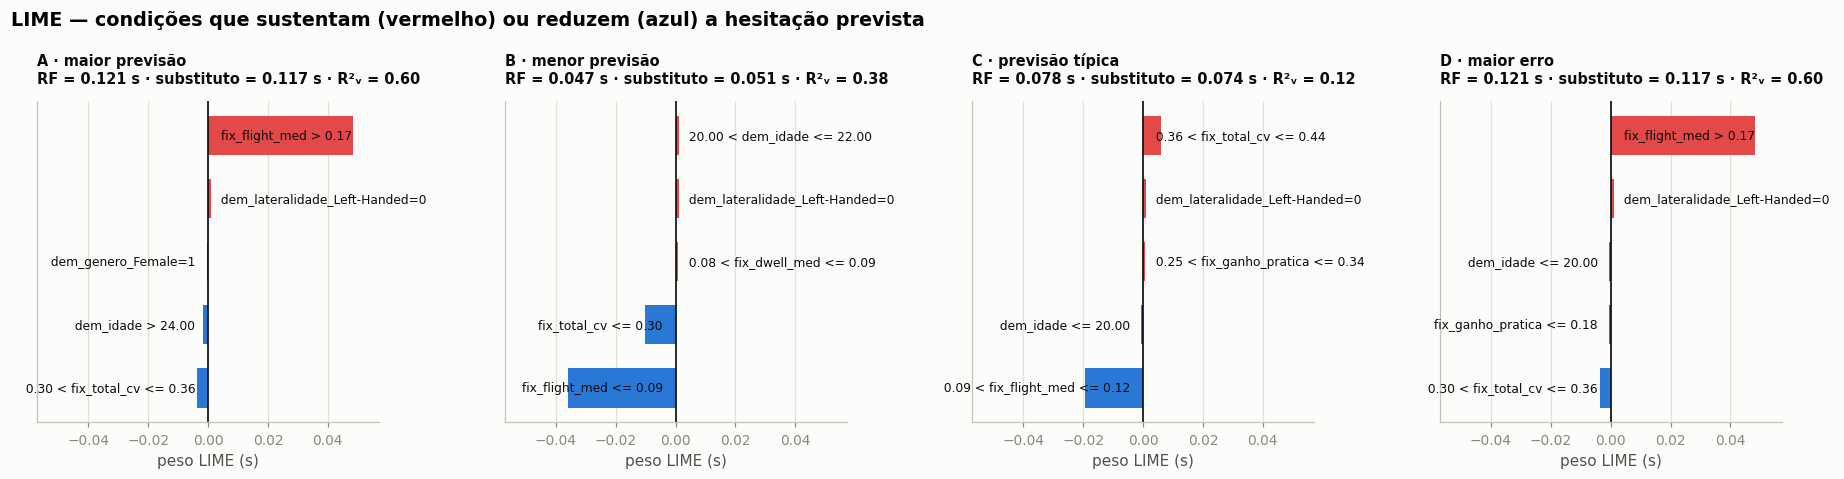

In [21]:
# ══ C21 · LIME — explicação de referência ════════════════════════════════
from lime.lime_tabular import LimeTabularExplainer

IDX_DUM = [COLS.index(c) for c in COLS_DUM]
K_LIME, M_LIME = 5, 5000
SIGMA_PADRAO = 0.75 * np.sqrt(len(COLS))          # kernel_width padrão do pacote lime


def novo_explicador(semente, discretizar=True, largura=None):
    # O explicador guarda a distribuição do TREINO (de onde saem as perturbações) e a semente.
    return LimeTabularExplainer(D_tr.to_numpy(float), feature_names=COLS, categorical_features=IDX_DUM,
                                categorical_names={i: ["0", "1"] for i in IDX_DUM}, mode="regression",
                                discretize_continuous=discretizar, kernel_width=largura, random_state=semente)


def explicar_lime(x, semente=SEMENTE, K=K_LIME, m=M_LIME, discretizar=True, largura=None):
    ex = novo_explicador(semente, discretizar, largura)
    t0 = time.time()
    e = ex.explain_instance(x.to_numpy(float), f_rf, num_features=K, num_samples=m)
    descricoes = [d for d, _ in e.as_list()]                      # mesma ordem de local_exp[1]
    ordem = [int(i) for i, _ in e.local_exp[1]]
    return {"pesos": {int(i): float(w) for i, w in e.local_exp[1]},
            "cond": dict(zip(ordem, descricoes)),
            "r2": float(e.score), "local_pred": float(e.local_pred[0]), "tempo": time.time() - t0}


REF_LIME = {k: explicar_lime(x) for k, x in X_OBS.items()}

linhas = []
for k, r in REF_LIME.items():
    fx = float(f_rf(X_OBS[k].to_frame().T)[0])
    for i, w in sorted(r["pesos"].items(), key=lambda t: -abs(t[1])):
        linhas.append({"obs": k, "condição (bin do indivíduo)": r["cond"][i], "peso (s)": w,
                       "R² local": r["r2"], "pred. substituto (s)": r["local_pred"], "pred. RF (s)": fx})
tab_lime = pd.DataFrame(linhas)
display(tab_lime.round(4))
tab_lime.to_csv(DIR_SAIDA / "tabela_lime_referencia.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(17, 4.4), sharex=True)
lim_x = max(abs(w) for r in REF_LIME.values() for w in r["pesos"].values()) * 1.18
for ax, (k, r) in zip(axes, REF_LIME.items()):
    itens = sorted(r["pesos"].items(), key=lambda t: t[1])
    cores = [COR["pos"] if w > 0 else COR["neg"] for _, w in itens]
    ax.barh(range(len(itens)), [w for _, w in itens], color=cores, height=0.62)
    ax.axvline(0, color=COR["tinta"], linewidth=1.1)
    for j, (i, w) in enumerate(itens):
        ax.text(0.003 * np.sign(w) if w else 0, j, " " + r["cond"][i] + " ", va="center",
                ha="left" if w > 0 else "right", fontsize=8, color=COR["tinta"])
    ax.set_yticks([]); ax.set_xlim(-lim_x, lim_x)
    fx = float(f_rf(X_OBS[k].to_frame().T)[0])
    ax.set_title(f"{ROTULO[k]}\nRF = {fx:.3f} s · substituto = {r['local_pred']:.3f} s · R²ᵥ = {r['r2']:.2f}", fontsize=9.5)
    ax.set_xlabel("peso LIME (s)")
    limpar_eixos(ax)
fig.suptitle("LIME — condições que sustentam (vermelho) ou reduzem (azul) a hesitação prevista", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig11_lime_referencia.png")
plt.show()

### C22 · **Estabilidade**: 30 execuções com sementes diferentes

**Objetivo:** o LIME usa **perturbações aleatórias** — *"duas execuções para o mesmo indivíduo podem gerar
explicações diferentes"* (SLIDE 06, p. 25). Repetimos a explicação 30 vezes variando **somente a semente** e medimos:

- **concordância dos atributos**: índice de Jaccard $J(S_a,S_b)=|S_a\cap S_b|/|S_a\cup S_b|$ entre os conjuntos selecionados;
- **concordância dos pesos**: fração de **sinais** concordantes e **intervalo empírico** dos pesos;
- **ordenação**: o atributo de maior $|w|$ é sempre o mesmo?
- **fidelidade** $R^2_w$ em cada execução.

> **"Alta fidelidade em uma execução não garante que a explicação seja estável."** (SLIDE 06, p. 25)

,Jaccard médio,Jaccard mínimo,conjuntos distintos,atributo top-1 mais frequente,% execuções com esse top-1,% sinais concordantes,R² médio,R² dp
obs,,,,,,,,
A,0.6320,0.4290,9,fix_flight_med,100.0000,77.6970,0.6210,0.0090
B,0.6410,0.4290,10,fix_flight_med,100.0000,77.9100,0.3890,0.0090
C,0.6320,0.4290,10,fix_flight_med,100.0000,77.3360,0.1180,0.0060
D,0.6340,0.4290,10,fix_flight_med,100.0000,77.4500,0.6210,0.0090


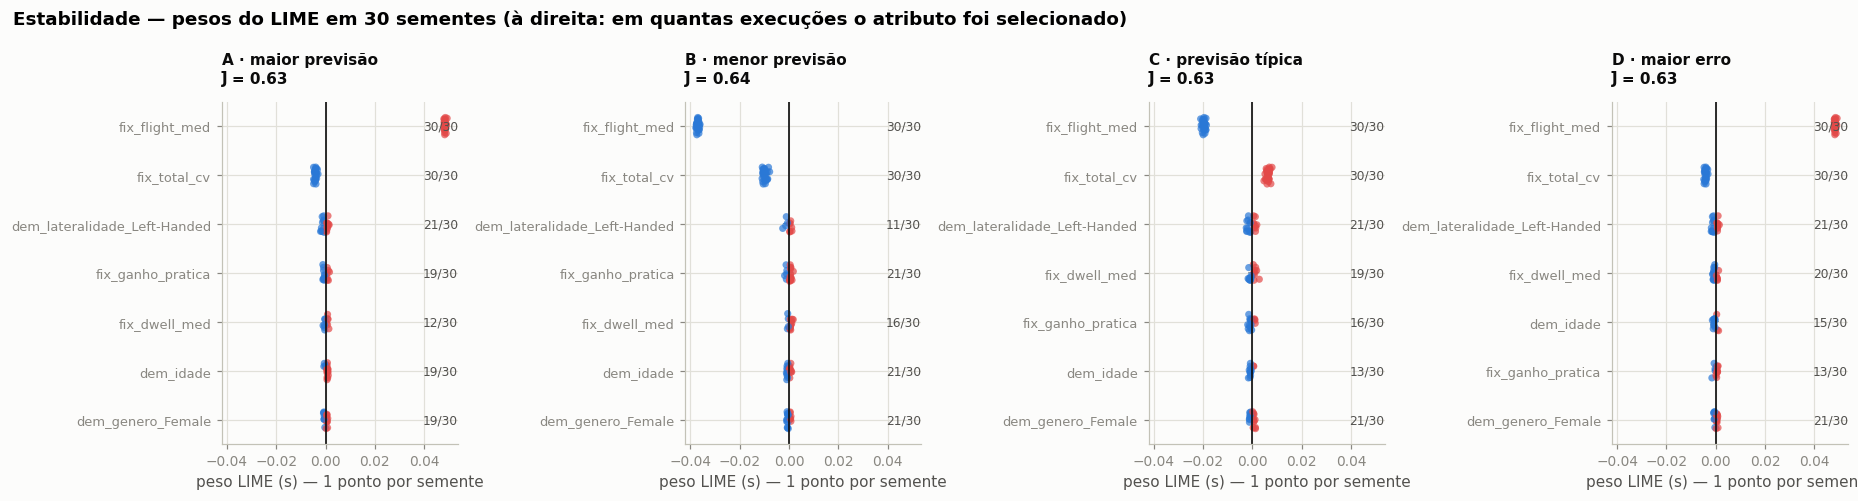

In [22]:
# ══ C22 · Estabilidade do LIME (30 sementes) ═════════════════════════════
SEMENTES = list(range(1, 31))
EST = {k: [explicar_lime(x, s) for s in SEMENTES] for k, x in X_OBS.items()}


def jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 1.0


linhas = []
for k, runs in EST.items():
    conjuntos = [frozenset(r["pesos"]) for r in runs]
    jac = [jaccard(a, b) for a, b in combinations(conjuntos, 2)]
    top1 = [max(r["pesos"], key=lambda i: abs(r["pesos"][i])) for r in runs]
    top1_modal = max(set(top1), key=top1.count)
    conc = []
    for a, b in combinations(runs, 2):
        for i in set(a["pesos"]) & set(b["pesos"]):
            conc.append(np.sign(a["pesos"][i]) == np.sign(b["pesos"][i]))
    linhas.append({"obs": k, "Jaccard médio": np.mean(jac), "Jaccard mínimo": np.min(jac),
                   "conjuntos distintos": len(set(conjuntos)),
                   "atributo top-1 mais frequente": COLS[top1_modal], "% execuções com esse top-1": 100 * top1.count(top1_modal) / len(top1),
                   "% sinais concordantes": 100 * np.mean(conc),
                   "R² médio": np.mean([r["r2"] for r in runs]), "R² dp": np.std([r["r2"] for r in runs])})
resumo_est = pd.DataFrame(linhas).set_index("obs")
display(resumo_est.round(3))
resumo_est.to_csv(DIR_SAIDA / "tabela_lime_estabilidade.csv")

# ── Distribuição dos pesos por atributo ──────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), sharex=True)
for ax, (k, runs) in zip(axes, EST.items()):
    freq = pd.Series([i for r in runs for i in r["pesos"]]).value_counts()
    media_abs = {i: np.mean([abs(r["pesos"][i]) for r in runs if i in r["pesos"]]) for i in freq.index}
    ordem = sorted(freq.index, key=lambda i: media_abs[i])
    rng = np.random.RandomState(0)
    for pos, i in enumerate(ordem):
        w = np.array([r["pesos"][i] for r in runs if i in r["pesos"]])
        ax.scatter(w, pos + rng.uniform(-0.18, 0.18, len(w)), s=22, alpha=0.7,
                   color=[COR["pos"] if v > 0 else COR["neg"] for v in w], edgecolor="none")
        ax.hlines(pos, w.min(), w.max(), color=COR["suave"], linewidth=1, zorder=0)
        ax.text(1.0, pos, f"{len(w)}/30", transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=8, color=COR["tinta2"])
    ax.axvline(0, color=COR["tinta"], linewidth=1.1)
    ax.set_yticks(range(len(ordem))); ax.set_yticklabels([COLS[i] for i in ordem], fontsize=8.5)
    ax.set_title(f"{ROTULO[k]}\nJ̄ = {resumo_est.loc[k, 'Jaccard médio']:.2f}", fontsize=10)
    ax.set_xlabel("peso LIME (s) — 1 ponto por semente")
    limpar_eixos(ax)
fig.suptitle("Estabilidade — pesos do LIME em 30 sementes (à direita: em quantas execuções o atributo foi selecionado)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig12_lime_estabilidade.png")
plt.show()

### C23 · Quantas perturbações bastam? (SLIDE 06, p. 27)

**Objetivo:** *"mais perturbações podem estabilizar o ajuste, mas aumentam o custo; o objetivo não é escolher o maior
$m$, mas obter uma explicação suficientemente estável."* Avaliamos $m\in\{500,1000,2500,5000,10000\}$ com
**10 sementes** cada, examinando: tempo, fidelidade, concordância dos atributos selecionados (Jaccard médio entre
execuções) e variabilidade do peso do atributo principal.

obs,A,B,C,D
m,,,,
500,0.592000,0.661000,0.612000,0.667000
1000,0.610000,0.631000,0.644000,0.642000
2500,0.595000,0.595000,0.622000,0.635000
5000,0.638000,0.638000,0.694000,0.646000
10000,0.668000,0.635000,0.660000,0.610000


obs,A,B,C,D
m,,,,
500,0.020000,0.032000,0.071000,0.022000
1000,0.017000,0.020000,0.043000,0.018000
2500,0.007000,0.011000,0.027000,0.008000
5000,0.006000,0.009000,0.018000,0.006000
10000,0.005000,0.008000,0.015000,0.005000


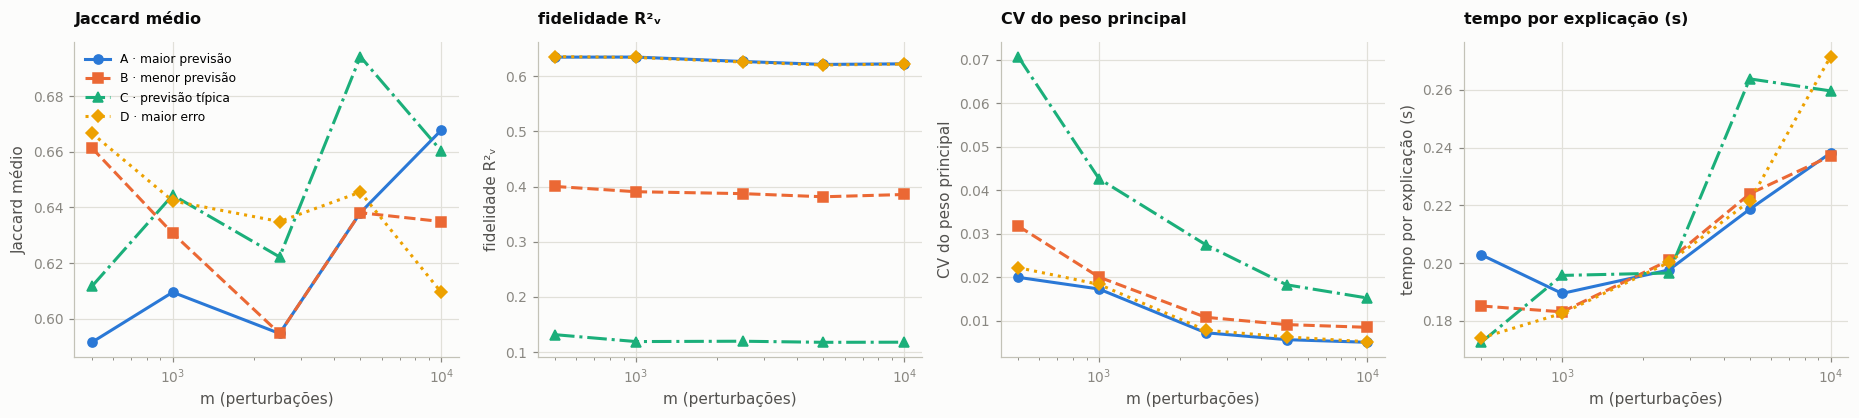

In [23]:
# ══ C23 · Número de perturbações ═════════════════════════════════════════
MS = [500, 1000, 2500, 5000, 10000]
linhas = []
for k, x in X_OBS.items():
    for m in MS:
        runs = [explicar_lime(x, s, m=m) for s in range(101, 111)]
        conj = [frozenset(r["pesos"]) for r in runs]
        top1 = [max(r["pesos"], key=lambda i: abs(r["pesos"][i])) for r in runs]
        topo = max(set(top1), key=top1.count)
        w_topo = np.array([r["pesos"].get(topo, 0.0) for r in runs])
        linhas.append({"obs": k, "m": m, "tempo (s)": np.mean([r["tempo"] for r in runs]),
                       "R² médio": np.mean([r["r2"] for r in runs]),
                       "Jaccard médio": np.mean([jaccard(a, b) for a, b in combinations(conj, 2)]),
                       "% top-1 modal": 100 * top1.count(topo) / len(top1),
                       "CV do peso top-1": w_topo.std() / abs(w_topo.mean()) if w_topo.mean() else np.nan})
tab_m = pd.DataFrame(linhas)
display(tab_m.pivot(index="m", columns="obs", values="Jaccard médio").round(3).style.set_caption("Jaccard médio entre execuções, por m"))
display(tab_m.pivot(index="m", columns="obs", values="CV do peso top-1").round(3).style.set_caption("Coeficiente de variação do peso do atributo principal, por m"))
tab_m.to_csv(DIR_SAIDA / "tabela_lime_numero_perturbacoes.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.9))
for ax, (col, rot) in zip(axes, [("Jaccard médio", "Jaccard médio"), ("R² médio", "fidelidade R²ᵥ"),
                                  ("CV do peso top-1", "CV do peso principal"), ("tempo (s)", "tempo por explicação (s)")]):
    for k in OBS:
        d = tab_m[tab_m["obs"] == k]
        ax.plot(d["m"], d[col], color=ESTILO[k]["color"], linestyle=ESTILO[k]["ls"], marker=ESTILO[k]["marker"],
                linewidth=2, markersize=6, label=ROTULO[k])
    ax.set_xscale("log"); ax.set_xlabel("m (perturbações)"); ax.set_ylabel(rot); ax.set_title(rot, fontsize=10.5)
    limpar_eixos(ax)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig13_lime_perturbacoes.png")
plt.show()

### C24 · Largura do kernel e discretização (SLIDE 06, pp. 14–15; p. 37)

**Objetivo:** *"a largura do kernel muda a explicação; não existe uma largura universalmente correta — analise a
sensibilidade"*. Variamos $\sigma$ em $\{0{,}25;\,0{,}5;\,1;\,2;\,4\}\times\sigma_\text{padrão}$ e medimos:

- **tamanho efetivo da amostra** $\mathrm{ESS}=(\sum\pi_i)^2/\sum\pi_i^2$ — *quantas perturbações realmente pesam*
  (kernel estreito ⇒ poucos pontos ⇒ variância alta; kernel largo ⇒ explicação **regional**, não local);
- **fidelidade** $R^2_w$ e **estabilidade** (Jaccard e variação do peso principal em 10 sementes);
- a **discretização** (*"a discretização altera as condições exibidas"*): com `discretize_continuous=False`, os
  pesos viram **inclinações locais por 1 DP** — diretamente comparáveis ao *efeito local por 1 DP* do CP (C13).

In [24]:
# ══ C24 · Sensibilidade ao kernel e à discretização ═════════════════════
def ess_kernel(x, semente, largura, m=3000):
    # Tamanho efetivo da amostra do kernel exponencial do LIME (replica o cálculo interno do pacote).
    ex = novo_explicador(semente, True, largura)
    Z, _ = ex._LimeTabularExplainer__data_inverse(x.to_numpy(float), m)
    esc = (Z - ex.scaler.mean_) / ex.scaler.scale_
    d = np.sqrt(((esc - esc[0]) ** 2).sum(axis=1))
    w = np.sqrt(np.exp(-(d ** 2) / largura ** 2))
    return float(w.sum() ** 2 / (w ** 2).sum() / m)


linhas = []
for k, x in X_OBS.items():
    for mult in [0.25, 0.5, 1, 2, 4]:
        sig = SIGMA_PADRAO * mult
        runs = [explicar_lime(x, s, largura=sig) for s in range(201, 211)]
        conj = [frozenset(r["pesos"]) for r in runs]
        top1 = [max(r["pesos"], key=lambda i: abs(r["pesos"][i])) for r in runs]
        topo = max(set(top1), key=top1.count)
        w_topo = np.array([r["pesos"].get(topo, 0.0) for r in runs])
        linhas.append({"obs": k, "σ / σ_padrão": mult, "σ": sig, "ESS / m": ess_kernel(x, 7, sig),
                       "R² médio": np.mean([r["r2"] for r in runs]),
                       "Jaccard médio": np.mean([jaccard(a, b) for a, b in combinations(conj, 2)]),
                       "atributo top-1": COLS[topo], "peso top-1 (s)": w_topo.mean(), "dp do peso top-1": w_topo.std()})
tab_k = pd.DataFrame(linhas)
display(tab_k.round(3))
tab_k.to_csv(DIR_SAIDA / "tabela_lime_kernel.csv", index=False)

# ── Discretização ligada × desligada ─────────────────────────────────────
print("\nDISCRETIZAÇÃO — pesos com discretize_continuous=False (inclinação local por 1 DP) vs. efeito local do CP:")
linhas = []
for k, x in X_OBS.items():
    r = explicar_lime(x, SEMENTE, K=len(COLS), discretizar=False)
    cp = tab_cp[tab_cp["obs"] == k].set_index("variável")["efeito local por 1 DP (s)"]
    for v in COLS_CONT:
        linhas.append({"obs": k, "variável": v, "LIME contínuo (s por 1 DP)": r["pesos"].get(COLS.index(v), np.nan),
                       "CP: efeito local por 1 DP (s)": cp[v], "R² local": r["r2"]})
tab_disc = pd.DataFrame(linhas)
display(tab_disc.round(4))
print(f"Correlação (Pearson) LIME-contínuo × CP-local sobre os {len(tab_disc)} pares obs×variável: "
      f"{tab_disc['LIME contínuo (s por 1 DP)'].corr(tab_disc['CP: efeito local por 1 DP (s)']):+.3f}")

,obs,σ / σ_padrão,σ,ESS / m,R² médio,Jaccard médio,atributo top-1,peso top-1 (s),dp do peso top-1
0,A,0.2500,0.4960,0.0130,0.7750,0.6930,fix_flight_med,0.0370,0.0010
1,A,0.5000,0.9920,0.6860,0.6870,0.6200,fix_flight_med,0.0490,0.0000
2,A,1.0000,1.9840,0.9790,0.6260,0.6000,fix_flight_med,0.0490,0.0000
3,A,2.0000,3.9690,0.9990,0.6090,0.6060,fix_flight_med,0.0480,0.0000
4,A,4.0000,7.9370,1.0000,0.6050,0.6190,fix_flight_med,0.0480,0.0000
5,B,0.2500,0.4960,0.0180,0.5840,0.6900,fix_flight_med,-0.0300,0.0030
6,B,0.5000,0.9920,0.6990,0.4460,0.6100,fix_flight_med,-0.0370,0.0010
7,B,1.0000,1.9840,0.9790,0.3850,0.6330,fix_flight_med,-0.0370,0.0000
8,B,2.0000,3.9690,0.9990,0.3690,0.6400,fix_flight_med,-0.0370,0.0000
9,B,4.0000,7.9370,1.0000,0.3660,0.6460,fix_flight_med,-0.0370,0.0000



DISCRETIZAÇÃO — pesos com discretize_continuous=False (inclinação local por 1 DP) vs. efeito local do CP:


,obs,variável,LIME contínuo (s por 1 DP),CP: efeito local por 1 DP (s),R² local
0,A,fix_dwell_med,-0.0000,-0.0001,0.7431
1,A,fix_flight_med,0.0249,0.0017,0.7431
2,A,fix_total_cv,0.0045,0.0006,0.7431
3,A,fix_ganho_pratica,-0.0001,0.0000,0.7431
4,A,dem_idade,-0.0001,0.0000,0.7431
5,B,fix_dwell_med,-0.0001,-0.0001,0.7324
6,B,fix_flight_med,0.0240,0.0129,0.7324
7,B,fix_total_cv,0.0065,0.0000,0.7324
8,B,fix_ganho_pratica,0.0000,0.0000,0.7324
9,B,dem_idade,0.0002,0.0004,0.7324


Correlação (Pearson) LIME-contínuo × CP-local sobre os 20 pares obs×variável: +0.663


### C25 · **Plausibilidade** das perturbações

**Objetivo:** o LIME *"cria observações artificiais para investigar o comportamento da caixa-preta"*. Se os
atributos são perturbados **independentemente**, surgem combinações que **não existem** nos dados, e nessas regiões
$\hat f$ pode estar **extrapolando** — *"fidelidade ao modelo não implica plausibilidade nos dados"* (SLIDE 06, p. 28).

Usamos o **mesmo teste de suporte do CP** (C11): distância de cada perturbação ao dado de treino mais próximo,
comparada ao percentil 95 das distâncias *leave-one-out* entre dados reais. Também medimos o **peso efetivo** das
perturbações plausíveis — o que importa é quanto da explicação vem de regiões com suporte.

,% perturbações sem suporte,% do PESO do kernel em perturbações sem suporte,dist. mediana (perturbações),"dist. mediana (dados reais, LOO)"
obs,,,,
A,10.6400,11.1300,1.2100,1.0800
B,10.6400,10.2400,1.2100,1.0800
C,10.6400,10.2600,1.2100,1.0800
D,10.6600,10.2900,1.2100,1.0800


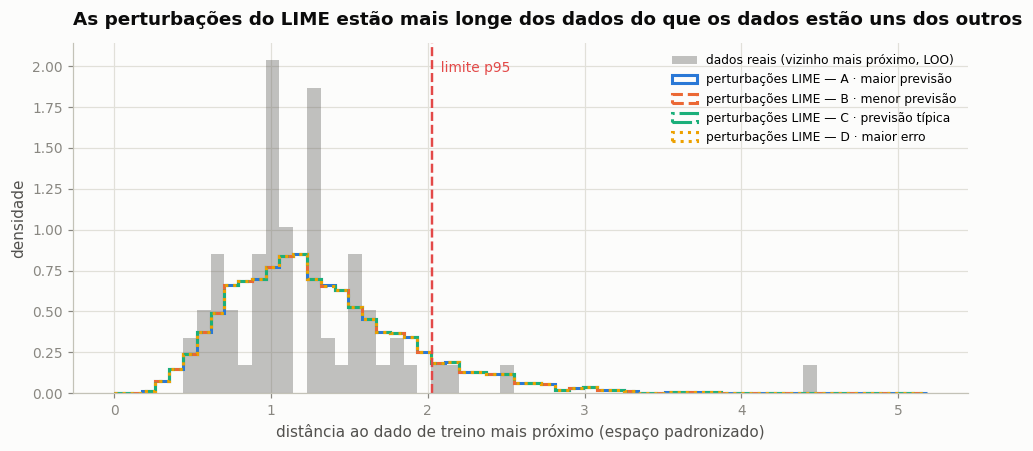

In [25]:
# ══ C25 · Plausibilidade das perturbações do LIME ════════════════════════
linhas, DIST_PERT = [], {}
for k, x in X_OBS.items():
    ex = novo_explicador(SEMENTE)
    Z, inv = ex._LimeTabularExplainer__data_inverse(x.to_numpy(float), M_LIME)
    Xp = pd.DataFrame(inv, columns=COLS)
    d = dist_ao_treino(Xp)
    esc = (Z - ex.scaler.mean_) / ex.scaler.scale_
    w = np.sqrt(np.exp(-(np.sqrt(((esc - esc[0]) ** 2).sum(axis=1)) ** 2) / SIGMA_PADRAO ** 2))
    DIST_PERT[k] = d
    linhas.append({"obs": k, "% perturbações sem suporte": 100 * np.mean(d > LIM_SUPORTE),
                   "% do PESO do kernel em perturbações sem suporte": 100 * w[d > LIM_SUPORTE].sum() / w.sum(),
                   "dist. mediana (perturbações)": np.median(d), "dist. mediana (dados reais, LOO)": np.median(d_loo)})
tab_pl = pd.DataFrame(linhas).set_index("obs")
display(tab_pl.round(2))

fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.linspace(0, max(np.max(v) for v in DIST_PERT.values()), 60)
ax.hist(d_loo, bins=bins, density=True, color=COR["tinta2"], alpha=0.35, label="dados reais (vizinho mais próximo, LOO)")
for k, d in DIST_PERT.items():
    ax.hist(d, bins=bins, density=True, histtype="step", linewidth=2, color=ESTILO[k]["color"], linestyle=ESTILO[k]["ls"],
            label=f"perturbações LIME — {ROTULO[k]}")
ax.axvline(LIM_SUPORTE, color=COR["pos"], linewidth=1.6, linestyle="--")
ax.text(LIM_SUPORTE, ax.get_ylim()[1] * 0.95, "  limite p95", color=COR["pos"], fontsize=9, va="top")
ax.set_xlabel("distância ao dado de treino mais próximo (espaço padronizado)"); ax.set_ylabel("densidade")
ax.set_title("As perturbações do LIME estão mais longe dos dados do que os dados estão uns dos outros")
ax.legend(fontsize=8)
limpar_eixos(ax)
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig14_lime_plausibilidade.png")
plt.show()

### C26 · **Teste de sanidade**: o LIME recupera uma explicação **conhecida**?

**Objetivo:** como o modelo linear da ATV2 tem explicação exata ($\beta_j$ por desvio-padrão), podemos
**calibrar** o LIME: aplicado ao modelo linear, com discretização desligada, os pesos têm de coincidir com os
$\beta_j$ (nas dummies, com o sinal da categoria do indivíduo). Se o LIME falhasse aqui, não haveria motivo para
confiar nele na floresta.

In [26]:
# ══ C26 · LIME aplicado ao modelo linear (explicação exata conhecida) ════
beta_z = pd.Series(lin[-1].coef_, index=COLS_CONT + COLS_DUM)       # ordem do ColumnTransformer: contínuas, depois dummies
erros = []
for k, x in X_OBS.items():
    ex = novo_explicador(SEMENTE, discretizar=False)
    e = ex.explain_instance(x.to_numpy(float), f_lin, num_features=len(COLS), num_samples=M_LIME)
    w = {int(i): float(v) for i, v in e.local_exp[1]}
    for j, c in enumerate(COLS):
        esperado = beta_z[c] * (1 if (c in COLS_CONT or x[c] == 1) else -1)
        erros.append({"obs": k, "variável": c, "β exato (ATV2)": esperado, "peso LIME": w[j], "erro": w[j] - esperado})
tab_san = pd.DataFrame(erros)
print("Erro máximo |LIME − β exato| por observação (s):")
print(tab_san.assign(abs_erro=tab_san["erro"].abs()).groupby("obs")["abs_erro"].max().round(5).to_string())
print(f"\nMaior |β| do modelo linear: {beta_z.abs().max():.4f} s   → erro máximo relativo: "
      f"{tab_san['erro'].abs().max() / beta_z.abs().max():.1%}")
display(tab_san[tab_san["obs"] == "A"].round(5))

Erro máximo |LIME − β exato| por observação (s):
obs
A   0.0000
B   0.0000
C   0.0000
D   0.0036

Maior |β| do modelo linear: 0.0300 s   → erro máximo relativo: 11.9%


,obs,variável,β exato (ATV2),peso LIME,erro
0,A,fix_dwell_med,-0.0016,-0.0016,0.0000
1,A,fix_flight_med,0.0300,0.0300,-0.0000
2,A,fix_total_cv,0.0059,0.0059,-0.0000
3,A,fix_ganho_pratica,-0.0048,-0.0048,0.0000
4,A,dem_idade,0.0029,0.0029,-0.0000
5,A,dem_genero_Female,-0.0134,-0.0134,0.0000
6,A,dem_lateralidade_Left-Handed,0.0017,0.0017,-0.0000


### Interpretação — LIME

**1. O que o LIME diz (C21).** Nas quatro observações a **condição de maior peso é sobre `fix_flight_med`**:

| Obs. | Condição principal (peso, s) | Segunda condição | $R^2_w$ |
|---|---|---|---|
| **A** (prev. 0,121 s) | `fix_flight_med > 0,17` **(+0,048)** | `0,30 < fix_total_cv ≤ 0,36` (−0,004) | **0,60** |
| **B** (prev. 0,047 s) | `fix_flight_med ≤ 0,09` **(−0,036)** | `fix_total_cv ≤ 0,30` (−0,010) | **0,38** |
| **C** (prev. 0,078 s) | `0,09 < fix_flight_med ≤ 0,12` **(−0,019)** | `0,36 < fix_total_cv ≤ 0,44` (+0,006) | **0,12** |
| **D** (prev. 0,121 s) | `fix_flight_med > 0,17` **(+0,048)** | `0,30 < fix_total_cv ≤ 0,36` (−0,004) | **0,60** |

Leitura: *"ser da faixa `flight > 0,17` **eleva** em ≈ 0,048 s a hesitação prevista em relação à média da vizinhança"*.
A e D recebem **explicações idênticas** porque a floresta prevê o mesmo valor (0,121 s) para ambas — D, apesar de ter
`flight = 0,478 s`, está no mesmo bin e no mesmo patamar.

**2. A fidelidade separa as explicações confiáveis das enganosas.** O substituto reproduz a floresta com $R^2_w=0{,}60$ em
A e D (patamar alto), **0,38** em B e **apenas 0,12 em C**. A observação **típica** é a **pior explicada**: ela está
**no meio da escada** da curva CP (C14), onde uma reta não representa degraus. A explicação de C *parece* plausível
("`flight` na faixa média reduz 0,019 s") mas **o substituto quase não imita a floresta** ali — o SLIDE 06 (p. 24) alerta que
a fidelidade é o que impede de aceitar uma explicação só por parecer convincente.

**3. Estabilidade: o essencial é estável, a cauda não (C22).** Em 30 sementes: `fix_flight_med` é o atributo de **maior
|peso| em 30/30 execuções** e `fix_total_cv` é selecionado em **30/30**, com sinais e magnitudes estáveis (dp do peso ≈ 0,0005 s).
Mas os **três atributos restantes** são sorteados entre variáveis de efeito ≈ 0 (selecionadas em 11–21 das 30 execuções),
o que produz **9–10 conjuntos diferentes**, **Jaccard médio = 0,63** (< 0,70) e **77% de sinais concordantes** (os sinais das
variáveis irrelevantes oscilam). Diagnóstico: o instável é a **escolha de $K=5$** num problema em que só **2** variáveis
importam — não o método. Com $K=2$ a seleção seria estável.

**4. Mais perturbações estabilizam os pesos, não a seleção (C23).** De $m=500$ para $10\,000$, o coeficiente de variação
do peso principal cai de 0,02–0,07 para 0,005–0,015 e o tempo cresce, mas o **Jaccard não melhora** (0,59–0,69) nem o $R^2_w$.
Já com $m=2500$–$5000$ o CV é < 3%: **$m=5000$ é suficiente**; aumentar $m$ não cura a cauda de seleção.

**5. O kernel padrão não é local (C24).** Com 7 variáveis, $\sigma=0{,}75\sqrt7\approx1{,}98$ dá **ESS/m = 0,98**: quase **todas**
as perturbações pesam igual — o LIME opera como uma regressão **regional**, não como uma aproximação na vizinhança (SLIDE 06,
p. 16: *"kernel largo… aproxima uma explicação regional"*). Estreitar o kernel ($0{,}25\sigma$) melhora a fidelidade
(A: 0,78; B: 0,58; C: 0,26 — contra 0,63; 0,39; 0,12) **mas** reduz o ESS a **≈ 1–2%** (da ordem de 30–55 pontos efetivos em 3000) e aumenta a variância
dos pesos. O atributo principal **não muda** com $\sigma$ (sempre `fix_flight_med`). Sem discretização, o peso de `flight` em A
é **0,025 s por DP**, enquanto o efeito **local** do CP é 0,002 s — o LIME enxerga o **degrau próximo**; o CP, o **platô onde A está**.
Entre os 20 pares observação × variável, a correlação LIME-contínuo × CP-local é **+0,66**.

**6. Plausibilidade (C25).** ≈ **10,6%** das perturbações ficam além do p95 das distâncias entre dados reais (o esperado para dados
reais é 5%) e carregam **≈ 10–11% do peso** do kernel; a distância mediana é 1,21 contra 1,08. Há perturbações fora do suporte, mas
**poucas** — as variáveis são fracamente dependentes (único par acima do limiar: `fix_total_cv` × `fix_ganho_pratica`, r = 0,56).

**7. Sanidade (C26).** Aplicado ao **modelo linear**, o LIME recupera os $\beta_j$ da ATV2 com erro < 5×10⁻⁵ s em A, B e C.
**Em D o erro sobe a 0,0036 s (11,9% do maior β)**: D é *outlier* (padrão de baixa fidelidade, $R^2_w=0{,}21$ em modo contínuo) e o
LIME (sem discretização) **amostra em torno da média do treino**, de modo que um indivíduo distante provavelmente recebe poucas
amostras com peso relevante no kernel. É um indício de que **a confiabilidade do LIME cai onde há poucos dados** — hipótese
coerente com o $R^2_w$ baixo, mas que este notebook não isola.

> **Conclusão sobre o LIME:** nas quatro observações ele aponta o mesmo fator principal que os demais métodos, mas a explicação
> **deve vir acompanhada de $R^2_w$** (C é frágil), de **K pequeno** e de uma nota sobre o **kernel** (efetivamente global).

---
# §5 · Etapa 5 — SHAP (*SHapley Additive exPlanations*)

**Objetivo da seção:** decompor cada predição em **contribuições aditivas das variáveis** em relação a um
*baseline* — seguindo o roteiro do **SLIDE 07** (*Valores de Shapley*): da teoria dos jogos ao SHAP, as propriedades,
a definição de $v(S)$, o baseline, os gráficos (barra local, cascata, força), o custo computacional, os algoritmos
(KernelSHAP, TreeSHAP) e a dependência entre variáveis. Cada ideia do slide é **testada numericamente** em vez de aceita.

### 1. Da teoria dos jogos ao SHAP (SLIDE 07, pp. 3–10)

Em um **jogo cooperativo**, jogadores formam coalizões, cada coalizão produz um ganho e queremos **distribuir o ganho
total** entre eles. A pergunta de Lloyd Shapley (1953): *quanto cada jogador deve receber pela sua contribuição?*

| Teoria dos jogos | Aprendizado de máquina |
|---|---|
| Jogador | **Variável** (*feature*) |
| Coalizão | **Subconjunto** de variáveis |
| Ganho da coalizão | **Predição** considerando a coalizão |
| Contribuição marginal | **Mudança na predição** ao incluir a variável |
| Valor de Shapley | **Contribuição atribuída** à variável |

A **contribuição marginal** de $j$ para uma coalizão $S$ que ainda não o contém é $v(S\cup\{j\})-v(S)$ — mas ela
**depende de quem já está na coalizão** (por exemplo, $v(\{1,j\})-v(\{1\})\ne v(\{1,2,j\})-v(\{1,2\})$). O **valor de
Shapley** resolve isso tomando a contribuição marginal de $j$ em **todas as coalizões** e fazendo uma **média
ponderada** — equivalentemente, a média sobre **todas as ordens** em que as variáveis poderiam entrar.

O SHAP foi proposto por **Lundberg & Lee (2017)**, sobre a ideia de usar valores de Shapley para explicar modelos
(**Štrumbelj & Kononenko, 2011, 2014**), numa estrutura **unificada** de métodos de atribuição *post-hoc* que inclui
conexões com o LIME. Ele responde: **por que o modelo produziu esta predição específica?**

### 2. A definição (SLIDE 07, pp. 12–14)

$$\phi_j=\sum_{S\subseteq F\setminus\{j\}}\frac{|S|!\,(|F|-|S|-1)!}{|F|!}\,\Big[f(S\cup\{j\})-f(S)\Big]$$

$F$: todas as variáveis; $S$: subconjunto **sem** $j$; $f(S)$: valor da coalizão; o **peso** conta as posições em que
$j$ pode entrar nas ordenações. Para uma observação $x$, a **explicação aditiva** é

$$f(x)=\phi_0+\sum_{j=1}^{p}\phi_j,\qquad \phi_0=\text{baseline}.$$

### 3. Propriedades do valor de Shapley (SLIDE 07, p. 20) — e onde as testamos

| Propriedade | Significado | Teste neste notebook |
|---|---|---|
| **Eficiência** | as contribuições somam a diferença entre a predição e o baseline | C26b (exemplo do slide), C27 e C28 (96 participantes) |
| **Simetria** | variáveis com a mesma contribuição recebem o mesmo valor | C31b (jogo-brinquedo) |
| **Jogador nulo** | variável que nunca altera o resultado recebe **zero** | C28 (dummies que a floresta ignora) e C31b |
| **Aditividade** | para a soma de dois jogos, os valores também se somam | C31b (média de dois modelos) |

### 4. Como avaliar o modelo com variáveis "ausentes" (SLIDE 07, pp. 21–24)

O modelo foi ajustado com **todas** as variáveis; precisamos definir $f(S)$ quando só as de $S$ estão presentes.
Uma "ausente" **não** é "igual a zero": o valor da coalizão é a **predição média** sobre os valores possíveis das ausentes,

$$v(S)=\mathbb E\big[f(x_S,X_{\bar S})\big],\qquad \phi_0=v(\varnothing)=\mathbb E[f(X)],\qquad f(x)-\phi_0=\sum_{j=1}^{p}\phi_j .$$

Aqui $\mathbb E[\cdot]$ é uma **média sobre o *background*** (o conjunto de treino, 67 participantes) — e é essa escolha que
define a explicação (ver C32).

### 5. Como interpretar (SLIDE 07, pp. 25–26)

$\phi_j>0$: a variável **aumenta** a predição em relação ao baseline; $\phi_j<0$: **reduz**; $\phi_j\approx0$: contribuição
pequena **para esta observação**. Duas observações podem ter $\phi_j$ muito diferentes para a mesma variável.
> **O valor SHAP é uma contribuição para a predição do modelo — não um efeito causal da variável sobre a resposta.**

### 6. Custo e algoritmos (SLIDE 07, pp. 33–34)

O cálculo exato exige **$2^P$ coalizões** — inviável quando $P$ cresce. Por isso existem estratégias diferentes para a
mesma ideia: **KernelSHAP** (agnóstico ao modelo, **aproxima** os valores) e **TreeSHAP** (explora a estrutura das árvores;
muito mais eficiente). Como aqui $P=7$ ($2^7=128$ coalizões), podemos calcular o valor **exato por enumeração** e usá-lo para
**auditar** os dois algoritmos — as **três vias** (enumeração, `TreeExplainer`, `KernelExplainer`) **têm de coincidir**.

### 7. Dependência entre variáveis (SLIDE 07, p. 35)

A definição de $v(S)$ depende de como tratamos as ausentes: com a distribuição **marginal** (que **não** condiciona as demais
aos valores de $S$) ou com a **condicional** $\mathbb E[f(X)\mid X_S=x_S]$. Com variáveis dependentes, as duas dão explicações
diferentes — *os valores SHAP não dependem só do modelo e da observação*. Aqui o `TreeExplainer` *interventional* usa a
marginal (o *background*); a variante *path-dependent* aproxima a condicional pela cobertura das folhas (C32).

### 8. Conexão com o restante da disciplina

- **SLIDE 03:** no modelo linear com variáveis independentes, $\phi_j(x)=\beta_j\,(x_j-\mathbb E[x_j])$ — a decomposição que a ATV2
  chamou de $\phi_{ij}=\beta_jx_{ij}$ **é** o SHAP do modelo linear (verificado em C31).
- **SLIDE 04:** a árvore explica por **um caminho** (*baseline + alterações do corte*); o SHAP **promedia sobre todas as ordens**.
- **SLIDES 05/06:** CP e LIME **perturbam** o indivíduo; o SHAP também (o *background* é a perturbação) — herda a **mesma ressalva
  sobre dependência** (SLIDE 02).

### C26b · O exemplo do SLIDE 07: três variáveis, uma observação (SLIDE 07, pp. 15–19)

**Objetivo:** reproduzir **à mão** o exemplo numérico do slide — $f(\varnothing)=10$, $f(x)=30$, e o valor de cada coalizão —
e verificar de **duas** formas que o resultado é o mesmo: (a) pela fórmula com pesos $|S|!(P-|S|-1)!/P!$; (b) como a **média das
contribuições marginais sobre as $3!=6$ ordens** de entrada. Também testa a **eficiência**.

In [27]:
# ══ C26b · Exemplo do SLIDE 07 (3 variáveis) ═════════════════════════════
JOGADORES = ["x1", "x2", "x3"]
V_SLIDE = {frozenset(): 10, frozenset({"x1"}): 15, frozenset({"x2"}): 18, frozenset({"x3"}): 14,
           frozenset({"x1", "x2"}): 23, frozenset({"x1", "x3"}): 20, frozenset({"x2", "x3"}): 25,
           frozenset({"x1", "x2", "x3"}): 30}


def shapley_de_jogo(v, jogadores):
    # Fórmula do slide: média ponderada das contribuições marginais sobre todas as coalizões S que não contêm j.
    P, fat = len(jogadores), math.factorial
    phi, linhas = {}, []
    for j in jogadores:
        outros = [k for k in jogadores if k != j]
        phi[j] = 0.0
        for r in range(len(outros) + 1):
            for S in combinations(outros, r):
                S = frozenset(S)
                peso = fat(len(S)) * fat(P - len(S) - 1) / fat(P)
                ganho = v[S | {j}] - v[S]
                phi[j] += peso * ganho
                linhas.append({"jogador": j, "S": "{" + ", ".join(sorted(S)) + "}", "f(S)": v[S], "f(S ∪ j)": v[S | {j}],
                               "peso": peso, "ganho marginal": ganho, "peso × ganho": peso * ganho})
    return phi, pd.DataFrame(linhas)


def shapley_por_ordens(v, jogadores):
    # Mesma quantidade vista como média sobre TODAS as ordens de entrada (permutações).
    ordens = list(permutations(jogadores))
    phi = {j: 0.0 for j in jogadores}
    for ordem in ordens:
        S = frozenset()
        for j in ordem:
            phi[j] += v[S | {j}] - v[S]
            S = S | {j}
    return {j: val / len(ordens) for j, val in phi.items()}


phi_s, tab_s = shapley_de_jogo(V_SLIDE, JOGADORES)
print("Contribuições marginais de x1 (slide, p. 18) — peso 1/3, 1/6, 1/6, 1/3:")
display(tab_s[tab_s["jogador"] == "x1"].drop(columns="jogador").round(4))

phi_o = shapley_por_ordens(V_SLIDE, JOGADORES)
base, fx = V_SLIDE[frozenset()], V_SLIDE[frozenset(JOGADORES)]
resumo = pd.DataFrame({"φ (fórmula, 2^(P-1) coalizões)": phi_s, "φ (média sobre 3! = 6 ordens)": phi_o})
resumo["fração exata"] = [f"{round(v * 6)}/6" for v in phi_s.values()]
display(resumo.round(4))
print(f"Eficiência: f(∅) + Σφ = {base} + {sum(phi_s.values()):.4f} = {base + sum(phi_s.values()):.4f}   (f(x) = {fx})")
assert abs(base + sum(phi_s.values()) - fx) < 1e-12
assert all(abs(phi_s[j] - phi_o[j]) < 1e-12 for j in JOGADORES)

print("\nNo slide (p. 19) aparecem φ(x1) ≈ 5,17, φ(x2) ≈ 8,17 e φ(x3) ≈ 5,83 — cuja soma, 19,17, NÃO fecha com f(x) − f(∅) = 20.")
print("Aplicando a MESMA fórmula e a MESMA tabela de v(S): φ(x1) = 31/6 ≈ 5,17 (confere), φ(x2) = 55/6 ≈ 9,17 e φ(x3) = 34/6 ≈ 5,67,")
print("que somam exatamente 20. (Os valores de x2 e x3 no slide parecem erro de arredondamento/digitação — a eficiência o denuncia.)")

Contribuições marginais de x1 (slide, p. 18) — peso 1/3, 1/6, 1/6, 1/3:


,S,f(S),f(S ∪ j),peso,ganho marginal,peso × ganho
0,{},10,15,0.3333,5,1.6667
1,{x2},18,23,0.1667,5,0.8333
2,{x3},14,20,0.1667,6,1.0000
3,"{x2, x3}",25,30,0.3333,5,1.6667


,"φ (fórmula, 2^(P-1) coalizões)",φ (média sobre 3! = 6 ordens),fração exata
x1,5.1667,5.1667,31/6
x2,9.1667,9.1667,55/6
x3,5.6667,5.6667,34/6


Eficiência: f(∅) + Σφ = 10 + 20.0000 = 30.0000   (f(x) = 30)

No slide (p. 19) aparecem φ(x1) ≈ 5,17, φ(x2) ≈ 8,17 e φ(x3) ≈ 5,83 — cuja soma, 19,17, NÃO fecha com f(x) − f(∅) = 20.
Aplicando a MESMA fórmula e a MESMA tabela de v(S): φ(x1) = 31/6 ≈ 5,17 (confere), φ(x2) = 55/6 ≈ 9,17 e φ(x3) = 34/6 ≈ 5,67,
que somam exatamente 20. (Os valores de x2 e x3 no slide parecem erro de arredondamento/digitação — a eficiência o denuncia.)


### C27 · Shapley exato por enumeração e conferência com a biblioteca

**Objetivo:** implementar a fórmula acima **literalmente**, sem aproximação, e compará-la com `TreeExplainer` e
`KernelExplainer`. O *background* é o conjunto de treino (67 participantes), o mesmo do restante do notebook.

In [28]:
# ══ C27 · Shapley exato (128 coalições) × TreeExplainer × KernelExplainer ═
import shap


def shapley_exato(f, x, fundo, cols=COLS):
    # v(S) = média, sobre o background, de f(x nas variáveis de S; background nas demais).
    p = len(cols)
    xv, B = x[cols].to_numpy(float), fundo[cols].to_numpy(float)
    mascaras = np.array([[(m >> j) & 1 for j in range(p)] for m in range(2 ** p)], dtype=bool)   # (2^p, p)
    R = np.where(mascaras[:, None, :], xv[None, None, :], B[None, :, :])                          # (2^p, n_bg, p)
    v = f(pd.DataFrame(R.reshape(-1, p), columns=cols)).reshape(2 ** p, len(B)).mean(axis=1)
    fat = [math.factorial(i) for i in range(p + 1)]
    phi = np.zeros(p)
    for j in range(p):
        for m in range(2 ** p):
            if (m >> j) & 1:
                continue
            s = bin(m).count("1")
            phi[j] += fat[s] * fat[p - s - 1] / fat[p] * (v[m | (1 << j)] - v[m])
    return phi, float(v[0]), float(v[2 ** p - 1])         # φ, E[f(X)], f(x)


expl_tree = shap.TreeExplainer(rf, data=D_tr, feature_perturbation="interventional")
expl_kern = shap.KernelExplainer(f_rf, D_tr.to_numpy(float))

linhas, PHI_EXATO = [], {}
for k, x in X_OBS.items():
    phi_ex, base, fx = shapley_exato(f_rf, x, D_tr)
    phi_tr = expl_tree.shap_values(x.to_frame().T[COLS], check_additivity=False)[0]
    phi_kn = expl_kern.shap_values(x.to_numpy(float).reshape(1, -1), nsamples=2 ** len(COLS), silent=True)[0]
    PHI_EXATO[k] = phi_ex
    linhas.append({"obs": k, "E[f(X)] (baseline)": base, "f(x)": fx, "Σφ exato": phi_ex.sum(),
                   "erro de eficiência": abs(base + phi_ex.sum() - fx),
                   "máx|exato − TreeSHAP|": np.abs(phi_ex - phi_tr).max(),
                   "máx|exato − KernelSHAP|": np.abs(phi_ex - phi_kn).max()})
tab_val = pd.DataFrame(linhas).set_index("obs")
display(tab_val)
assert tab_val["máx|exato − TreeSHAP|"].max() < 1e-8 and tab_val["erro de eficiência"].max() < 1e-8
print("As três vias coincidem; a eficiência (Σφ = f(x) − E[f]) vale exatamente.\n")
print(f"Baseline do TreeExplainer = {float(np.ravel(expl_tree.expected_value)[0]):.6f} s   |   BASELINE_RF = {BASELINE_RF:.6f} s")

x = X_OBS["A"]
display(pd.DataFrame({"x_j (obs. A)": x, "φ exato": PHI_EXATO["A"],
                      "φ TreeSHAP": expl_tree.shap_values(x.to_frame().T[COLS], check_additivity=False)[0]}).round(6))

,E[f(X)] (baseline),f(x),Σφ exato,erro de eficiência,máx|exato − TreeSHAP|,máx|exato − KernelSHAP|
obs,,,,,,
A,0.0851,0.1210,0.0359,0.0000,0.0000,0.0000
B,0.0851,0.0474,-0.0377,0.0000,0.0000,0.0000
C,0.0851,0.0782,-0.0069,0.0000,0.0000,0.0000
D,0.0851,0.1209,0.0358,0.0000,0.0000,0.0000


As três vias coincidem; a eficiência (Σφ = f(x) − E[f]) vale exatamente.

Baseline do TreeExplainer = 0.085075 s   |   BASELINE_RF = 0.085075 s


,x_j (obs. A),φ exato,φ TreeSHAP
fix_dwell_med,0.0830,0.0000,0.0000
fix_flight_med,0.1875,0.0347,0.0347
fix_total_cv,0.3543,0.0011,0.0011
fix_ganho_pratica,0.3489,0.0000,0.0000
dem_idade,31.0000,0.0001,0.0001
dem_genero_Female,1.0000,-0.0000,-0.0000
dem_lateralidade_Left-Handed,0.0000,0.0000,0.0000


### C28 · SHAP de todos os participantes e **verificação da eficiência**

**Objetivo:** calcular $\phi_{ij}$ para os 96 participantes (treino + teste) — a matriz $\Phi\in\mathbb R^{96	imes7}$ de onde saem
as explicações locais **e** a global (média dos $|\phi|$) — e verificar a **acurácia local** em todas as linhas.
Também confirmamos o **jogador nulo**: variáveis que a floresta nunca usa devem ter $\phi\equiv0$.

**Duas fontes, uma conferindo a outra.** A matriz **principal** vem da **enumeração exata** (C27), que usa a própria
função de predição $\hat f$ e portanto satisfaz a eficiência *por construção*. O `TreeExplainer` é a via **rápida** e
é conferido linha a linha contra ela. Se houver divergência, ela é **reportada** — não escondida: um explicador
baseado em árvores reimplementa o percurso das árvores e pode, em casos de **empate numérico com um limiar de
divisão** (o scikit-learn compara em `float32`), rotear um indivíduo diferente do modelo original.

In [29]:
# ══ C28 · Matriz SHAP e propriedades ═════════════════════════════════════
SV_TREE = pd.DataFrame(expl_tree.shap_values(D_all[COLS], check_additivity=False), index=D_all.index, columns=COLS)
BASE_SHAP = float(np.ravel(expl_tree.expected_value)[0])
t0 = time.time()
SV = pd.DataFrame([shapley_exato(f_rf, D_all.loc[pid, COLS].astype(float), D_tr)[0] for pid in D_all.index],
                  index=D_all.index, columns=COLS)
print(f"Shapley exato (128 coalições × 96 participantes) em {time.time()-t0:.0f} s")

erro_ef = np.abs(BASE_SHAP + SV.sum(axis=1).to_numpy() - f_rf(D_all))
print(f"EFICIÊNCIA (enumeração exata) — máx |E[f] + Σφ − f(x)| sobre {len(SV)} participantes: {erro_ef.max():.2e}")
assert erro_ef.max() < 1e-9

dif_tree = (SV - SV_TREE).abs().max(axis=1)
erro_ef_tree = np.abs(BASE_SHAP + SV_TREE.sum(axis=1).to_numpy() - f_rf(D_all))
print(f"TreeExplainer × exato — participantes com diferença > 1e-8: {int((dif_tree > 1e-8).sum())} de {len(SV)}"
      f"   (maior diferença: {dif_tree.max():.2e} s; eficiência do TreeExplainer: erro máx {erro_ef_tree.max():.2e})")
if (dif_tree > 1e-8).any():
    for pid in dif_tree.index[dif_tree > 1e-8]:
        print(f"   {pid}: " + ", ".join(f"{c}={D_all.loc[pid, c]:.10g}" for c in COLS_CONT))
    print("   -> empate numérico com um limiar de divisão (float32 no scikit-learn): o TreeExplainer roteia este indivíduo\n"
          "      por outro ramo em UMA ou poucas árvores. As quatro observações da §2 não são afetadas (C27).")

uso = pd.Series(rf.feature_importances_, index=COLS)
print("\nJOGADOR NULO — importância por impureza na floresta × máx|φ|:")
display(pd.DataFrame({"importância (impureza)": uso, "máx |φ| (s)": SV.abs().max(), "média |φ| (s)": SV.abs().mean()}).round(5))
SV.to_csv(DIR_SAIDA / "tabela_shap_valores.csv")

Shapley exato (128 coalições × 96 participantes) em 17 s
EFICIÊNCIA (enumeração exata) — máx |E[f] + Σφ − f(x)| sobre 96 participantes: 6.94e-17


TreeExplainer × exato — participantes com diferença > 1e-8: 1 de 96   (maior diferença: 1.11e-03 s; eficiência do TreeExplainer: erro máx 1.20e-03)
   p099: fix_dwell_med=0.08, fix_flight_med=0.148, fix_total_cv=0.3312854899, fix_ganho_pratica=0.05738014345, dem_idade=20
   -> empate numérico com um limiar de divisão (float32 no scikit-learn): o TreeExplainer roteia este indivíduo
      por outro ramo em UMA ou poucas árvores. As quatro observações da §2 não são afetadas (C27).

JOGADOR NULO — importância por impureza na floresta × máx|φ|:


,importância (impureza),máx |φ| (s),média |φ| (s)
fix_dwell_med,0.0039,0.0001,0.0001
fix_flight_med,0.8775,0.0386,0.0249
fix_total_cv,0.1150,0.0090,0.0053
fix_ganho_pratica,0.0014,0.0001,0.0001
dem_idade,0.0021,0.0002,0.0001
dem_genero_Female,0.0000,0.0000,0.0000
dem_lateralidade_Left-Handed,0.0000,0.0000,0.0000


### C29 · **Explicação local**: cascata de contribuições das quatro observações

**Objetivo:** para cada observação, mostrar **como a predição parte do baseline** $\mathbb E[\hat f(X)]$ e chega a
$\hat f(x)$ somando as contribuições $\phi_j$: $\phi_0\to\phi_0+\phi_1\to\cdots\to f(x)$. É o **gráfico de cascata** (*waterfall*,
SLIDE 07, pp. 29–30) — a representação direta da propriedade aditiva — e a versão SHAP do gráfico do SLIDE 03
(*"Explicando uma predição: predição = baseline + contribuições"*).

**Cores:** vermelho = a variável **aumenta** a hesitação prevista; azul = **reduz**. As barras são ordenadas por
$|\phi|$ (a maior no topo); o rótulo traz o **valor** da variável naquele indivíduo.

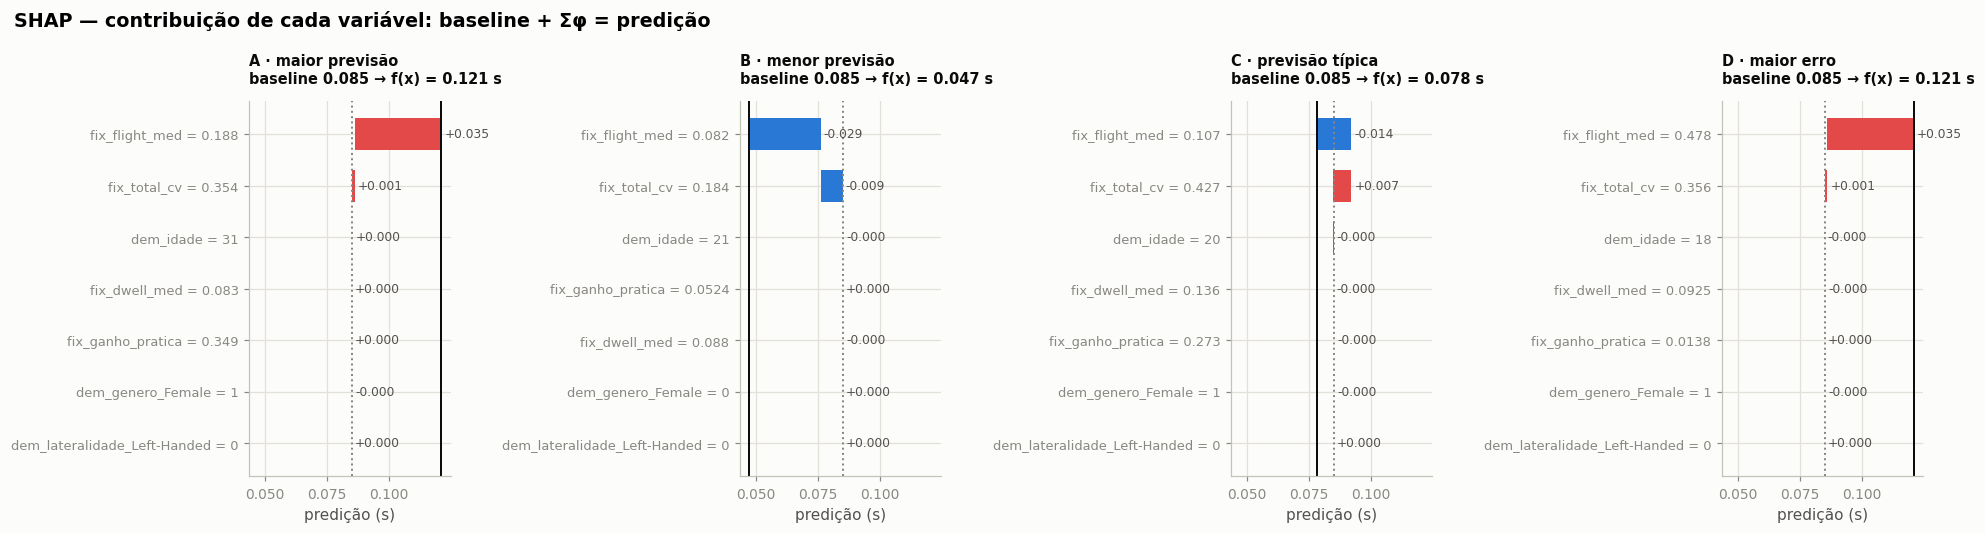

Contribuições φ (s) das quatro observações:


,A,B,C,D
fix_dwell_med,0.0000,-0.0000,-0.0001,-0.0000
fix_flight_med,0.0347,-0.0287,-0.0139,0.0348
fix_total_cv,0.0011,-0.0088,0.0073,0.0011
fix_ganho_pratica,0.0000,0.0001,-0.0001,0.0000
dem_idade,0.0001,-0.0002,-0.0002,-0.0001
dem_genero_Female,-0.0000,0.0000,-0.0000,-0.0000
dem_lateralidade_Left-Handed,0.0000,0.0000,0.0000,0.0000


In [30]:
# ══ C29 · Cascata SHAP (waterfall) ═══════════════════════════════════════
fig, axes = plt.subplots(1, 4, figsize=(18, 4.9), sharex=True)
for ax, (k, pid) in zip(axes, OBS.items()):
    phi = SV.loc[pid]
    ordem = list(phi.abs().sort_values().index)                  # base → topo: do menor ao maior |φ|
    acum = BASE_SHAP
    for pos, c in enumerate(ordem):
        ini, fim = acum, acum + phi[c]
        ax.barh(pos, fim - ini, left=ini, color=COR["pos"] if phi[c] > 0 else COR["neg"], height=0.62)
        ax.text(max(ini, fim) + 0.0012, pos, f"{phi[c]:+.3f}", va="center", fontsize=8, color=COR["tinta2"])
        acum = fim
    ax.axvline(BASE_SHAP, color=COR["suave"], linestyle=":", linewidth=1.3)
    ax.axvline(acum, color=COR["tinta"], linewidth=1.3)
    ax.set_yticks(range(len(ordem)))
    ax.set_yticklabels([f"{c} = {X_OBS[k][c]:.3g}" for c in ordem], fontsize=8.5)
    ax.set_title(f"{ROTULO[k]}\nbaseline {BASE_SHAP:.3f} → f(x) = {acum:.3f} s", fontsize=9.5)
    ax.set_xlabel("predição (s)")
    limpar_eixos(ax)
fig.suptitle("SHAP — contribuição de cada variável: baseline + Σφ = predição", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig15_shap_cascata.png")
plt.show()

print("Contribuições φ (s) das quatro observações:")
display(pd.DataFrame({k: SV.loc[pid] for k, pid in OBS.items()}).round(4))

### C29b · Gráfico de **barra local** e gráfico de **força** (SLIDE 07, pp. 27–32)

**Objetivo:** o SLIDE 07 apresenta mais duas formas de ver a **mesma** decomposição de **uma** observação:

- **Barra local** — o comprimento da barra é $|\phi_j|$, o sinal diz se a variável **aumenta** ou **reduz** a predição, e as variáveis são
  ordenadas pela magnitude. Responde: *quais variáveis mais contribuíram para esta predição específica?*
- **Força** (*force plot*) — as contribuições positivas **empurram** a predição numa direção (vermelho, à esquerda de $f(x)$) e as negativas na direção
  oposta (azul, à direita), levando de $\mathbb E[f(X)]$ até $f(x)$. Como a cascata, explica **uma** predição individual.

Nas duas, **o que muda é só o desenho**: os números são os $\phi_{ij}$ de C28.

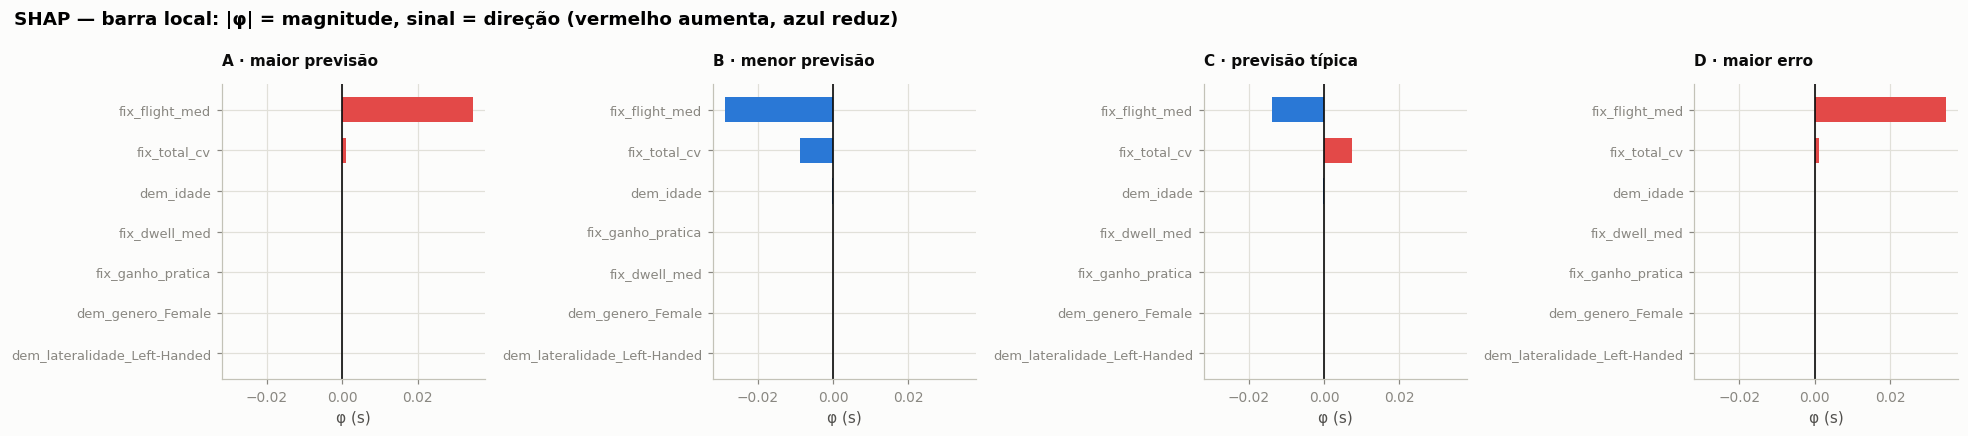

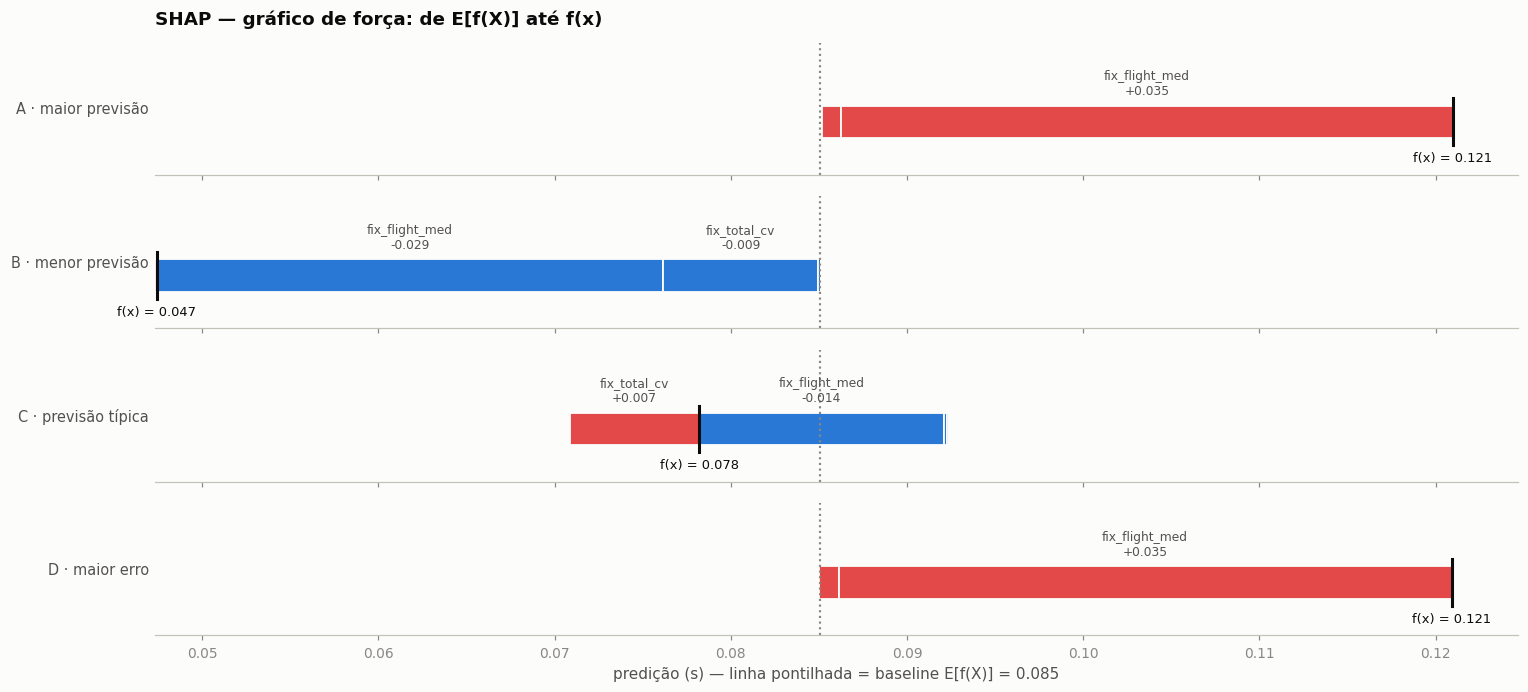

In [31]:
# ══ C29b · Barra local e força (quatro observações) ══════════════════════
fig, axes = plt.subplots(1, 4, figsize=(18, 4.0), sharex=True)
for ax, (k, pid) in zip(axes, OBS.items()):
    phi = SV.loc[pid].sort_values(key=lambda s: s.abs())               # maior |φ| no topo
    ax.barh(range(len(phi)), phi.values, color=[COR["pos"] if v > 0 else COR["neg"] for v in phi.values], height=0.62)
    ax.axvline(0, color=COR["tinta"], linewidth=1.1)
    ax.set_yticks(range(len(phi))); ax.set_yticklabels(phi.index, fontsize=8.5)
    ax.set_title(ROTULO[k], fontsize=10); ax.set_xlabel("φ (s)")
    limpar_eixos(ax)
fig.suptitle("SHAP — barra local: |φ| = magnitude, sinal = direção (vermelho aumenta, azul reduz)", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig15b_shap_barra_local.png")
plt.show()

fig, axes = plt.subplots(4, 1, figsize=(14, 6.4), sharex=True)
for ax, (k, pid) in zip(axes, OBS.items()):
    phi = SV.loc[pid]
    fx = BASE_SHAP + phi.sum()
    pos_ = phi[phi > 0].sort_values()                                  # menores primeiro: o maior fica junto de f(x)
    neg_ = (-phi[phi < 0]).sort_values(ascending=False)                # maiores junto de f(x)
    x0 = fx - pos_.sum()
    for c, v in pos_.items():
        ax.barh(0, v, left=x0, height=0.55, color=COR["pos"], edgecolor=COR["superficie"], linewidth=1.2)
        if v >= 0.003:
            ax.text(x0 + v / 2, 0.42, f"{c}\n{v:+.3f}", ha="center", va="bottom", fontsize=8, color=COR["tinta2"])
        x0 += v
    x0 = fx
    for c, v in neg_.items():
        ax.barh(0, v, left=x0, height=0.55, color=COR["neg"], edgecolor=COR["superficie"], linewidth=1.2)
        if v >= 0.003:
            ax.text(x0 + v / 2, 0.42, f"{c}\n{-v:+.3f}", ha="center", va="bottom", fontsize=8, color=COR["tinta2"])
        x0 += v
    ax.axvline(BASE_SHAP, color=COR["suave"], linestyle=":", linewidth=1.4)
    ax.plot([fx, fx], [-0.4, 0.4], color=COR["tinta"], linewidth=2)
    ax.text(fx, -0.5, f"f(x) = {fx:.3f}", ha="center", va="top", fontsize=8.5, color=COR["tinta"])
    ax.set_ylim(-0.9, 1.35); ax.set_yticks([]); ax.grid(False)
    ax.set_ylabel(ROTULO[k], rotation=0, ha="right", va="center", fontsize=9.5)
    limpar_eixos(ax, manter=("bottom",))
axes[-1].set_xlabel(f"predição (s) — linha pontilhada = baseline E[f(X)] = {BASE_SHAP:.3f}")
axes[0].set_title("SHAP — gráfico de força: de E[f(X)] até f(x)", loc="left")
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig15c_shap_forca.png")
plt.show()

### C30 · **Explicação global** a partir das locais: importância e distribuição dos $\phi$

**Objetivo:** como $\Phi$ tem uma linha por participante, a **importância global** é a **média de $|\phi_{ij}|$**;
e a nuvem de pontos (*beeswarm*) mostra, para cada variável, **como o valor da variável se relaciona com o sinal e
a magnitude da contribuição**. Esta é a ponte entre explicação **local** e **global** (SLIDE 01, p. 60).

**Como ler o *beeswarm*:** cada ponto é um participante; posição horizontal = $\phi_{ij}$ (à direita: aumenta a
hesitação prevista); **cor = valor da variável** (claro = baixo, escuro = alto).

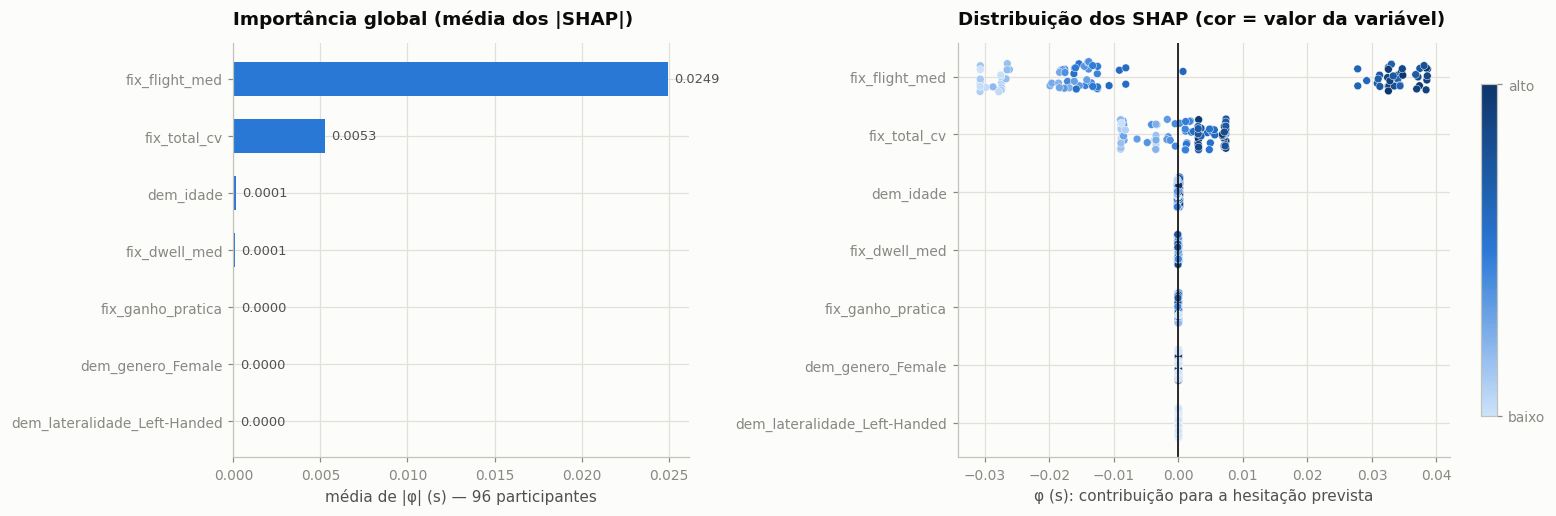

Ranking global (média |φ|): ['fix_flight_med', 'fix_total_cv', 'dem_idade', 'fix_dwell_med', 'fix_ganho_pratica', 'dem_genero_Female', 'dem_lateralidade_Left-Handed']


In [32]:
# ══ C30 · Importância global e beeswarm ══════════════════════════════════
media_abs = SV.abs().mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8), gridspec_kw={"width_ratios": [1, 1.35]})
ax = axes[0]
ax.barh(range(len(media_abs)), media_abs.values, color=COR["s1"], height=0.6)
for i, v in enumerate(media_abs.values):
    ax.text(v + media_abs.max() * 0.015, i, f"{v:.4f}", va="center", fontsize=8.5, color=COR["tinta2"])
ax.set_yticks(range(len(media_abs))); ax.set_yticklabels(media_abs.index)
ax.set_xlabel("média de |φ| (s) — 96 participantes"); ax.set_title("Importância global (média dos |SHAP|)")
limpar_eixos(ax)

ax = axes[1]
rng = np.random.RandomState(1)
cm = mpl.colors.LinearSegmentedColormap.from_list("v", ["#cde2fb", "#2a78d6", "#0d366b"])
for pos, c in enumerate(media_abs.index):
    vals = D_all[c]
    cor_v = vals.rank(pct=True) if c in COLS_CONT else vals
    ax.scatter(SV[c], pos + rng.uniform(-0.27, 0.27, len(SV)), c=cor_v, cmap=cm, s=26, edgecolor=COR["superficie"], linewidth=0.3)
ax.axvline(0, color=COR["tinta"], linewidth=1.1)
ax.set_yticks(range(len(media_abs))); ax.set_yticklabels(media_abs.index)
ax.set_xlabel("φ (s): contribuição para a hesitação prevista"); ax.set_title("Distribuição dos SHAP (cor = valor da variável)")
limpar_eixos(ax)
sm = mpl.cm.ScalarMappable(cmap=cm, norm=mpl.colors.Normalize(0, 1))
cb = fig.colorbar(sm, ax=ax, shrink=0.8, ticks=[0, 1]); cb.ax.set_yticklabels(["baixo", "alto"])
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig16_shap_global.png")
plt.show()
print("Ranking global (média |φ|):", list(media_abs.index[::-1]))

### C31 · Gráficos de dependência SHAP × curvas CP/ICE × **modelo linear**

**Objetivo:** duas conferências cruzadas entre os métodos.

**(a) SHAP × PDP.** Se uma variável **não interage** com as demais, o SHAP médio dado $x_j$ coincide com o PDP
centrado: $\bar\phi_j(x_j)\approx \mathrm{PDP}_j(x_j)-\mathbb E[\hat f]$. Sobrepomos a curva do PDP (calculada com o
**mesmo background**) à nuvem de $\phi_{ij}$: **dispersão vertical em torno da curva = interação** (o mesmo
fenômeno que o ICE mostrou como não paralelismo). A cor é a **variável parceira** sugerida por
`shap.utils.approximate_interactions`.

**(b) SHAP × modelo linear (SLIDE 03).** No modelo linear, o SHAP é exatamente $\beta_j(x_j-\bar x_j)$. As
contínuas em z-score têm média zero no treino, então $\phi_{ij}=\beta_jz_{ij}$ — **a fórmula da ATV2**. Para as
dummies, o SHAP **centra** em torno da média; o intercepto da ATV2 representava o *perfil de referência*, não a média
— a diferença é só um deslocamento constante do baseline.

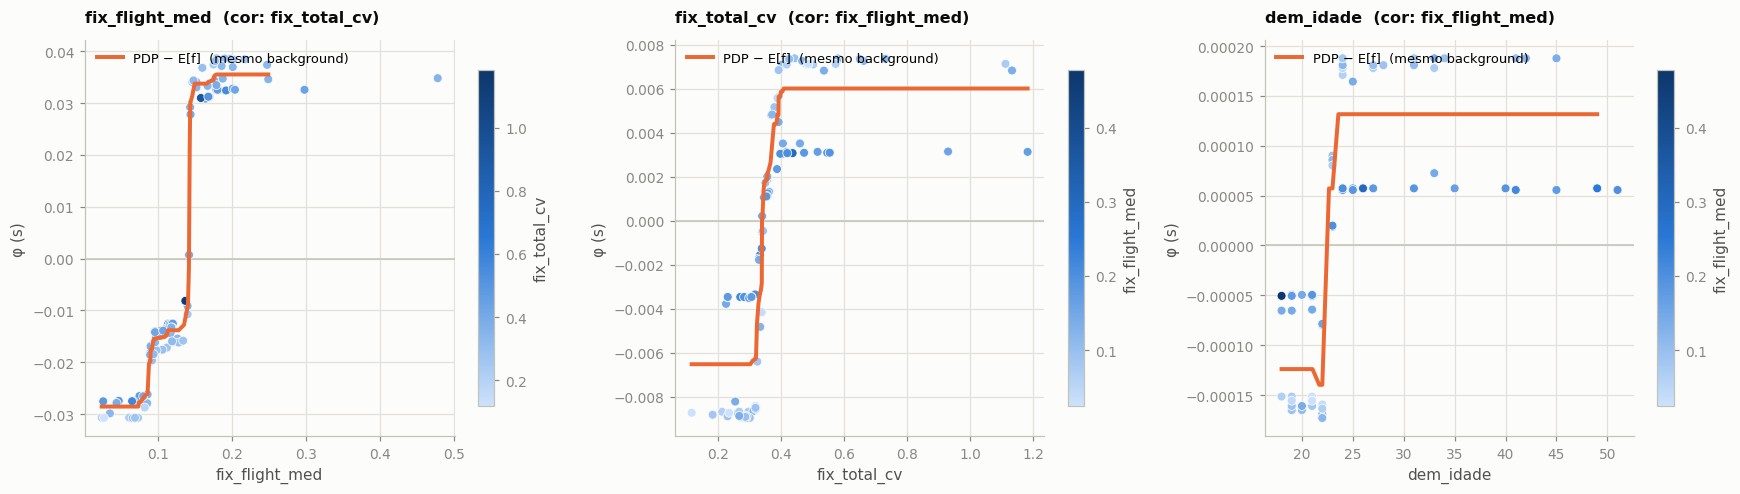

SHAP linear × β·z (ATV2) nas CONTÍNUAS — erro máximo: 6.94e-18
  dummy dem_genero_Female             : φ_SHAP = β·(d − média(d)); deslocamento do baseline = β·média(d) = -0.00521 s   (erro 0.0e+00)
  dummy dem_lateralidade_Left-Handed  : φ_SHAP = β·(d − média(d)); deslocamento do baseline = β·média(d) = -0.00020 s   (erro 0.0e+00)
Eficiência no modelo linear (baseline = predição média = 0.0846 s): erro máx 5.55e-17


In [33]:
# ══ C31 · Dependência SHAP × PDP; SHAP × modelo linear ═══════════════════
top3 = list(media_abs.index[::-1][:3])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, c in zip(axes, top3):
    j = COLS.index(c)
    ordem_int = [int(i) for i in shap.utils.approximate_interactions(j, SV.to_numpy(), D_all[COLS].to_numpy())]
    parceiro = COLS[next(i for i in ordem_int if i != j)]
    sc = ax.scatter(D_all[c], SV[c], c=D_all[parceiro], cmap=cm, s=34, edgecolor=COR["superficie"], linewidth=0.5, zorder=3)
    if c in COLS_CONT:
        g = GRADE_ICE[c]
        pdp_tr = ice_matriz(f_rf, D_tr, c, g).mean(axis=0) - BASELINE_RF        # mesmo background do SHAP
        ax.plot(g, pdp_tr, color=COR["s2"], linewidth=2.6, label="PDP − E[f]  (mesmo background)", zorder=4)
        ax.legend(fontsize=8.5, loc="upper left")
    ax.axhline(0, color=COR["eixo"], linewidth=1)
    fig.colorbar(sc, ax=ax, label=parceiro, shrink=0.85)
    ax.set_xlabel(c); ax.set_ylabel("φ (s)"); ax.set_title(f"{c}  (cor: {parceiro})", fontsize=10.5)
    limpar_eixos(ax)
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig17_shap_dependencia.png")
plt.show()

# ── (b) SHAP do modelo linear == β_j · z_ij (ATV2) ───────────────────────
ct, reg = lin[0], lin[-1]
Zm_tr, Zm_all = ct.transform(D_tr), ct.transform(D_all[COLS])
SV_LIN = pd.DataFrame(shap.LinearExplainer(reg, Zm_tr).shap_values(Zm_all), index=D_all.index, columns=Zm_all.columns)[COLS]
atv2_phi = Zm_all[COLS_CONT] * beta_z[COLS_CONT]                                      # φ_ij = β_j · z_ij  (SLIDE 03 / ATV2 C24)
dif_cont = float((SV_LIN[COLS_CONT] - atv2_phi).abs().max().max())
print(f"SHAP linear × β·z (ATV2) nas CONTÍNUAS — erro máximo: {dif_cont:.2e}")
for c in COLS_DUM:
    desloc = beta_z[c] * D_tr[c].mean()
    dif = float((SV_LIN[c] - (beta_z[c] * D_all[c] - desloc)).abs().max())
    print(f"  dummy {c:<30s}: φ_SHAP = β·(d − média(d)); deslocamento do baseline = β·média(d) = {desloc:+.5f} s   (erro {dif:.1e})")
assert dif_cont < 1e-9
erro_lin = np.abs(float(lin.predict(D_tr).mean()) + SV_LIN.sum(axis=1).to_numpy() - f_lin(D_all))
print(f"Eficiência no modelo linear (baseline = predição média = {float(lin.predict(D_tr).mean()):.4f} s): erro máx {erro_lin.max():.2e}")

### C31b · As propriedades do SLIDE 07 que faltam: **simetria**, **jogador nulo** e **aditividade**

**Objetivo:** a eficiência já foi verificada (C26b, C27, C28). Aqui testamos as outras três propriedades do SLIDE 07 (p. 20):

1. **Simetria + jogador nulo** num **jogo-brinquedo** onde a resposta é conhecida: $f=a\cdot b+2c$, com $d$ **fora** da fórmula. As variáveis
   $a$ e $b$ entram do **mesmo** modo (e a observação e o *background* são simétricos em $a\leftrightarrow b$) ⇒ $\phi_a=\phi_b$; a variável $d$ nunca altera
   o resultado ⇒ $\phi_d=0$.
2. **Aditividade** no nosso problema: o SHAP da **média de dois modelos** (floresta e linear) tem de ser a **média** dos SHAPs de cada um — $\phi[\tfrac12 f_{RF}+\tfrac12 f_{lin}]=\tfrac12\phi[f_{RF}]+\tfrac12\phi[f_{lin}]$.

In [34]:
# ══ C31b · Simetria, jogador nulo e aditividade ══════════════════════════
# (1) Jogo-brinquedo: f = a*b + 2c ; d não entra. (a, b) do background são simétricos sob a troca a <-> b.
def f_toy(X):
    return (X["a"] * X["b"] + 2 * X["c"]).to_numpy(float)


fundo_toy = pd.DataFrame({"a": [0, 1, 2, 3, 1], "b": [1, 0, 3, 2, 1], "c": [0, 2, 1, 3, 1], "d": [5, 1, 0, 2, 4]}).astype(float)
x_toy = pd.Series({"a": 2.0, "b": 2.0, "c": 1.0, "d": 7.0})
phi_toy, e_toy, f_x_toy = shapley_exato(f_toy, x_toy, fundo_toy, cols=["a", "b", "c", "d"])
print("JOGO-BRINQUEDO  f = a·b + 2c  (d fora da fórmula)")
display(pd.DataFrame({"x": x_toy, "φ": phi_toy}, index=x_toy.index).round(6))
print(f"  SIMETRIA     : φ_a = {phi_toy[0]:.6f}   φ_b = {phi_toy[1]:.6f}   |φ_a − φ_b| = {abs(phi_toy[0] - phi_toy[1]):.1e}")
print(f"  JOGADOR NULO : φ_d = {phi_toy[3]:.1e}")
print(f"  EFICIÊNCIA   : E[f] + Σφ = {e_toy + phi_toy.sum():.6f}   f(x) = {f_x_toy:.6f}")
assert abs(phi_toy[0] - phi_toy[1]) < 1e-12 and abs(phi_toy[3]) < 1e-12 and abs(e_toy + phi_toy.sum() - f_x_toy) < 1e-12

# (2) Aditividade: φ[(f_RF + f_lin)/2] = (φ[f_RF] + φ[f_lin]) / 2, no problema real
f_mix = lambda X: 0.5 * f_rf(X) + 0.5 * f_lin(X)
erros_ad = []
for k, x in X_OBS.items():
    p_mix, _, _ = shapley_exato(f_mix, x, D_tr)
    p_rf, _, _ = shapley_exato(f_rf, x, D_tr)
    p_li, _, _ = shapley_exato(f_lin, x, D_tr)
    erros_ad.append(np.abs(p_mix - 0.5 * (p_rf + p_li)).max())
print(f"\nADITIVIDADE — máx |φ[½RF + ½linear] − ½(φ[RF] + φ[linear])| nas 4 observações: {max(erros_ad):.1e}")
assert max(erros_ad) < 1e-12
print("As quatro propriedades do SLIDE 07 (eficiência, simetria, jogador nulo, aditividade) valem numericamente.")

JOGO-BRINQUEDO  f = a·b + 2c  (d fora da fórmula)


,x,φ
a,2.0000,0.7000
b,2.0000,0.7000
c,1.0000,-0.8000
d,7.0000,0.0000


  SIMETRIA     : φ_a = 0.700000   φ_b = 0.700000   |φ_a − φ_b| = 0.0e+00
  JOGADOR NULO : φ_d = 0.0e+00
  EFICIÊNCIA   : E[f] + Σφ = 6.000000   f(x) = 6.000000



ADITIVIDADE — máx |φ[½RF + ½linear] − ½(φ[RF] + φ[linear])| nas 4 observações: 2.8e-17
As quatro propriedades do SLIDE 07 (eficiência, simetria, jogador nulo, aditividade) valem numericamente.


### C32 · Sensibilidade do SHAP ao **background** e ao **algoritmo**

**Objetivo:** o SHAP **depende da referência** ("em relação a quê?") — o SLIDE 06 faz a mesma pergunta ao LIME
(*"a vizinhança permanece arbitrária"*) e o SLIDE 07 (p. 35) a resume: *os valores SHAP não dependem apenas do modelo e da observação, mas também da
definição usada para representar as variáveis ausentes* (marginal × condicional). Comparamos, para as quatro observações:

| Variante | O que muda |
|---|---|
| **A · todo o treino (67)** | referência de **todo o treino** (a usada no resto da seção) |
| **B · 20 sorteados × 10** | *background* pequeno e aleatório — o que acontece com amostras reduzidas |
| **C · um único ponto (medianas)** | referência = "indivíduo mediano" — o SHAP vira uma comparação com **um** perfil |
| **D · *path-dependent*** | `TreeExplainer` sem *background*: usa a cobertura das folhas (distribuição **condicional** aproximada) |

Medidas: correlação de Spearman e diferença máxima de $\phi$ em relação a (A); e se o atributo principal muda.

In [35]:
# ══ C32 · SHAP: background e algoritmo ═══════════════════════════════════
def phi_de(explicador, x):
    return pd.Series(explicador.shap_values(x.to_frame().T[COLS], check_additivity=False)[0], index=COLS)


ref_A = {k: phi_de(expl_tree, x) for k, x in X_OBS.items()}
mediano = pd.DataFrame([D_tr.median()], columns=COLS)
expl_C = shap.TreeExplainer(rf, data=mediano, feature_perturbation="interventional")
expl_D = shap.TreeExplainer(rf, feature_perturbation="tree_path_dependent")

linhas = []
for k, x in X_OBS.items():
    candidatos = {"B · 20 sorteados (média de 10)": None, "C · ponto mediano": phi_de(expl_C, x), "D · path-dependent": phi_de(expl_D, x)}
    rng = np.random.RandomState(SEMENTE)
    phis_B = [phi_de(shap.TreeExplainer(rf, data=D_tr.sample(20, random_state=int(rng.randint(1e6))),
                                         feature_perturbation="interventional"), x) for _ in range(10)]
    candidatos["B · 20 sorteados (média de 10)"] = pd.concat(phis_B, axis=1).mean(axis=1)
    sd_B = pd.concat(phis_B, axis=1).std(axis=1).max()
    for nome, p in candidatos.items():
        linhas.append({"obs": k, "variante": nome,
                       "Spearman vs A": stats.spearmanr(p, ref_A[k])[0],
                       "máx |Δφ| vs A (s)": float((p - ref_A[k]).abs().max()),
                       "atributo top-1": p.abs().idxmax(), "top-1 de A": ref_A[k].abs().idxmax(),
                       "dp entre sorteios (B)": sd_B if nome.startswith("B") else np.nan})
tab_bg = pd.DataFrame(linhas)
display(tab_bg.round(4))
tab_bg.to_csv(DIR_SAIDA / "tabela_shap_background.csv", index=False)

,obs,variante,Spearman vs A,máx |Δφ| vs A (s),atributo top-1,top-1 de A,dp entre sorteios (B)
0,A,B · 20 sorteados (média de 10),1.0000,0.0019,fix_flight_med,fix_flight_med,0.0049
1,A,C · ponto mediano,0.4643,0.0130,fix_flight_med,fix_flight_med,NaN
2,A,D · path-dependent,1.0000,0.0002,fix_flight_med,fix_flight_med,NaN
3,B,B · 20 sorteados (média de 10),1.0000,0.0018,fix_flight_med,fix_flight_med,0.0054
4,B,C · ponto mediano,0.7783,0.0162,fix_total_cv,fix_flight_med,NaN
5,B,D · path-dependent,1.0000,0.0005,fix_flight_med,fix_flight_med,NaN
6,C,B · 20 sorteados (média de 10),1.0000,0.0015,fix_flight_med,fix_flight_med,0.0045
7,C,C · ponto mediano,0.7412,0.0126,fix_total_cv,fix_flight_med,NaN
8,C,D · path-dependent,1.0000,0.0005,fix_flight_med,fix_flight_med,NaN
9,D,B · 20 sorteados (média de 10),0.9643,0.0019,fix_flight_med,fix_flight_med,0.0049


### C32b · Custo computacional: **por que existem KernelSHAP e TreeSHAP** (SLIDE 07, pp. 33–34)

**Objetivo:** o valor exato exige $2^P$ coalizões. Medimos o tempo das **três vias** para uma observação ($P=7$) e **extrapolamos** o custo da
enumeração para $P$ maiores — a razão de existirem algoritmos específicos. (A extrapolação supõe tempo proporcional a $2^P$ e **não** inclui o aumento
do custo de cada predição; é uma ordem de grandeza, não uma medição.)

In [36]:
# ══ C32b · Custo: 2^P e as três vias ═════════════════════════════════════
xA = X_OBS["A"]


def _tempo(fn, n=3):
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))


t_ex = _tempo(lambda: shapley_exato(f_rf, xA, D_tr), n=2)
t_tr = _tempo(lambda: expl_tree.shap_values(xA.to_frame().T[COLS], check_additivity=False))
t_kn = _tempo(lambda: expl_kern.shap_values(xA.to_numpy(float).reshape(1, -1), nsamples=2 ** len(COLS), silent=True), n=1)
print(f"Tempo para UMA observação (P = {len(COLS)}, background de {len(D_tr)}): enumeração exata {t_ex:.3f} s · "
      f"KernelSHAP {t_kn:.3f} s · TreeSHAP {t_tr:.4f} s   (TreeSHAP é ≈ {t_ex / t_tr:,.0f}× mais rápido que a enumeração)")


def humano(seg):
    for lim, un in ((60, "s"), (3600, "min"), (86400, "h"), (86400 * 365, "dias")):
        if seg < lim:
            return f"{seg / {'s': 1, 'min': 60, 'h': 3600, 'dias': 86400}[un]:,.1f} {un}"
    return f"{seg / (86400 * 365):,.2g} anos"


custo_2p = pd.DataFrame({"P (variáveis)": [3, 7, 10, 15, 20, 30, 50]})
custo_2p["coalizões 2^P"] = [2 ** p for p in custo_2p["P (variáveis)"]]
custo_2p["tempo estimado da enumeração"] = [humano(t_ex * 2 ** p / 2 ** len(COLS)) for p in custo_2p["P (variáveis)"]]
display(custo_2p)
print("Com P = 7 a enumeração leva menos de um segundo — por isso podemos usá-la como AUDITORIA dos algoritmos rápidos.")

Tempo para UMA observação (P = 7, background de 67): enumeração exata 0.172 s · KernelSHAP 0.292 s · TreeSHAP 0.0023 s   (TreeSHAP é ≈ 74× mais rápido que a enumeração)


,P (variáveis),coalizões 2^P,tempo estimado da enumeração
0,3,8,0.0 s
1,7,128,0.2 s
2,10,1024,1.4 s
3,15,32768,44.1 s
4,20,1048576,23.5 min
5,30,1073741824,16.7 dias
6,50,1125899906842624,4.8e+04 anos


Com P = 7 a enumeração leva menos de um segundo — por isso podemos usá-la como AUDITORIA dos algoritmos rápidos.


### Interpretação — SHAP

**0. O exemplo do SLIDE 07 e as quatro propriedades (C26b, C31b).** Refeito com a fórmula do slide *e* como média sobre as $3!=6$ ordens, o exemplo dá
$\phi(x_1)=31/6\approx5{,}17$, $\phi(x_2)=55/6\approx9{,}17$ e $\phi(x_3)=34/6\approx5{,}67$ — soma **20 = f(x) − f(∅)**, como exige a eficiência. ⚠️ O slide (p. 19)
lista $8{,}17$ e $5{,}83$ para $x_2$ e $x_3$, que somam $19{,}17$ e **não** fecham; o valor de $x_1$ confere. Vale conferir o slide antes de reproduzir
esses números. Simetria ($\phi_a=\phi_b$), jogador nulo ($\phi_d=0$) e aditividade (erro $3\times10^{-17}$ ao somar dois modelos) valem numericamente.

**0b. Três desenhos, a mesma decomposição (C29, C29b).** A **barra local** responde *"quais variáveis mais contribuíram?"* (em todas as observações só **duas**
barras são visíveis: `fix_flight_med` e `fix_total_cv`); a **cascata** mostra a soma $\phi_0\to\cdots\to f(x)$; o gráfico de **força** mostra o "cabo de guerra":
em **C**, `cv` (+0,007) **empurra para cima** e `flight` (−0,014) **para baixo**, e o resultado (0,078 s) fica pouco abaixo do baseline (0,085 s). Em A, B e D só um lado puxa.

**0c. Custo (C32b).** Para P = 7 a enumeração exata leva ≈ 0,2 s (TreeSHAP, ≈ 2 ms); a extrapolação $2^P$ dá **≈ 24 min com P = 20** e **≈ 17 dias com P = 30**
(ordem de grandeza): é por isso que, fora de problemas pequenos, usa-se **TreeSHAP** (árvores) ou **KernelSHAP** (qualquer modelo, aproximado).

**1. As garantias do método foram verificadas, não assumidas.** A enumeração exata das 128 coalições, o `TreeExplainer` e o
`KernelExplainer` **coincidem** nas quatro observações (diferença máxima ≈ 10⁻¹⁰ s), e a **eficiência** vale ao nível da
precisão de máquina (erro 5,6×10⁻¹⁷ s nos 96 participantes). As variáveis que a floresta não usa (gênero e lateralidade)
têm $\phi\equiv0$ — a propriedade do **jogador nulo**. Um registro honesto: o `TreeExplainer` diverge da enumeração em **1 dos
96** participantes (p099, até 1,1×10⁻³ s) por um **empate numérico com um limiar de divisão** (`fix_total_cv = 0,3312854…`); por isso a
matriz $\Phi$ usada daqui em diante vem da **enumeração exata**.

**2. Explicação local — baseline 0,0851 s (média das predições no treino).**

| Obs. | $\phi_\text{flight}$ | $\phi_\text{cv}$ | demais | $\hat f(x)$ |
|---|---|---|---|---|
| **A** | **+0,0347** | +0,0011 | ≈ 0 | 0,121 s |
| **B** | **−0,0287** | −0,0088 | ≈ 0 | 0,047 s |
| **C** | **−0,0139** | **+0,0073** | ≈ 0 | 0,078 s |
| **D** | **+0,0348** | +0,0011 | ≈ 0 | 0,121 s |

- **A**: o aumento de +0,036 s sobre o baseline vem **quase todo** de `flight` (97%).
- **B**: duas contribuições **negativas** somam −0,038 s: `flight` baixo (−0,029) e `cv` baixo (−0,009).
- **C (o caso típico)**: `flight` **reduz** (−0,014) e `cv` **aumenta** (+0,007) — as forças **se cancelam parcialmente** e a
  predição fica perto do baseline (−0,007 s). "Típico" aqui significa **forças opostas**, não ausência de forças.
- **D**: contribuições **idênticas às de A**. O erro de 0,12 s (observado 0,243 s) **não está em nenhum φ**: o SHAP explica a
  **predição** (0,121 s), não o **resíduo**.

**3. Explicação global (C30).** Média de $|\phi|$: `fix_flight_med` **0,0249 s**, `fix_total_cv` **0,0053 s**, e **≤ 0,0001 s** para as
demais (zero para as dummies). A ordem coincide com a importância por impureza da floresta (0,878 e 0,115) e com a amplitude do PDP.

**4. SHAP × ICE/PDP (C31).** Para `fix_flight_med`, a nuvem de $\phi$ **sobrepõe-se** ao PDP centrado (mesmo degrau em 0,14 s) e a
dispersão vertical é pequena — o modelo é quase **aditivo** nessa variável (coerente com $U=0{,}02$). Para `fix_total_cv` a dispersão
em torno da curva é **grande** e a cor mostra que ela é organizada por `fix_flight_med`: a **mesma interação** que o ICE revelou, agora
vista como "o mesmo valor de `cv` contribui diferente conforme o `flight` do indivíduo".

**5. SHAP × modelo linear da ATV2 (C31).** No modelo linear, o SHAP é exatamente $\beta_jz_{ij}$ (erro 7×10⁻¹⁸ s) — **a decomposição
do SLIDE 03 é um caso particular do SHAP**. Nas dummies, o SHAP centra na média, deslocando o baseline em $\beta\bar d$
(−0,0052 s para gênero): a diferença entre "perfil de referência" (ATV2) e "média" (SHAP).

**6. A referência define a pergunta (C32).**

| Variante | Resultado |
|---|---|
| 20 sorteados do treino (10 repetições) | ranking idêntico (Spearman 0,96–1,0); Δφ máx ≈ 0,002 s, mas o **desvio entre sorteios chega a 0,005 s** — do tamanho de $\phi_\text{cv}$: *background* pequeno ruidoso |
| **ponto único (medianas)** | **muda o ranking** (Spearman 0,25–0,78) e, em **B e C, o atributo principal passa a ser `cv`**; Δφ até 0,016 s |
| *path-dependent* (sem *background*) | praticamente igual (Spearman ≥ 0,96; Δφ ≤ 0,0005 s) — as variáveis são pouco dependentes |

Com uma superfície em **degraus**, comparar com **uma** pessoa de referência (a mediana está no meio da escada) é uma pergunta
diferente de comparar com a **média sobre todos**. O SHAP **não é "a" resposta**: é a resposta **a uma pergunta declarada** — "em
relação ao treino".

> **Ressalva (herdada do CP e do LIME):** o SHAP *interventional* também avalia o modelo em combinações construídas (indivíduo + *background*);
> com variáveis fracamente correlacionadas (aqui) o risco é pequeno, mas **não nulo** — e para o *outlier* D o suporte é inexistente.

---
# §6 · Etapa 6 — Método adicional: **explicações contrafactuais**

**Objetivo da seção:** aplicar um método local **à escolha do grupo** e descrever seu funcionamento.
Escolhemos as **explicações contrafactuais** (Wachter et al., 2017) — e a escolha tem justificativa dentro da
disciplina, não apenas de catálogo.

### Por que contrafactuais?

1. **Respondem a uma pergunta que nenhum dos quatro métodos anteriores responde diretamente.** CP/ICE dizem *como a
   predição varia*; LIME e SHAP dizem *quanto cada variável contribuiu*. O contrafactual diz **o que precisaria ser
   diferente para a predição ser outra**: *"por que A e não B?"* — a forma de explicação **contrastiva** que o SLIDE 01
   (pp. 53–54) aponta como a mais próxima do raciocínio humano (*"recourse: o que precisaria mudar para alterar a
   decisão?"*).
2. **Fecha o arco da ATV2.** A auditoria da ATV2 (C39) perguntava: *"esse contraste é plausível e acionável?
   destreza motora é treinável; idade e lateralidade não são."* Aqui isso vira **método**: só as variáveis motoras
   podem mudar; idade, gênero e lateralidade ficam **imutáveis**.
3. **É, na essência, um CP com meta.** A busca percorre a mesma grade de perturbações do CP, mas procura a **menor
   mudança que atinja um alvo** — o que permite aplicar à busca o mesmo teste de **suporte nos dados** já usado
   no CP e no LIME.

### Como funciona (algoritmo implementado do zero)

Dado o indivíduo $x$, um **alvo** (intervalo de predição $[\ell,u]$) e o conjunto de variáveis **acionáveis** $\mathcal A$:

$$x^{\mathrm{cf}}=\arg\min_{x'}\ \sum_{j\in\mathcal A}\frac{|x'_j-x_j|}{\sigma_j}\quad\text{s.a.}\quad \hat f(x')\in[\ell,u],\ \ x'_j=x_j\ \forall j\notin\mathcal A,\ \ x'\ \text{com suporte nos dados}.$$

- **Proximidade:** custo $L_1$ em unidades de desvio-padrão (favorece **poucas** variáveis alteradas — *esparsidade*);
- **Busca exaustiva** em grade de quantis, por **tamanho de subconjunto** $k=1,2,3,4$ (grades de 101, 41, 17 e 9 pontos);
  reportamos a melhor solução **de cada $k$**;
- **Plausibilidade:** o mesmo critério de C11 (distância ao dado real mais próximo ≤ p95 das distâncias LOO). Mostramos
  a melhor solução **plausível** e, se diferir, a melhor **irrestrita** — a diferença é o preço da plausibilidade;
- **Contrafactuais reais:** além do ponto sintético, listamos **participantes reais** com predição no alvo e perfil
  mais próximo — existem por construção, então são plausíveis.

### Alvos (a pergunta contrastiva de cada observação)

| Obs. | Contraste | Alvo para a predição |
|---|---|---|
| **A** (previsão alta) | *"o que faria o modelo prever uma hesitação típica?"* | ≤ mediana do treino |
| **B** (previsão baixa) | *"e uma hesitação típica?"* | ≥ mediana do treino |
| **C** (típica) | *"o que a levaria ao grupo de hesitação alta?"* | ≥ 3º quartil do treino |
| **D** (maior erro) | *"o que o modelo precisaria ver para prever o que realmente aconteceu?"* | valor **observado** ± 0,25 DP |

> **Limitações que o método impõe e que declaramos:** (i) contrafactuais **não são únicos** (o problema de
> multiplicidade): outra função de custo daria outro ponto; (ii) a explicação descreve o **modelo**, não uma
> intervenção possível no mundo — "reduzir o *flight time* de um digitador" não é uma ação que o dataset permita
> afirmar que funciona; (iii) a floresta **não extrapola**: o alvo pode ser **inalcançável**, e isso é um achado.

### C33 · Busca de contrafactuais

In [37]:
# ══ C33 · Contrafactuais: busca exaustiva em grade ═══════════════════════
ACIONAVEIS = ["fix_dwell_med", "fix_flight_med", "fix_total_cv", "fix_ganho_pratica"]
IMUTAVEIS = [c for c in COLS if c not in ACIONAVEIS]
mediana_y, q3_y, tol_y = float(y_tr.median()), float(y_tr.quantile(0.75)), 0.25 * float(y_tr.std())
y_D = float(y_all[OBS["D"]])
ALVOS = {"A": (-np.inf, mediana_y), "B": (mediana_y, np.inf), "C": (q3_y, np.inf), "D": (y_D - tol_y, y_D + tol_y)}
print("Imutáveis (fixas):", IMUTAVEIS)
print("Acionáveis       :", ACIONAVEIS)
print("Alvos:", {k: (round(lo, 4) if np.isfinite(lo) else "−∞", round(hi, 4) if np.isfinite(hi) else "+∞") for k, (lo, hi) in ALVOS.items()})


def buscar_contrafactuais(f, x, alvo, n_por_k=None):
    n_por_k = n_por_k or {1: 101, 2: 41, 3: 17, 4: 9}
    lo, hi = alvo
    base = x[COLS].to_numpy(float)
    linhas = []
    for k, n in n_por_k.items():
        melhor = {"plausível": None, "irrestrita": None}
        for S in combinations(ACIONAVEIS, k):
            grades = [np.union1d(np.quantile(D_tr[v], np.linspace(0, 1, n)), [x[v]]) for v in S]
            malha = np.stack(np.meshgrid(*grades, indexing="ij"), -1).reshape(-1, k)
            idx = [COLS.index(v) for v in S]
            A = np.tile(base, (len(malha), 1))
            A[:, idx] = malha
            X = pd.DataFrame(A, columns=COLS)
            pred = f(X)
            ok = (pred >= lo) & (pred <= hi) & np.all(np.abs(malha - base[idx]) > 1e-12, axis=1)   # as k variáveis MUDAM
            if not ok.any():
                continue
            custo = (np.abs(malha - base[idx]) / SD[list(S)].to_numpy()).sum(axis=1)
            dist = dist_ao_treino(X)
            for tipo, mask in (("plausível", ok & (dist <= LIM_SUPORTE)), ("irrestrita", ok)):
                if mask.any():
                    i = np.where(mask)[0][np.argmin(custo[mask])]
                    if melhor[tipo] is None or custo[i] < melhor[tipo]["custo (Σ|Δz|)"]:
                        melhor[tipo] = {"variáveis": ", ".join(S),
                                        "mudanças": "; ".join(f"{v}: {x[v]:.3g}→{malha[i, j]:.3g}" for j, v in enumerate(S)),
                                        "Δz": {v: (malha[i, j] - x[v]) / SD[v] for j, v in enumerate(S)},
                                        "custo (Σ|Δz|)": float(custo[i]), "nova predição (s)": float(pred[i]),
                                        "dist. ao treino": float(dist[i]), "plausível": bool(dist[i] <= LIM_SUPORTE)}
        for tipo, r in melhor.items():
            if r is not None:
                linhas.append({"k": k, "tipo": tipo, **r})
    return pd.DataFrame(linhas, columns=["k", "tipo", "variáveis", "mudanças", "Δz", "custo (Σ|Δz|)",
                                         "nova predição (s)", "dist. ao treino", "plausível"])


def faixa_alcancavel(f, x, n=11):
    # Menor e maior predição possíveis mexendo SÓ nas variáveis acionáveis (grade de n quantis cada).
    grades = [np.union1d(np.quantile(D_tr[v], np.linspace(0, 1, n)), [x[v]]) for v in ACIONAVEIS]
    malha = np.stack(np.meshgrid(*grades, indexing="ij"), -1).reshape(-1, len(ACIONAVEIS))
    A = np.tile(x[COLS].to_numpy(float), (len(malha), 1))
    A[:, [COLS.index(v) for v in ACIONAVEIS]] = malha
    p = f(pd.DataFrame(A, columns=COLS))
    return float(p.min()), float(p.max())


t0 = time.time()
CF = {k: buscar_contrafactuais(f_rf, x, ALVOS[k]) for k, x in X_OBS.items()}
print(f"Busca concluída em {time.time()-t0:.1f} s\n")
for k, x in X_OBS.items():
    fx = float(f_rf(x.to_frame().T)[0])
    lo_a, hi_a = faixa_alcancavel(f_rf, x)
    print(f"── {ROTULO[k]} ── predição atual {fx:.4f} s | alvo {ALVOS[k][0]:.4f}..{ALVOS[k][1]:.4f} | "
          f"faixa alcançável mexendo só nas acionáveis: [{lo_a:.4f}, {hi_a:.4f}] s")
    if len(CF[k]) == 0:
        print("   NENHUM contrafactual: o alvo está fora do que a floresta consegue prever com essas variáveis.")
    else:
        display(CF[k].drop(columns=["Δz"]).round(4))

Imutáveis (fixas): ['dem_idade', 'dem_genero_Female', 'dem_lateralidade_Left-Handed']
Acionáveis       : ['fix_dwell_med', 'fix_flight_med', 'fix_total_cv', 'fix_ganho_pratica']
Alvos: {'A': ('−∞', 0.081), 'B': (0.081, '+∞'), 'C': (0.1145, '+∞'), 'D': (0.2329, 0.2531)}


Busca concluída em 8.7 s



── A · maior previsão ── predição atual 0.1210 s | alvo -inf..0.0810 | faixa alcançável mexendo só nas acionáveis: [0.0457, 0.1210] s


,k,tipo,variáveis,mudanças,custo (Σ|Δz|),nova predição (s),dist. ao treino,plausível
0,1,plausível,fix_flight_med,fix_flight_med: 0.188→0.141,0.9223,0.0777,1.2260,True
1,1,irrestrita,fix_flight_med,fix_flight_med: 0.188→0.141,0.9223,0.0777,1.2260,True
2,2,plausível,"fix_flight_med, fix_total_cv",fix_flight_med: 0.188→0.135; fix_total_cv: 0.3...,1.0321,0.0743,1.2295,True
3,2,irrestrita,"fix_flight_med, fix_total_cv",fix_flight_med: 0.188→0.135; fix_total_cv: 0.3...,1.0321,0.0743,1.2295,True
4,3,plausível,"fix_dwell_med, fix_flight_med, fix_total_cv",fix_dwell_med: 0.083→0.0833; fix_flight_med: 0...,1.0812,0.0788,1.2392,True
5,3,irrestrita,"fix_dwell_med, fix_flight_med, fix_total_cv",fix_dwell_med: 0.083→0.0833; fix_flight_med: 0...,1.0812,0.0788,1.2392,True
6,4,plausível,"fix_dwell_med, fix_flight_med, fix_total_cv, f...",fix_dwell_med: 0.083→0.0833; fix_flight_med: 0...,1.2699,0.0784,1.2418,True
7,4,irrestrita,"fix_dwell_med, fix_flight_med, fix_total_cv, f...",fix_dwell_med: 0.083→0.0833; fix_flight_med: 0...,1.2699,0.0784,1.2418,True


── B · menor previsão ── predição atual 0.0474 s | alvo 0.0810..inf | faixa alcançável mexendo só nas acionáveis: [0.0453, 0.1211] s


,k,tipo,variáveis,mudanças,custo (Σ|Δz|),nova predição (s),dist. ao treino,plausível
0,1,plausível,fix_flight_med,fix_flight_med: 0.082→0.143,1.1950,0.1023,1.2142,True
1,1,irrestrita,fix_flight_med,fix_flight_med: 0.082→0.143,1.1950,0.1023,1.2142,True
2,2,plausível,"fix_flight_med, fix_ganho_pratica",fix_flight_med: 0.082→0.144; fix_ganho_pratica...,1.2517,0.1138,1.1898,True
3,2,irrestrita,"fix_flight_med, fix_ganho_pratica",fix_flight_med: 0.082→0.144; fix_ganho_pratica...,1.2517,0.1138,1.1898,True
4,3,plausível,"fix_dwell_med, fix_flight_med, fix_ganho_pratica",fix_dwell_med: 0.088→0.0879; fix_flight_med: 0...,1.3619,0.1170,1.1847,True
5,3,irrestrita,"fix_dwell_med, fix_flight_med, fix_ganho_pratica",fix_dwell_med: 0.088→0.0879; fix_flight_med: 0...,1.3619,0.1170,1.1847,True
6,4,plausível,"fix_dwell_med, fix_flight_med, fix_total_cv, f...",fix_dwell_med: 0.088→0.089; fix_flight_med: 0....,2.3435,0.1182,1.2060,True
7,4,irrestrita,"fix_dwell_med, fix_flight_med, fix_total_cv, f...",fix_dwell_med: 0.088→0.089; fix_flight_med: 0....,2.3435,0.1182,1.2060,True


── C · previsão típica ── predição atual 0.0782 s | alvo 0.1145..inf | faixa alcançável mexendo só nas acionáveis: [0.0453, 0.1211] s


,k,tipo,variáveis,mudanças,custo (Σ|Δz|),nova predição (s),dist. ao treino,plausível
0,1,plausível,fix_flight_med,fix_flight_med: 0.107→0.144,0.7189,0.1161,1.0185,True
1,1,irrestrita,fix_flight_med,fix_flight_med: 0.107→0.144,0.7189,0.1161,1.0185,True
2,2,plausível,"fix_flight_med, fix_ganho_pratica",fix_flight_med: 0.107→0.144; fix_ganho_pratica...,0.7373,0.1161,1.0288,True
3,2,irrestrita,"fix_flight_med, fix_ganho_pratica",fix_flight_med: 0.107→0.144; fix_ganho_pratica...,0.7373,0.1161,1.0288,True
4,3,plausível,"fix_flight_med, fix_total_cv, fix_ganho_pratica",fix_flight_med: 0.107→0.149; fix_total_cv: 0.4...,0.8746,0.1182,1.0787,True
5,3,irrestrita,"fix_flight_med, fix_total_cv, fix_ganho_pratica",fix_flight_med: 0.107→0.149; fix_total_cv: 0.4...,0.8746,0.1182,1.0787,True
6,4,plausível,"fix_dwell_med, fix_flight_med, fix_total_cv, f...",fix_dwell_med: 0.136→0.152; fix_flight_med: 0....,2.0555,0.1190,0.9519,True
7,4,irrestrita,"fix_dwell_med, fix_flight_med, fix_total_cv, f...",fix_dwell_med: 0.136→0.152; fix_flight_med: 0....,2.0555,0.1190,0.9519,True


── D · maior erro ── predição atual 0.1209 s | alvo 0.2329..0.2531 | faixa alcançável mexendo só nas acionáveis: [0.0453, 0.1211] s
   NENHUM contrafactual: o alvo está fora do que a floresta consegue prever com essas variáveis.


### C34 · Contrafactuais reais e visualização

**Objetivo:** (a) listar **pessoas reais** cujo perfil está mais próximo do indivíduo e cuja predição já está no
alvo — o contrafactual **que existe**; (b) ver o contrafactual de menor $k$ plausível ao lado da curva CP: o
contrafactual de uma variável é exatamente **o ponto onde a curva CP cruza o alvo**.

── A · maior previsão · p016 — vizinhos reais com predição no alvo ──
   atributos da própria observação: {'fix_dwell_med': 0.083, 'fix_flight_med': 0.1875, 'fix_total_cv': 0.3543, 'fix_ganho_pratica': 0.3489}


,distância (z),pred. RF (s),observado (s),fix_dwell_med,fix_flight_med,fix_total_cv,fix_ganho_pratica,dem_idade,dem_genero_Female,dem_lateralidade_Left-Handed
participant,,,,,,,,,,
p100,1.5403,0.0780,0.0600,0.0920,0.1400,0.3574,0.2936,24,1.0000,0.0000
p027,2.0758,0.0610,0.0910,0.0760,0.1190,0.3204,0.1901,24,1.0000,0.0000
p066,2.1377,0.0602,0.0670,0.0790,0.1340,0.2685,0.2714,20,1.0000,0.0000


── B · menor previsão · p092 — vizinhos reais com predição no alvo ──


   atributos da própria observação: {'fix_dwell_med': 0.088, 'fix_flight_med': 0.082, 'fix_total_cv': 0.1842, 'fix_ganho_pratica': 0.0524}


,distância (z),pred. RF (s),observado (s),fix_dwell_med,fix_flight_med,fix_total_cv,fix_ganho_pratica,dem_idade,dem_genero_Female,dem_lateralidade_Left-Handed
participant,,,,,,,,,,
p099,1.5744,0.1176,0.0990,0.0800,0.1480,0.3313,0.0574,20,0.0000,0.0000
p049,1.7529,0.1152,0.0950,0.1070,0.1465,0.2265,0.1709,21,0.0000,0.0000
p097,1.9065,0.1192,0.1350,0.0790,0.1520,0.3474,0.1826,21,0.0000,0.0000


── C · previsão típica · p031 — vizinhos reais com predição no alvo ──


   atributos da própria observação: {'fix_dwell_med': 0.136, 'fix_flight_med': 0.107, 'fix_total_cv': 0.4269, 'fix_ganho_pratica': 0.2734}


,distância (z),pred. RF (s),observado (s),fix_dwell_med,fix_flight_med,fix_total_cv,fix_ganho_pratica,dem_idade,dem_genero_Female,dem_lateralidade_Left-Handed
participant,,,,,,,,,,
p036,1.6477,0.1189,0.0710,0.1120,0.1640,0.4182,0.2509,23,1.0000,0.0000
p037,1.9400,0.1205,0.1250,0.1170,0.1760,0.3584,0.2666,21,0.0000,0.0000
p055,2.0317,0.1207,0.0725,0.1410,0.2040,0.4207,0.3092,24,1.0000,0.0000


── D · maior erro · p041 — vizinhos reais com predição no alvo ──


   nenhum participante tem predição no alvo.



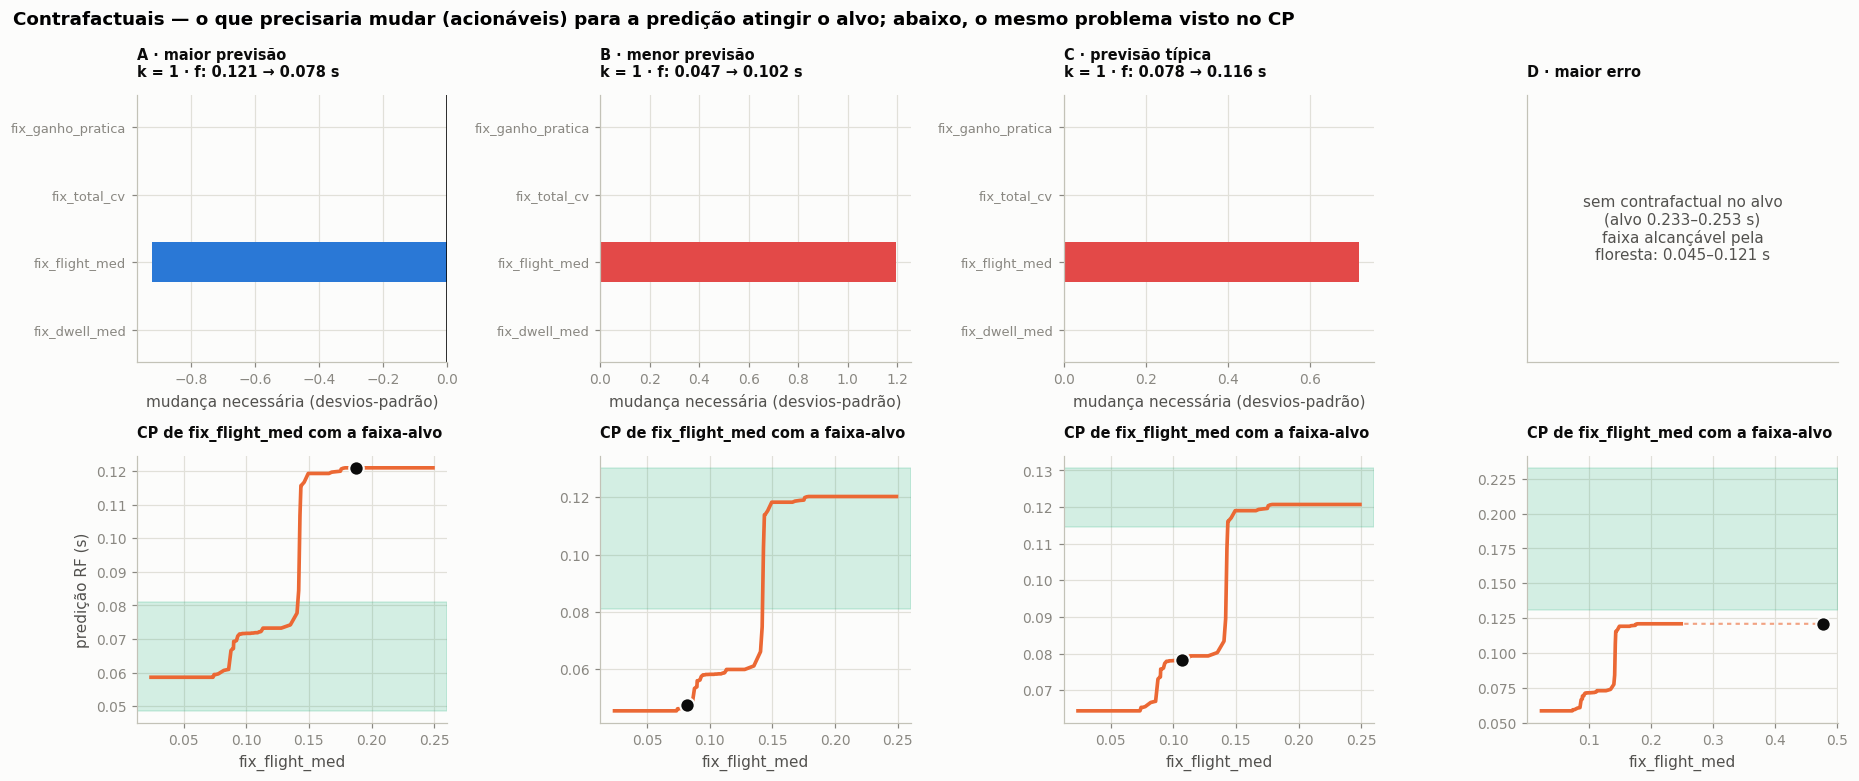

In [38]:
# ══ C34 · Vizinhos contrafactuais reais + figura ═════════════════════════
def vizinhos_contrafactuais(k, n=3):
    lo, hi = ALVOS[k]
    pid, x = OBS[k], X_OBS[k]
    pred_all = pd.Series(f_rf(D_all), index=D_all.index)
    cand = pred_all[(pred_all >= lo) & (pred_all <= hi)].drop(index=pid, errors="ignore")
    if cand.empty:
        return pd.DataFrame()
    dz = np.sqrt(((padronizar(D_all.loc[cand.index]) - padronizar(x.to_frame().T)) ** 2).sum(axis=1))
    sel = pd.Series(dz, index=cand.index).nsmallest(n)
    out = D_all.loc[sel.index, ACIONAVEIS].copy()
    out.insert(0, "distância (z)", sel.values)
    out.insert(1, "pred. RF (s)", cand[sel.index].values)
    out.insert(2, "observado (s)", y_all[sel.index].values)
    for c in IMUTAVEIS:
        out[c] = D_all.loc[sel.index, c]
    return out


for k in OBS:
    print(f"── {ROTULO[k]} · {OBS[k]} — vizinhos reais com predição no alvo ──")
    v = vizinhos_contrafactuais(k)
    if len(v) == 0:
        print("   nenhum participante tem predição no alvo.\n")
    else:
        print("   atributos da própria observação:", {c: round(float(X_OBS[k][c]), 4) for c in ACIONAVEIS})
        display(v.round(4))

fig, axes = plt.subplots(2, 4, figsize=(17, 7.2))
for col, (k, x) in enumerate(X_OBS.items()):
    ax = axes[0, col]
    d = CF[k]
    pl = d[d["tipo"] == "plausível"]
    if len(pl):
        r = pl.iloc[0]                                        # menor k plausível
        dz = pd.Series(r["Δz"]).reindex(ACIONAVEIS).fillna(0.0)
        ax.barh(range(len(dz)), dz.values, color=[COR["pos"] if v > 0 else COR["neg"] for v in dz.values], height=0.6)
        ax.axvline(0, color=COR["tinta"], linewidth=1.1)
        ax.set_yticks(range(len(dz))); ax.set_yticklabels(dz.index, fontsize=8.5)
        ax.set_title(f"{ROTULO[k]}\nk = {int(r['k'])} · f: {float(f_rf(x.to_frame().T)[0]):.3f} → {r['nova predição (s)']:.3f} s", fontsize=9.5)
        ax.set_xlabel("mudança necessária (desvios-padrão)")
    else:
        faixa = faixa_alcancavel(f_rf, x)
        ax.text(0.5, 0.5, f"sem contrafactual no alvo\n(alvo {ALVOS[k][0]:.3f}–{ALVOS[k][1]:.3f} s)\nfaixa alcançável pela\nfloresta: {faixa[0]:.3f}–{faixa[1]:.3f} s",
                ha="center", va="center", transform=ax.transAxes, color=COR["tinta2"])
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(ROTULO[k], fontsize=9.5)
    limpar_eixos(ax)

    ax = axes[1, col]
    v = "fix_flight_med"
    g = grade_cp(v, x_obs=x[v])
    y_cp, Xp = perfil_cp(f_rf, x, v, g)
    sup = dist_ao_treino(Xp) <= LIM_SUPORTE
    ax.plot(g, y_cp, color=COR["s2"], linewidth=1.4, linestyle=(0, (2, 2)), alpha=0.6)
    ax.plot(g, np.where(sup, y_cp, np.nan), color=COR["s2"], linewidth=2.4)
    lo, hi = ALVOS[k]
    ax.axhspan(max(lo, y_cp.min() - 0.01), min(hi, y_cp.max() + 0.01), color=COR["s3"], alpha=0.18, label="alvo")
    ax.scatter([x[v]], [float(f_rf(x.to_frame().T)[0])], s=90, color=COR["tinta"], zorder=5, edgecolor=COR["superficie"], linewidth=1.4)
    ax.set_xlabel(v); ax.set_ylabel("predição RF (s)" if col == 0 else "")
    ax.set_title("CP de fix_flight_med com a faixa-alvo", fontsize=9.5)
    limpar_eixos(ax)
fig.suptitle("Contrafactuais — o que precisaria mudar (acionáveis) para a predição atingir o alvo; abaixo, o mesmo problema visto no CP",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig18_contrafactuais.png")
plt.show()

pd.concat({k: d.drop(columns=["Δz"]) for k, d in CF.items()}, names=["obs", "i"]).to_csv(DIR_SAIDA / "tabela_contrafactuais.csv")

### Interpretação — contrafactuais

**1. Uma só variável basta, e é sempre a mesma.** Para A, B e C a solução **mais esparsa e plausível tem $k=1$**: mexer em `fix_flight_med`.

| Obs. | Contraste | Mudança mínima (acionável) | Custo | Nova predição |
|---|---|---|---|---|
| **A** | alta → típica (≤ 0,081 s) | `flight` 0,188 → **0,141** s | 0,92 DP | 0,078 s |
| **B** | baixa → típica (≥ 0,081 s) | `flight` 0,082 → **0,143** s | 1,20 DP | 0,102 s |
| **C** | típica → alta (≥ 0,115 s) | `flight` 0,107 → **0,144** s | 0,72 DP | 0,116 s |
| **D** | prever o observado (0,243 s) | **nenhum** | — | máximo alcançável ≈ 0,12 s |

Acrescentar `dwell`, `cv` ou `ganho` **não barateia** a solução (custos 1,03–1,27 DP em A contra 0,92 com `flight` sozinho). É a mesma
hierarquia que o SHAP deu — mas agora numa linguagem **acionável**: *"se o `flight` da senha estivesse ≈ 0,14 s, a previsão seria outra"*.

**2. O contrafactual é o CP com meta — e cai exatamente no degrau.** As três soluções ficam em **0,141–0,144 s**, o ponto onde a curva
CP salta (figura, linha de baixo). O método devolve, por construção, a mudança **mínima**: **atravessar o degrau** e parar. Duas
consequências: (i) a explicação é **frágil** — 0,01 s de diferença em `flight` muda a predição em ≈ 0,04 s; (ii) não é uma
**recomendação robusta**: a solução "ideal" é a que está **encostada** na fronteira do modelo.

**3. Plausibilidade.** Todas as soluções têm distância ao treino de 1,0–1,2 (limite 2,03): estão **dentro** da região com dados.
Os **vizinhos reais** reforçam: para B existem três participantes reais com `flight` entre 0,147 e 0,152 s e predição 0,115–0,119 s
(observado 0,095–0,135 s); para A, o participante p100 (`flight` 0,140 s, predição 0,078 s, observado 0,060 s).

**4. A observação D é o achado mais importante da seção.** **Não existe contrafactual**: o alvo (0,243 ± 0,011 s) está **fora do que
a floresta consegue prever** — mexendo em todas as acionáveis, o máximo é ≈ 0,12 s — e **nenhum participante real** tem predição no alvo.
A resposta do método à pergunta *"o que o modelo precisaria ver para prever o que aconteceu?"* é **"nada"**: o modelo é **incapaz** de
produzir o valor. Isso é uma **limitação do modelo** (a floresta não extrapola), não uma característica do participante — o modelo
linear, que extrapola, prevê 0,288 s para o mesmo indivíduo.

> **Limitações e ética.** (i) o contrafactual descreve o **modelo**: "reduzir o *flight* de um digitador" **não** é uma intervenção cuja eficácia
> o dataset permita afirmar; (ii) não é único — outra função de custo (por exemplo, por percentil) escolheria outro ponto; (iii) em
> nenhuma hipótese isso é um "tratamento" ou "diagnóstico": é a **sensibilidade de uma função** a uma medida de digitação.

---
# §7 · Etapa 7 — Comparação entre os métodos

**Objetivo da seção:** discutir **semelhanças, diferenças, vantagens e limitações** das explicações — com **evidência**,
não só com argumento. Três frentes:

1. **Mesma observação, quatro explicações** (C35): CP, LIME, SHAP e a explicação exata do modelo linear (ATV2) lado a lado, **na mesma unidade (s)**;
2. **Concordância quantitativa** em todos os 29 participantes do hold-out (C36): *o quanto LIME e SHAP concordam — comparado ao quanto o LIME concorda consigo mesmo* (o "teto" de concordância imposto pela aleatoriedade);
3. **Onde discordam e por quê** (C37), **custo** e **propriedades** (C38) e **coerência com a ATV2** (C39).

> **Cuidado conceitual com a comparação.** Os métodos **não respondem à mesma pergunta**:
> o **CP** mede *o que acontece se eu trocar uma variável por um valor de referência* (uma variável por vez);
> o **LIME** mede *a inclinação do melhor modelo linear local* (vizinhança + discretização);
> o **SHAP** mede *a contribuição média sobre todas as ordens, em relação ao baseline do treino*.
> Concordância total **não** é esperada — a pergunta é **quando e por que divergem**.

### C35 · Mesma observação, quatro explicações

**Objetivo:** para cada observação, comparar as contribuições por variável. Todas estão em **segundos de predição**:
**CP** = $\hat f(x)-\hat f(x_{j:=\mathrm{ref}})$ (C13); **LIME** = pesos do substituto com $K=7$ (todas as variáveis, sem esparsidade);
**SHAP** = $\phi_j$ (C28); **Linear (ATV2)** = $\beta_jz_j$ (SHAP do modelo linear, C31) — a explicação exata de um
modelo **diferente**, que serve de âncora.

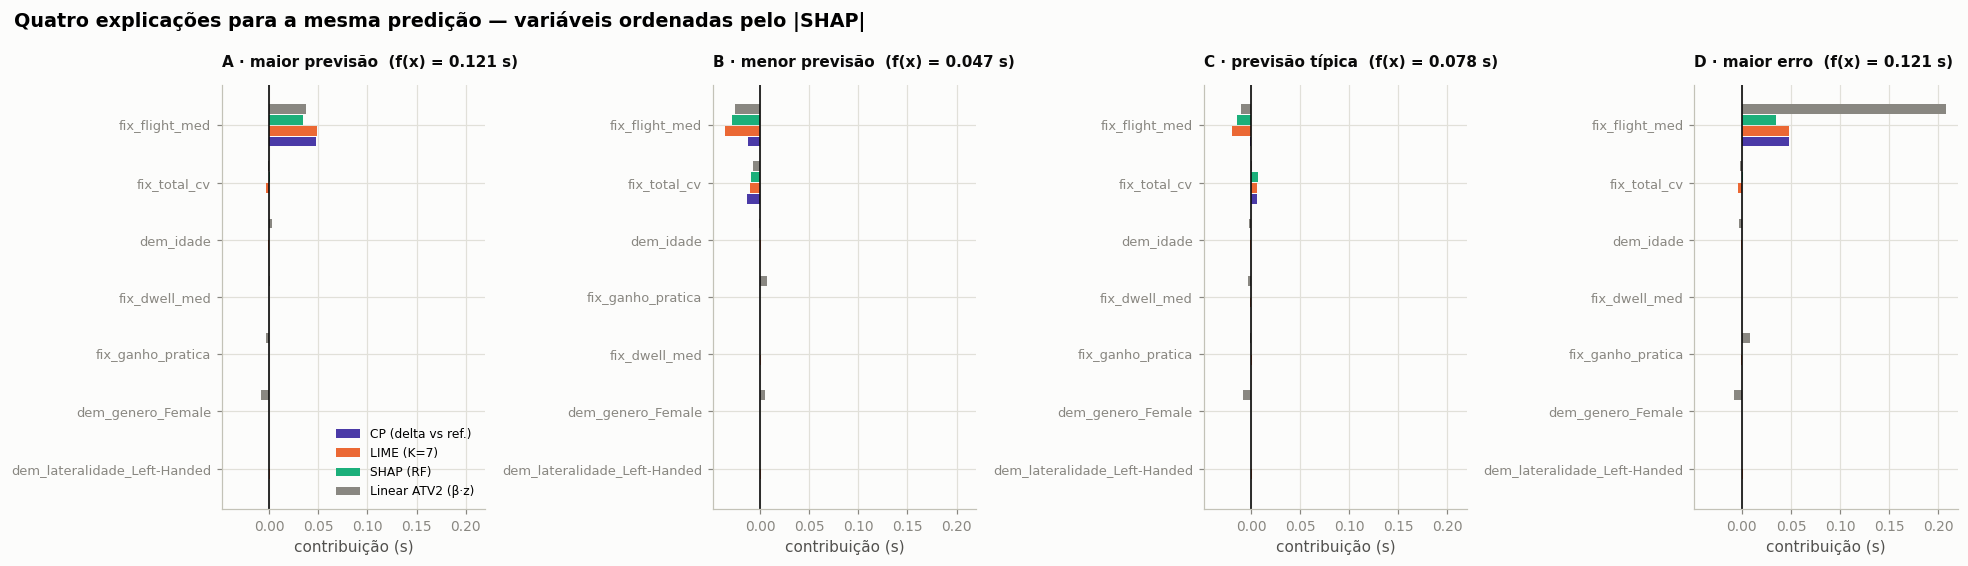


A · maior previsão — contribuições (s):


,CP (delta vs ref.),LIME (K=7),SHAP (RF),Linear ATV2 (β·z)
fix_dwell_med,0.0000,0.0002,0.0000,0.0007
fix_flight_med,0.0477,0.0484,0.0347,0.0370
fix_total_cv,0.0000,-0.0038,0.0011,-0.0017
fix_ganho_pratica,0.0001,0.0001,0.0000,-0.0029
dem_idade,0.0000,-0.0015,0.0001,0.0031
dem_genero_Female,-0.0000,-0.0002,-0.0000,-0.0082
dem_lateralidade_Left-Handed,0.0000,0.0009,0.0000,0.0002



B · menor previsão — contribuições (s):


,CP (delta vs ref.),LIME (K=7),SHAP (RF),Linear ATV2 (β·z)
fix_dwell_med,0.0000,0.0007,-0.0000,0.0004
fix_flight_med,-0.0125,-0.0360,-0.0287,-0.0251
fix_total_cv,-0.0135,-0.0102,-0.0088,-0.0072
fix_ganho_pratica,0.0002,0.0001,0.0001,0.0067
dem_idade,0.0000,0.0012,-0.0002,-0.0014
dem_genero_Female,0.0000,-0.0005,0.0000,0.0052
dem_lateralidade_Left-Handed,0.0000,0.0010,0.0000,0.0002



C · previsão típica — contribuições (s):


,CP (delta vs ref.),LIME (K=7),SHAP (RF),Linear ATV2 (β·z)
fix_dwell_med,-0.0001,-0.0006,-0.0001,-0.0032
fix_flight_med,-0.0012,-0.0194,-0.0139,-0.0104
fix_total_cv,0.0065,0.0059,0.0073,0.0006
fix_ganho_pratica,0.0000,0.0007,-0.0001,-0.0005
dem_idade,0.0000,-0.0007,-0.0002,-0.0019
dem_genero_Female,0.0000,-0.0002,-0.0000,-0.0082
dem_lateralidade_Left-Handed,-0.0000,0.0010,0.0000,0.0002



D · maior erro — contribuições (s):


,CP (delta vs ref.),LIME (K=7),SHAP (RF),Linear ATV2 (β·z)
fix_dwell_med,-0.0000,0.0002,-0.0000,0.0000
fix_flight_med,0.0480,0.0484,0.0348,0.2079
fix_total_cv,-0.0000,-0.0037,0.0011,-0.0016
fix_ganho_pratica,-0.0000,-0.0007,0.0000,0.0079
dem_idade,0.0000,-0.0005,-0.0001,-0.0028
dem_genero_Female,-0.0000,-0.0002,-0.0000,-0.0082
dem_lateralidade_Left-Handed,-0.0000,0.0010,0.0000,0.0002


In [39]:
# ══ C35 · Quatro explicações lado a lado ═════════════════════════════════
LIME7 = {k: explicar_lime(x, SEMENTE, K=len(COLS)) for k, x in X_OBS.items()}
METODOS = {"CP (delta vs ref.)": COR["s7"], "LIME (K=7)": COR["s2"], "SHAP (RF)": COR["s3"], "Linear ATV2 (β·z)": COR["suave"]}

fig, axes = plt.subplots(1, 4, figsize=(18, 5.2), sharex=True)
vals_obs = {}
for ax, (k, pid) in zip(axes, OBS.items()):
    tab = pd.DataFrame({"CP (delta vs ref.)": DELTA_CP[k],
                        "LIME (K=7)": pd.Series({COLS[i]: w for i, w in LIME7[k]["pesos"].items()}).reindex(COLS),
                        "SHAP (RF)": SV.loc[pid],
                        "Linear ATV2 (β·z)": SV_LIN.loc[pid]}).loc[COLS]
    vals_obs[k] = tab
    ordem = list(tab["SHAP (RF)"].abs().sort_values().index)
    for j, c in enumerate(ordem):
        for m, (nome, cor) in enumerate(METODOS.items()):
            ax.barh(j + (m - 1.5) * 0.19, tab.loc[c, nome], height=0.17, color=cor, label=nome if (j == 0) else None)
    ax.axvline(0, color=COR["tinta"], linewidth=1.1)
    ax.set_yticks(range(len(ordem))); ax.set_yticklabels(ordem, fontsize=8.5)
    ax.set_title(f"{ROTULO[k]}  (f(x) = {float(f_rf(X_OBS[k].to_frame().T)[0]):.3f} s)", fontsize=10)
    ax.set_xlabel("contribuição (s)")
    limpar_eixos(ax)
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Quatro explicações para a mesma predição — variáveis ordenadas pelo |SHAP|", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig19_comparacao_observacoes.png")
plt.show()
for k in OBS:
    print(f"\n{ROTULO[k]} — contribuições (s):")
    display(vals_obs[k].round(4))

### C36 · Concordância em **todos os 29** participantes do hold-out

**Objetivo:** medir a concordância de forma sistemática. Para cada participante do hold-out calculamos as quatro
explicações (LIME **duas vezes**, com sementes diferentes) e comparamos **por pares**:

| Medida | O que diz |
|---|---|
| **Spearman de $|\text{atribuição}|$** | os métodos **ordenam** as variáveis pela importância da mesma forma? |
| **Top-1 coincide** | apontam a **mesma** variável principal? |
| **Sinais concordantes** | entre as variáveis **relevantes** ($|\phi_j|\ge10\%$ do maior $|\phi|$ do SHAP), o sinal é o mesmo? |
| **Correlação (signed) global** | sobre as 29×7 atribuições, qual a correlação linear? |

**O "teto" da concordância:** o par **LIME(semente 1) × LIME(semente 2)** mede quanto o LIME concorda **consigo
mesmo**. Se LIME×SHAP estiver próximo desse teto, a discrepância é só **ruído de amostragem**; se estiver muito abaixo,
há **diferença real** de pergunta.

Explicações calculadas para 29 participantes em 11 s


,Spearman |.| (média),Spearman |.| (mediana),cosseno (média),% top-1 igual,% sinais concordantes,correlação global (signed)
par,,,,,,
LIME × SHAP,0.5430,0.5000,0.6090,89.6550,86.2070,0.8770
CP × SHAP,0.6460,0.6430,0.7440,55.1720,86.2070,0.9000
LIME × CP,0.4830,0.5560,0.8270,58.6210,96.5520,0.8480
Linear(ATV2) × SHAP(RF),0.4620,0.4640,0.7150,75.8620,86.2070,0.6990
LIME(s1) × LIME(s2) [teto],0.6710,0.6430,0.9800,100.0000,100.0000,0.9960


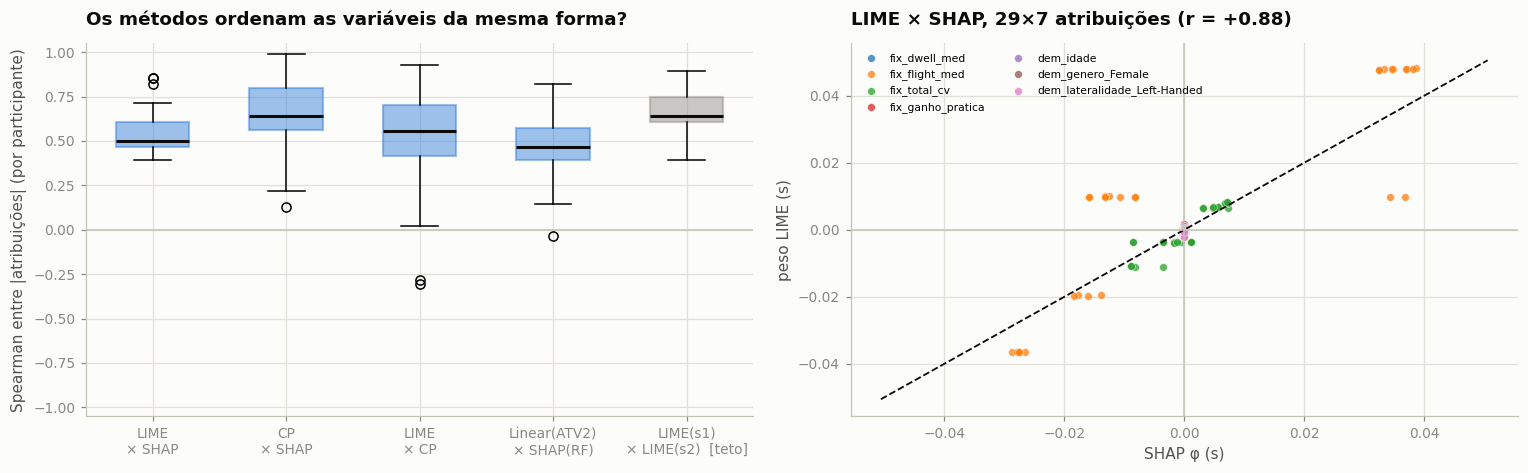

O que o LIME atribui às variáveis que a floresta IGNORA (dummies; φ_SHAP ≡ 0):
  média |peso LIME| nas dummies = 0.0009 s   vs. nas contínuas = 0.0074 s


In [40]:
# ══ C36 · Concordância entre métodos no hold-out ═════════════════════════
te_ids = list(D_te.index)


def delta_cp_matriz(X):
    # delta_j = f(x) - f(x com a variável j no valor de referência), para TODAS as linhas de X, em lote.
    base = f_rf(X)
    out = {}
    for v in COLS:
        Xr = X[COLS].copy()
        Xr[v] = REF[v]
        out[v] = base - f_rf(Xr)
    return pd.DataFrame(out, index=X.index)


def lime_matriz(X, semente):
    return pd.DataFrame([{COLS[i]: w for i, w in explicar_lime(X.loc[pid], semente, K=len(COLS))["pesos"].items()}
                         for pid in X.index], index=X.index).reindex(columns=COLS).fillna(0.0)


t0 = time.time()
A_CP = delta_cp_matriz(D_te)
A_LIME1, A_LIME2 = lime_matriz(D_te, 1), lime_matriz(D_te, 2)
A_SHAP, A_LIN = SV.loc[te_ids], SV_LIN.loc[te_ids]
print(f"Explicações calculadas para {len(te_ids)} participantes em {time.time()-t0:.0f} s")

PARES = {"LIME × SHAP": (A_LIME1, A_SHAP), "CP × SHAP": (A_CP, A_SHAP), "LIME × CP": (A_LIME1, A_CP),
         "Linear(ATV2) × SHAP(RF)": (A_LIN, A_SHAP), "LIME(s1) × LIME(s2)  [teto]": (A_LIME1, A_LIME2)}


def concordancia(a, b, ref_relevante):
    linhas = []
    for pid in a.index:
        va, vb, vr = a.loc[pid].to_numpy(), b.loc[pid].to_numpy(), ref_relevante.loc[pid].to_numpy()
        rel = np.abs(vr) >= 0.10 * np.abs(vr).max()
        den = np.linalg.norm(va) * np.linalg.norm(vb)
        linhas.append({"spearman |.|": stats.spearmanr(np.abs(va), np.abs(vb))[0],
                       "cosseno (signed)": float(va @ vb / den) if den > 0 else np.nan,
                       "top-1 igual": float(np.argmax(np.abs(va)) == np.argmax(np.abs(vb))),
                       "sinais concordantes (relevantes)": float(np.mean(np.sign(va[rel]) == np.sign(vb[rel]))) if rel.any() else np.nan})
    return pd.DataFrame(linhas, index=a.index)


linhas, CONC = [], {}
for nome, (a, b) in PARES.items():
    c = concordancia(a, b, A_SHAP)
    CONC[nome] = c
    linhas.append({"par": nome, "Spearman |.| (média)": c["spearman |.|"].mean(), "Spearman |.| (mediana)": c["spearman |.|"].median(),
                   "cosseno (média)": c["cosseno (signed)"].mean(),
                   "% top-1 igual": 100 * c["top-1 igual"].mean(),
                   "% sinais concordantes": 100 * c["sinais concordantes (relevantes)"].mean(),
                   "correlação global (signed)": np.corrcoef(a.to_numpy().ravel(), b.to_numpy().ravel())[0, 1]})
tab_conc = pd.DataFrame(linhas).set_index("par")
display(tab_conc.round(3))
tab_conc.to_csv(DIR_SAIDA / "tabela_concordancia_metodos.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
dados_box = [CONC[n]["spearman |.|"].dropna().to_numpy() for n in PARES]
bp = boxplot_compat(ax, dados_box, [n.replace(" × ", "\n× ") for n in PARES], patch_artist=True, showfliers=True, widths=0.55)
for caixa, nome in zip(bp["boxes"], PARES):
    cor = COR["suave"] if "teto" in nome else COR["s1"]
    caixa.set(facecolor=cor, alpha=0.45, edgecolor=cor, linewidth=1.4)
for med in bp["medians"]:
    med.set(color=COR["tinta"], linewidth=2)
ax.set_ylabel("Spearman entre |atribuições| (por participante)"); ax.set_ylim(-1.05, 1.05); ax.axhline(0, color=COR["eixo"], linewidth=1)
ax.set_title("Os métodos ordenam as variáveis da mesma forma?")
limpar_eixos(ax)

ax = axes[1]
a, b = A_LIME1.to_numpy().ravel(), A_SHAP.to_numpy().ravel()
cores_pt = np.tile(np.arange(len(COLS)), len(te_ids))
for j, c in enumerate(COLS):
    m = cores_pt == j
    ax.scatter(b[m], a[m], s=26, alpha=0.75, label=c, edgecolor=COR["superficie"], linewidth=0.4)
lim = max(np.abs(a).max(), np.abs(b).max()) * 1.05
ax.plot([-lim, lim], [-lim, lim], color=COR["tinta"], linestyle="--", linewidth=1.2)
ax.axhline(0, color=COR["eixo"], linewidth=1); ax.axvline(0, color=COR["eixo"], linewidth=1)
ax.set_xlabel("SHAP φ (s)"); ax.set_ylabel("peso LIME (s)")
ax.set_title(f"LIME × SHAP, 29×7 atribuições (r = {np.corrcoef(a, b)[0, 1]:+.2f})")
ax.legend(fontsize=7, ncol=2, loc="upper left")
limpar_eixos(ax)
plt.tight_layout()
plt.savefig(DIR_SAIDA / "fig20_concordancia.png")
plt.show()

print("O que o LIME atribui às variáveis que a floresta IGNORA (dummies; φ_SHAP ≡ 0):")
print(f"  média |peso LIME| nas dummies = {A_LIME1[COLS_DUM].abs().to_numpy().mean():.4f} s   "
      f"vs. nas contínuas = {A_LIME1[COLS_CONT].abs().to_numpy().mean():.4f} s")

### C37 · Onde as explicações **discordam** — e por quê

**Objetivo:** olhar o pior caso de concordância em vez de só a média. Selecionamos o participante do hold-out com
**menor Spearman LIME × SHAP** e investigamos três suspeitos, todos vindos dos slides:

1. **perturbações sem suporte** (SLIDE 06, p. 28; SLIDE 05, p. 14) — o LIME/CP/SHAP avaliam o modelo onde não há dados;
2. **interação** (SLIDE 05, pp. 20–21) — LIME aproxima por **uma reta** na vizinhança, SHAP **promedia** sobre ordens;
3. **discretização** (SLIDE 06, p. 37) — o LIME vê **bins**, o SHAP vê valores.

In [41]:
# ══ C37 · Pior caso de concordância ══════════════════════════════════════
pior = CONC["LIME × SHAP"]["spearman |.|"].idxmin()
xp = D_all.loc[pior, COLS].astype(float)
print(f"Participante com MENOR concordância LIME × SHAP no hold-out: {pior}   "
      f"(Spearman = {CONC['LIME × SHAP'].loc[pior, 'spearman |.|']:+.2f})   observado {y_all[pior]:.3f} s · previsto {float(f_rf(xp.to_frame().T)[0]):.3f} s")
display(pd.DataFrame({"valor": xp, "CP": A_CP.loc[pior], "LIME (s1)": A_LIME1.loc[pior], "LIME (s2)": A_LIME2.loc[pior],
                      "SHAP": A_SHAP.loc[pior], "Linear ATV2": A_LIN.loc[pior]}).round(4))

Xp_all = D_te.loc[[pior]]
print(f"\nSuspeito 1 — suporte: distância ao treino do próprio indivíduo = {float(dist_ao_treino(Xp_all)[0]):.2f}  (limite p95 = {LIM_SUPORTE:.2f})")
sup_te = pd.Series(dist_ao_treino(D_te), index=D_te.index)
print(f"            participantes do hold-out acima do limite: {(sup_te > LIM_SUPORTE).sum()} de {len(sup_te)}")
rel = pd.Series({"média": CONC["LIME × SHAP"]["spearman |.|"].mean(), "mediana": CONC["LIME × SHAP"]["spearman |.|"].median()})
print(f"\nConcordância LIME × SHAP: média {rel['média']:+.2f} · mediana {rel['mediana']:+.2f} | teto (LIME×LIME): "
      f"{CONC['LIME(s1) × LIME(s2)  [teto]']['spearman |.|'].mean():+.2f}")

corr_sup = stats.spearmanr(sup_te.reindex(te_ids), CONC["LIME × SHAP"]["spearman |.|"].reindex(te_ids))
print(f"\nSuspeito 1 (geral) — a concordância LIME×SHAP cai para quem está longe dos dados? "
      f"Spearman(distância ao treino, concordância) = {corr_sup[0]:+.2f}  (p = {corr_sup[1]:.2f})")

H_rf = tab_U[tab_U["modelo"] == "Random Forest"].set_index("variável")["H (s)"]
print("\nSuspeito 2 — interação: H_j (parte não paralela do ICE, s) das variáveis com maior desacordo neste participante:")
desacordo = (A_LIME1.loc[pior].abs() - A_SHAP.loc[pior].abs()).abs().sort_values(ascending=False)
for c in desacordo.index[:3]:
    h = H_rf.get(c, np.nan)
    print(f"   {c:<30s} |LIME|−|SHAP| = {desacordo[c]:.4f} s   H_j = " + (f"{h:.4f} s" if np.isfinite(h) else "n/d (dummy)"))

Participante com MENOR concordância LIME × SHAP no hold-out: p072   (Spearman = +0.39)   observado 0.140 s · previsto 0.084 s


,valor,CP,LIME (s1),LIME (s2),SHAP,Linear ATV2
fix_dwell_med,0.1170,-0.0001,0.0013,0.0008,-0.0001,-0.0018
fix_flight_med,0.1370,0.0040,0.0099,0.0088,-0.0082,0.0073
fix_total_cv,0.5369,0.0058,0.0078,0.0074,0.0068,0.0042
fix_ganho_pratica,0.4038,0.0000,0.0014,-0.0000,-0.0000,-0.0047
dem_idade,45.0000,0.0005,0.0000,0.0011,0.0002,0.0095
dem_genero_Female,0.0000,0.0000,-0.0005,0.0015,0.0000,0.0052
dem_lateralidade_Left-Handed,0.0000,-0.0000,-0.0021,0.0011,0.0000,0.0002



Suspeito 1 — suporte: distância ao treino do próprio indivíduo = 2.47  (limite p95 = 2.03)
            participantes do hold-out acima do limite: 4 de 29

Concordância LIME × SHAP: média +0.54 · mediana +0.50 | teto (LIME×LIME): +0.67

Suspeito 1 (geral) — a concordância LIME×SHAP cai para quem está longe dos dados? Spearman(distância ao treino, concordância) = -0.05  (p = 0.82)

Suspeito 2 — interação: H_j (parte não paralela do ICE, s) das variáveis com maior desacordo neste participante:
   dem_lateralidade_Left-Handed   |LIME|−|SHAP| = 0.0021 s   H_j = n/d (dummy)
   fix_flight_med                 |LIME|−|SHAP| = 0.0018 s   H_j = 0.0039 s
   fix_ganho_pratica              |LIME|−|SHAP| = 0.0013 s   H_j = 0.0001 s


### C38 · Custo, determinismo e propriedades — **medidos**

**Objetivo:** completar a comparação com o que é **mensurável**: o tempo para explicar **uma** observação e a
**variabilidade** do resultado entre execuções. As demais propriedades (escopo, o que varia, garantias, limitações)
vêm da teoria dos SLIDES 05/06 e de Lundberg & Lee (2017).

In [42]:
# ══ C38 · Custo e variabilidade ══════════════════════════════════════════
def cronometrar(fn, n=3):
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))


xA = X_OBS["A"]
t_cp = cronometrar(lambda: [perfil_cp(f_rf, xA, v, grade_cp(v, x_obs=xA[v])) for v in COLS_CONT])
t_ice = cronometrar(lambda: [ice_matriz(f_rf, D_all, v, GRADE_ICE[v]) for v in COLS_CONT], n=1)
t_lime = cronometrar(lambda: explicar_lime(xA, SEMENTE))
t_tree = cronometrar(lambda: expl_tree.shap_values(xA.to_frame().T[COLS], check_additivity=False))
t_exato = cronometrar(lambda: shapley_exato(f_rf, xA, D_tr), n=1)
t_kern = cronometrar(lambda: expl_kern.shap_values(xA.to_numpy(float).reshape(1, -1), nsamples=2 ** len(COLS), silent=True), n=1)
t_cf = cronometrar(lambda: buscar_contrafactuais(f_rf, xA, ALVOS["A"]), n=1)

# variabilidade entre execuções (mesma observação, 30 sementes para LIME; SHAP/CP/exato são determinísticos)
sd_lime = np.mean([np.std([r["pesos"].get(i, 0.0) for r in EST["A"]]) for i in range(len(COLS))])

custo = pd.DataFrame([
    ["CP (5 contínuas, 101 pts)", t_cp, "uma observação", "determinístico", 0.0],
    ["ICE (96 curvas × 5 variáveis)", t_ice, "todo o conjunto", "determinístico", 0.0],
    ["LIME (m=5000, K=5)", t_lime, "uma observação", "ALEATÓRIO (semente)", sd_lime],
    ["SHAP — TreeExplainer interventional", t_tree, "uma observação (e global ao agregar)", "determinístico", 0.0],
    ["SHAP — enumeração exata (2⁷)", t_exato, "uma observação", "determinístico", 0.0],
    ["SHAP — KernelExplainer", t_kern, "uma observação", "determinístico (p pequeno)", 0.0],
    ["Contrafactuais (busca exaustiva)", t_cf, "uma observação + alvo", "determinístico", 0.0],
], columns=["método", "tempo p/ 1 obs. (s)", "escopo do resultado", "reprodutibilidade", "dp médio dos pesos entre sementes (s)"])
display(custo.round(4))
custo.to_csv(DIR_SAIDA / "tabela_custo_metodos.csv", index=False)

,método,tempo p/ 1 obs. (s),escopo do resultado,reprodutibilidade,dp médio dos pesos entre sementes (s)
0,"CP (5 contínuas, 101 pts)",0.5617,uma observação,determinístico,0.0000
1,ICE (96 curvas × 5 variáveis),0.8248,todo o conjunto,determinístico,0.0000
2,"LIME (m=5000, K=5)",0.2299,uma observação,ALEATÓRIO (semente),0.0005
3,SHAP — TreeExplainer interventional,0.0021,uma observação (e global ao agregar),determinístico,0.0000
4,SHAP — enumeração exata (2⁷),0.1659,uma observação,determinístico,0.0000
5,SHAP — KernelExplainer,0.2829,uma observação,determinístico (p pequeno),0.0000
6,Contrafactuais (busca exaustiva),2.1444,uma observação + alvo,determinístico,0.0000


### C39 · Coerência com a ATV2 — o modelo caixa-preta e o modelo transparente contam a mesma história?

**Objetivo:** a ATV2 concluiu o que importa **no modelo linear**. A ATV3 explica **outro** modelo. Se os dois
(ajustados aos mesmos dados) apontarem as mesmas variáveis, ganha-se confiança de que o achado é **dos dados**, e
não de um modelo específico; se divergirem, a divergência é informação.

In [43]:
# ══ C39 · Importância global em quatro modelos/explicações ═══════════════
amp_pdp = tab_U[tab_U["modelo"] == "Random Forest"].set_index("variável")["amplitude do PDP (s)"].reindex(COLS)
for c in COLS_DUM:       # dummies: o "PDP" tem só dois pontos (categoria 0 e 1)
    pdp2 = ice_matriz(f_rf, D_all, c, np.array([0.0, 1.0])).mean(axis=0)
    amp_pdp[c] = float(abs(pdp2[1] - pdp2[0]))
imp = pd.DataFrame({
    "SHAP médio |φ| (RF)": SV.abs().mean(),
    "PDP: amplitude (RF)": amp_pdp,
    "LIME médio |peso| (RF, hold-out)": A_LIME1.abs().mean(),
    "|β| padronizado (Linear ATV2)": beta_z.abs().reindex(COLS),
    "importância por impureza (RF)": pd.Series(rf.feature_importances_, index=COLS),
}).loc[COLS]
display(imp.round(4))
rank = imp.round(4).rank(ascending=False, method="min")        # |valores| < 0,00005 s empatam em "zero prático"
display(rank.astype("Int64").style.set_caption("Posição de cada variável (1 = mais importante; valores iguais até a 4ª casa empatam)"))
rho = imp.corr(method="spearman")
display(rho.round(2).style.set_caption("Spearman entre rankings das 7 variáveis"))
print("Variável nº 1 em cada critério:", imp.idxmax().to_dict())

,SHAP médio |φ| (RF),PDP: amplitude (RF),"LIME médio |peso| (RF, hold-out)",|β| padronizado (Linear ATV2),importância por impureza (RF)
fix_dwell_med,0.0001,0.0002,0.0005,0.0016,0.0039
fix_flight_med,0.0249,0.0642,0.0286,0.0300,0.8775
fix_total_cv,0.0053,0.0124,0.0066,0.0059,0.1150
fix_ganho_pratica,0.0000,0.0001,0.0009,0.0048,0.0014
dem_idade,0.0001,0.0003,0.0006,0.0029,0.0021
dem_genero_Female,0.0000,0.0000,0.0003,0.0134,0.0000
dem_lateralidade_Left-Handed,0.0000,0.0000,0.0016,0.0017,0.0000


,SHAP médio |φ| (RF),PDP: amplitude (RF),"LIME médio |peso| (RF, hold-out)",|β| padronizado (Linear ATV2),importância por impureza (RF)
fix_dwell_med,3,4,6,7,3
fix_flight_med,1,1,1,1,1
fix_total_cv,2,2,2,3,2
fix_ganho_pratica,5,5,4,4,5
dem_idade,3,3,5,5,4
dem_genero_Female,5,6,7,2,6
dem_lateralidade_Left-Handed,5,6,3,6,6


,SHAP médio |φ| (RF),PDP: amplitude (RF),"LIME médio |peso| (RF, hold-out)",|β| padronizado (Linear ATV2),importância por impureza (RF)
SHAP médio |φ| (RF),1.000000,1.000000,0.540000,0.430000,0.960000
PDP: amplitude (RF),1.000000,1.000000,0.540000,0.430000,0.960000
"LIME médio |peso| (RF, hold-out)",0.540000,0.540000,1.000000,0.360000,0.500000
|β| padronizado (Linear ATV2),0.430000,0.430000,0.360000,1.000000,0.360000
importância por impureza (RF),0.960000,0.960000,0.500000,0.360000,1.000000


Variável nº 1 em cada critério: {'SHAP médio |φ| (RF)': 'fix_flight_med', 'PDP: amplitude (RF)': 'fix_flight_med', 'LIME médio |peso| (RF, hold-out)': 'fix_flight_med', '|β| padronizado (Linear ATV2)': 'fix_flight_med', 'importância por impureza (RF)': 'fix_flight_med'}


### Quadro comparativo dos métodos

| Eixo | **CP** | **ICE** | **LIME** | **SHAP** | **Contrafactuais** |
|---|---|---|---|---|---|
| **Pergunta que responde** | *e se só esta variável mudasse?* | *isso vale para todos ou há heterogeneidade?* | *qual modelo simples imita $\hat f$ aqui?* | *quanto cada variável contribuiu, em relação à média?* | *o que precisaria ser diferente para o resultado ser outro?* |
| **Escopo** | 1 indivíduo × 1 variável | N indivíduos × 1 variável | 1 indivíduo × todas | 1 indivíduo × todas (e global, agregando) | 1 indivíduo × alvo |
| **O que varia** | **uma** variável (grade) | **uma** variável (grade) | **todas** (sorteio) + kernel | **coalições** de variáveis (*background*) | variáveis acionáveis (grade) |
| **Saída** | curva $z\mapsto\hat f$ | feixe de curvas, PDP, c-ICE, d-ICE | pesos de $g$ nas condições | $\phi_j$ aditivos que somam $\hat f(x)-\mathbb E\hat f$ | ponto(s) $x^{\mathrm{cf}}$ e distância |
| **Garantia formal** | nenhuma (é perturbação) | nenhuma | fidelidade **medida** (não garantida) | **eficiência**, simetria, jogador nulo | atingir o alvo (por construção) |
| **Interações** | invisíveis numa curva; ICE as revela | revela por não paralelismo / cor | absorvidas em **uma** reta local | repartidas entre as variáveis envolvidas | levadas em conta pela busca conjunta |
| **Dependência entre variáveis** | cria combinações irreais | idem | idem (amostragem independente) | idem (*interventional*) | tratada **explicitamente** (suporte) |
| **Reprodutibilidade** | determinístico | determinístico | **depende de semente, $m$, $\sigma$, $K$, bins** | determinístico (dado o *background*) | depende da função de custo |
| **Principal limitação** | combinações improváveis; 1 variável | só 1 variável; sobreposição | instabilidade, vizinhança arbitrária | depende do *background*; custo em p grande | não único; não é intervenção real |

(Os valores medidos que sustentam este quadro estão nas tabelas de C36 a C39 e nas seções §3–§6.)

### Interpretação — comparação

#### Semelhanças — o que **todos** os métodos dizem

- **O mesmo fator principal.** `fix_flight_med` é a variável nº 1 em **todos** os critérios de C39 (SHAP, PDP, LIME, importância por impureza
  e até o |β| do modelo linear), com `fix_total_cv` em 2º em **quatro dos cinco** critérios (no |β| linear ele é 3º, atrás de gênero). Nas quatro observações, CP, LIME e SHAP
  apontam `flight` e concordam no **sinal** (C35).
- **A mesma ordem de grandeza.** Em A: CP +0,048, LIME +0,048, SHAP +0,035, linear +0,037 s. Em B: −0,013 / −0,036 / −0,029 / −0,025 s.
- **Sinais concordantes** entre as variáveis relevantes: **86%** (LIME × SHAP), **90%** (CP × SHAP), **93%** (LIME × CP); correlação linear
  sobre as 29 × 7 atribuições: **r = 0,88** (LIME × SHAP) e **0,90** (CP × SHAP).

#### Diferenças — onde e por quê

1. **Magnitude: depende da referência (CP × SHAP).** O delta CP compara com **um ponto** (a mediana, no meio da escada); o SHAP, com a **média sobre
   os dados**. Em C, `flight` vale **−0,0012 s** no CP (a mediana cai no mesmo patamar) e **−0,0139 s** no SHAP; em A, +0,048 contra +0,035. Resultado:
   o **atributo principal coincide em só 55%** dos 29 participantes (CP × SHAP), contra **90%** (LIME × SHAP).
2. **A cauda: LIME × SHAP discordam além do ruído.** A ordenação das variáveis tem Spearman médio de **0,54** (LIME × SHAP) e o cosseno dos vetores,
   **0,61** — mas o próprio LIME, repetido com outra semente, atinge **0,67** e **0,98**. A diferença entre 0,61 e 0,98 **não é amostragem**: é
   diferença de **pergunta** (reta regional com bins × média sobre coalições).
3. **O LIME "inventa" pequenas atribuições.** Nas dummies (que o SHAP e o CP mostram valerem **exatamente zero**) o LIME atribui peso médio de
   **0,0009 s** — contra 0,0074 s nas contínuas (≈ 12%). A regressão *ridge* com discretização produz ruído que parece sinal; o SHAP, pela propriedade do
   **jogador nulo**, não.
4. **Modelo linear (ATV2) × floresta.** O linear concorda no principal em **76%** dos casos (cosseno 0,72), mas **distribui** atribuição por variáveis que a
   floresta ignora: o |β| de `dem_genero_Female` (0,013 s) é o **2º** maior do linear. Na obs. D o linear atribui **+0,208 s** a `flight` (extrapola) contra +0,035
   do SHAP-floresta: **modelos diferentes, explicações diferentes** — a explicação é do modelo, não do fenômeno.

#### Onde discordam mais: o participante p072 (C37)

Concordância LIME × SHAP de apenas 0,39. Seu `flight` é **0,137 s — logo antes do degrau (0,14 s)**. O **LIME dá +0,0099 s**, o **SHAP −0,0082 s**, o CP +0,004 s: o **sinal se inverte**. O substituto
regional "vê" a subida íngreme logo à frente; o SHAP compara com a média do treino (que inclui quem já está no patamar alto) e, nessa comparação, estar logo abaixo do degrau é estar
**abaixo da média**. **Nenhum dos dois está errado — respondem a perguntas diferentes** na vizinhança de uma **descontinuidade**. Sobre os suspeitos: (i) *suporte* — o indivíduo está fora do
p95 (2,47 > 2,03), mas **no conjunto do hold-out a concordância não cai com a distância ao treino** (Spearman −0,05, p = 0,82), então a distância sozinha não explica; (ii) a *interação/descontinuidade*
($H_\text{flight}=0{,}004$ s) é a hipótese mais consistente com os dados — **não a isolamos formalmente** neste notebook.

#### Vantagens e limitações — resumo com evidências

| Método | Vantagem demonstrada aqui | Limitação demonstrada aqui |
|---|---|---|
| **CP** | mostra o **degrau** e o **teto**; sinaliza onde **não há dados** (obs. D: 100% sem suporte) | **uma variável por vez**; o delta depende da **referência** (top-1 coincide com SHAP em 55%) |
| **ICE** | revelou a **interação** `cv` × `flight` ($\rho=-0{,}69$) que nenhum método de uma observação mostra | só uma variável por vez; $U$ relativo engana (0,71 para efeito nulo) — exige $H$ |
| **LIME** | local, rápido (0,46 s), **dá o mesmo fator principal**; mede a **própria fidelidade** | **R²ᵥ de 0,12 a 0,60**; Jaccard 0,63; kernel padrão com ESS ≈ 98% (quase global); atribui peso ao que o modelo ignora |
| **SHAP** | **eficiência exata**, jogador nulo, determinístico; do local ao global | depende do ***background*** (ponto único muda o top-1 em B e C); exige cuidado com *outliers* |
| **Contrafactuais** | linguagem **acionável** e contrastiva; ligou-se ao CP e achou o limite do modelo (obs. D) | **não único**; fica "encostado" na fronteira (0,141–0,144 s); não é intervenção |

> **Síntese da comparação:** os métodos **concordam no essencial** (quem importa e em que direção) e **divergem no acessório** (a magnitude,
> a cauda, o que ocorre perto de descontinuidades). Quando divergem, **a divergência é informação** sobre o modelo — aqui, sobre os **degraus** da floresta.

---
# §8 · Etapa 8 — Comentários finais

**Objetivo da seção:** sintetizar os resultados e responder *em que situações cada método é mais informativo*.

### C40 · **Protocolo de uso responsável** (SLIDE 06, p. 50) aplicado às nossas explicações

**Objetivo:** o SLIDE 06 propõe sete verificações antes de comunicar uma explicação LIME e a pergunta final
*"avalie a explicação: modelo substituto, fidelidade, estabilidade, plausibilidade"* (p. 29). Aplicamos o protocolo a
**cada observação**, com os números calculados acima — transformando "uma explicação visualmente convincente"
em uma explicação **auditada**. (⚠ = não atendeu ao critério; os critérios são **convenções nossas**, declaradas.)

| # | Item do protocolo | Critério adotado |
|---|---|---|
| 1 | declarar indivíduo, saída e modelo | sempre (cabeçalho do relatório) |
| 2 | registrar semente, $m$ e $K$ | sempre ($\text{semente}=42$, $m=5000$, $K=5$) |
| 3 | plausibilidade das amostras | $\le 20\%$ do **peso** do kernel em perturbações sem suporte |
| 4 | fidelidade local | $R^2_w\ge0{,}70$ (✓) · entre 0,40 e 0,70 (◐) · abaixo (⚠) |
| 5 | estabilidade | Jaccard médio entre 30 sementes $\ge0{,}70$ **e** atributo top-1 igual em $\ge80\%$ |
| 6 | sensibilidade a vizinhança/discretização | atributo top-1 igual para todos os $\sigma$ testados |
| 7 | método complementar | top-1 do LIME = top-1 do SHAP |

In [44]:
# ══ C40 · Protocolo de uso responsável do LIME ═══════════════════════════
linhas = []
for k, pid in OBS.items():
    r = REF_LIME[k]
    top_lime = COLS[max(r["pesos"], key=lambda i: abs(r["pesos"][i]))]
    top_shap = SV.loc[pid].abs().idxmax()
    tops_sigma = tab_k[tab_k["obs"] == k]["atributo top-1"].nunique()
    marca = lambda ok: "✓" if ok else "⚠"
    linhas.append({
        "obs": k, "participante": pid,
        "3 · % do peso sem suporte": f"{tab_pl.loc[k, '% do PESO do kernel em perturbações sem suporte']:.0f}%  {marca(tab_pl.loc[k, '% do PESO do kernel em perturbações sem suporte'] <= 20)}",
        "4 · R² local": f"{r['r2']:.2f}  " + ("✓" if r['r2'] >= 0.70 else "◐" if r['r2'] >= 0.40 else "⚠"),
        "5 · Jaccard / top-1": f"{resumo_est.loc[k, 'Jaccard médio']:.2f} / {resumo_est.loc[k, '% execuções com esse top-1']:.0f}%  "
                              f"{marca(resumo_est.loc[k, 'Jaccard médio'] >= 0.70 and resumo_est.loc[k, '% execuções com esse top-1'] >= 80)}",
        "6 · top-1 por σ": f"{tops_sigma} distinto(s)  {marca(tops_sigma == 1)}",
        "7 · top-1 LIME vs SHAP": f"{top_lime} vs {top_shap}  {marca(top_lime == top_shap)}"})
protocolo = pd.DataFrame(linhas).set_index("obs")
display(protocolo)
protocolo.to_csv(DIR_SAIDA / "tabela_protocolo_lime.csv")

,participante,3 · % do peso sem suporte,4 · R² local,5 · Jaccard / top-1,6 · top-1 por σ,7 · top-1 LIME vs SHAP
obs,,,,,,
A,p016,11% ✓,0.60 ◐,0.63 / 100% ⚠,1 distinto(s) ✓,fix_flight_med vs fix_flight_med ✓
B,p092,10% ✓,0.38 ⚠,0.64 / 100% ⚠,1 distinto(s) ✓,fix_flight_med vs fix_flight_med ✓
C,p031,10% ✓,0.12 ⚠,0.63 / 100% ⚠,1 distinto(s) ✓,fix_flight_med vs fix_flight_med ✓
D,p041,10% ✓,0.60 ◐,0.63 / 100% ⚠,1 distinto(s) ✓,fix_flight_med vs fix_flight_med ✓


### C41 · Síntese numérica para o relatório e o vídeo

**Objetivo:** imprimir, num único bloco, todos os números que precisam entrar no PDF (≤ 10 páginas) e no vídeo
(≤ 5 min) — evitando garimpar célula a célula na véspera da entrega.

In [45]:
# ══ C41 · Síntese dos resultados ═════════════════════════════════════════
print("=" * 78)
print("SÍNTESE — ATV3 · KeyRecs · Métodos de explicação local")
print("=" * 78)
print("\nDADOS E MODELO")
print(f"  Participantes: {len(dados)} (treino {len(D_tr)} / teste {len(D_te)})   idêntico à ATV2: sim")
print(f"  Resposta: hesitacao_livre   Explicativas ({len(COLS)}): {', '.join(COLS)}")
print(f"  Random Forest {HP_RF}: RMSE CV = {desempenho.loc['Random Forest','RMSE']:.4f} s  R² = {desempenho.loc['Random Forest','R2']:+.3f}"
      f"  (linear ATV2: {desempenho.loc['Linear (ATV2)','RMSE']:.4f} s / {desempenho.loc['Linear (ATV2)','R2']:+.3f};  baseline {desempenho.loc['Baseline (mediana)','RMSE']:.4f} s)")
print("\nOBSERVAÇÕES")
for k, pid in OBS.items():
    print(f"  {ROTULO[k]:<22s} {pid}: observado {y_all[pid]:.3f} s · previsto RF {float(f_rf(X_OBS[k].to_frame().T)[0]):.3f} s")
print("\nCP / ICE")
print(f"  grade sem suporte (obs. D, extremo): {tab_sup['D'].max():.0f}% em alguma variável;   validação ICE × scikit-learn: erro {dif_max:.1e}")
print(f"  U_j (floresta): " + ", ".join(f"{v}={tab_U[(tab_U['modelo']=='Random Forest')&(tab_U['variável']==v)]['U (fração)'].iloc[0]:.2f}" for v in COLS_CONT))
print("\nLIME")
print(f"  R² local (ref.): " + ", ".join(f"{k}={r['r2']:.2f}" for k, r in REF_LIME.items()))
print(f"  Jaccard médio (30 sementes): " + ", ".join(f"{k}={v:.2f}" for k, v in resumo_est['Jaccard médio'].items()))
print(f"  sanidade vs. modelo linear — erro máx. relativo: {tab_san['erro'].abs().max() / beta_z.abs().max():.1%}")
print("\nSHAP")
print(f"  eficiência (erro máx): {erro_ef.max():.1e}   exato×TreeSHAP (erro máx): {tab_val['máx|exato − TreeSHAP|'].max():.1e}")
print(f"  ranking global (média |φ|): {list(media_abs.index[::-1][:4])}")
print("\nCOMPARAÇÃO (hold-out, 29 participantes)")
display(tab_conc.round(3))
print("\nCONTRAFACTUAIS")
for k in OBS:
    d = CF[k]
    pl = d[d["tipo"] == "plausível"]
    print(f"  {ROTULO[k]:<22s}: " + (f"menor k plausível = {int(pl.iloc[0]['k'])} ({pl.iloc[0]['mudanças']}) → {pl.iloc[0]['nova predição (s)']:.3f} s"
                                      if len(pl) else "sem contrafactual plausível no alvo"))
print("\n" + "=" * 78)
print("Arquivos gerados em", DIR_SAIDA.resolve())
for f in sorted(DIR_SAIDA.iterdir()):
    print(f"  {f.name:<42s} {f.stat().st_size/1024:8.1f} KB")

SÍNTESE — ATV3 · KeyRecs · Métodos de explicação local

DADOS E MODELO
  Participantes: 96 (treino 67 / teste 29)   idêntico à ATV2: sim
  Resposta: hesitacao_livre   Explicativas (7): fix_dwell_med, fix_flight_med, fix_total_cv, fix_ganho_pratica, dem_idade, dem_genero_Female, dem_lateralidade_Left-Handed
  Random Forest {'max_features': 1.0, 'min_samples_leaf': 10}: RMSE CV = 0.0342 s  R² = +0.343  (linear ATV2: 0.0310 s / +0.439;  baseline 0.0450 s)

OBSERVAÇÕES
  A · maior previsão     p016: observado 0.090 s · previsto RF 0.121 s


  B · menor previsão     p092: observado 0.094 s · previsto RF 0.047 s
  C · previsão típica    p031: observado 0.121 s · previsto RF 0.078 s


  D · maior erro         p041: observado 0.243 s · previsto RF 0.121 s

CP / ICE
  grade sem suporte (obs. D, extremo): 100% em alguma variável;   validação ICE × scikit-learn: erro 6.9e-17
  U_j (floresta): fix_dwell_med=0.22, fix_flight_med=0.02, fix_total_cv=0.35, fix_ganho_pratica=0.71, dem_idade=0.43

LIME
  R² local (ref.): A=0.60, B=0.38, C=0.12, D=0.60
  Jaccard médio (30 sementes): A=0.63, B=0.64, C=0.63, D=0.63
  sanidade vs. modelo linear — erro máx. relativo: 11.9%

SHAP
  eficiência (erro máx): 6.9e-17   exato×TreeSHAP (erro máx): 1.1e-10
  ranking global (média |φ|): ['fix_flight_med', 'fix_total_cv', 'dem_idade', 'fix_dwell_med']

COMPARAÇÃO (hold-out, 29 participantes)


,Spearman |.| (média),Spearman |.| (mediana),cosseno (média),% top-1 igual,% sinais concordantes,correlação global (signed)
par,,,,,,
LIME × SHAP,0.5430,0.5000,0.6090,89.6550,86.2070,0.8770
CP × SHAP,0.6460,0.6430,0.7440,55.1720,86.2070,0.9000
LIME × CP,0.4830,0.5560,0.8270,58.6210,96.5520,0.8480
Linear(ATV2) × SHAP(RF),0.4620,0.4640,0.7150,75.8620,86.2070,0.6990
LIME(s1) × LIME(s2) [teto],0.6710,0.6430,0.9800,100.0000,100.0000,0.9960



CONTRAFACTUAIS
  A · maior previsão    : menor k plausível = 1 (fix_flight_med: 0.188→0.141) → 0.078 s
  B · menor previsão    : menor k plausível = 1 (fix_flight_med: 0.082→0.143) → 0.102 s
  C · previsão típica   : menor k plausível = 1 (fix_flight_med: 0.107→0.144) → 0.116 s
  D · maior erro        : sem contrafactual plausível no alvo

Arquivos gerados em G:\Meu Drive\XAI-pessoal\Atividade 3\saidas
  fig01_dependencias.png                        300.5 KB
  fig02_desempenho_modelos.png                   82.1 KB
  fig03_observacoes.png                         141.5 KB
  fig04_cp_observacoes.png                      218.2 KB
  fig05_cp_tres_modelos.png                     141.0 KB
  fig06_cp_grades.png                           107.2 KB
  fig07_ice.png                                 293.9 KB
  fig08_cice.png                                203.6 KB
  fig09_dice.png                                143.5 KB
  fig10_ice_interacao.png                       156.8 KB
  fig11_lime_referencia

### C42 · Comentários finais

#### 1. O que os métodos, juntos, dizem sobre o modelo

A floresta (R² de CV = 0,34; RMSE 0,0342 s contra 0,0450 s do baseline) é, na prática, **uma função de duas variáveis motoras**:
`fix_flight_med`, com um **degrau em ≈ 0,14 s** (de ≈ 0,07 para ≈ 0,12 s, saturando), e `fix_total_cv`, que só altera a previsão **para quem ainda
está abaixo desse degrau** (interação, $\rho=-0{,}69$). Idade, dwell, ganho de prática, gênero e lateralidade têm contribuição ≈ 0 (as duas
categóricas, **exatamente** 0). A variável principal é a mesma que a ATV2 já apontava (a árvore podada dividia **só** por `fix_flight_med`; o maior |β| entre as
contínuas do linear é o dela) — agora **confirmada por cinco critérios independentes** (C39), com a vantagem de ter revelado o que o modelo linear **não pode** mostrar: o degrau, o teto e a interação.

#### 2. O modelo mais "explicável" venceu o mais "caixa-preta"

O linear da ATV2 teve RMSE de CV **0,0310 s** (R² 0,44) contra **0,0342 s** (R² 0,34) da floresta; a diferença **não é conclusiva** (p = 0,22 no teste corrigido
de Nadeau–Bengio) — mas **não há ganho preditivo** que justifique a caixa-preta. Explicar a floresta exigiu cinco métodos, **quatro verificações de qualidade do próprio
explicador** (fidelidade, estabilidade, suporte, *background*) e ainda assim deixou ressalvas (LIME com R²ᵥ de 0,12 a 0,60; Jaccard 0,63; SHAP dependente da referência). O
modelo linear entrega explicação **exata e gratuita**. É o argumento de Rudin (2019) e de Molnar (2022) — e a resposta à *tensão em aberto* da Entrega 1.
O que a floresta **acrescenta** é a descoberta do degrau e da interação, que o linear não representa e que poderia motivar um modelo aditivo com
*splines*/interação — **interpretável por construção**.

#### 3. Quando cada método é mais informativo

| Situação | Método mais informativo | Por quê (evidência deste trabalho) |
|---|---|---|
| "O que acontece **com este indivíduo** se **uma** variável mudar?" | **CP** | revela degraus, teto e **regiões sem dados** (obs. D) |
| "O efeito é **igual para todos**? há **interação**?" | **ICE** (+ c-ICE, d-ICE, ICE colorido, $H_j$) | achou `cv` × `flight` e mostrou que `flight` é homogêneo ($U=0{,}02$) |
| "Quero uma **justificativa curta**, seletiva e rápida de **uma** predição" | **LIME** — *se* o $R^2_w$ for aceitável | simples e rápido; **só confiável** onde o substituto é fiel (A, D: 0,60; C: 0,12) |
| "Quanto **cada variável contribuiu** — e quero **somar** para a predição e **agregar** para o global?" | **SHAP** | eficiência exata, jogador nulo, do local ao global; **declarar o *background*** |
| "**O que precisaria mudar** para o resultado ser outro?" | **Contrafactuais** | acionável e contrastivo; expôs o **limite do modelo** (D) |
| "O modelo se comporta bem **fora** da região de dados?" | **CP/ICE + teste de suporte** | única família que mostra **diretamente** onde o modelo extrapola |
| Há **dependência forte** entre variáveis | SHAP *path-dependent*/condicional, contrafactuais com suporte | CP, LIME e SHAP *interventional* criam combinações improváveis |

**Regra prática que sai do trabalho:** começar por **ICE/PDP** (visão global e heterogeneidade), usar **SHAP** como decomposição aditiva de referência,
**LIME** só com fidelidade e estabilidade reportadas, **CP/contrafactuais** para a pergunta "e se?" — e **comparar sempre ao menos dois métodos**
(SLIDE 06, p. 50, item 7).

#### 4. Limitações declaradas

- **n = 96** (67 treino / 29 teste), amostra de conveniência; o hold-out de 29 dá estimativas de concordância imprecisas.
- **Sinal preditivo modesto** (R² 0,34): as explicações descrevem **o que o modelo aprendeu** — inclusive o que for ruído. O degrau em 0,14 s é propriedade desta
  amostra e desta floresta.
- **O resíduo não é explicado:** o maior erro (obs. D, 0,12 s) não aparece em nenhum $\phi$, peso ou curva — nenhum dos métodos explica **erros**.
- **Hiperparâmetros da floresta escolhidos por CV interna** e depois avaliados na mesma amostra (levemente otimista, declarado em C08).
- **LIME:** $K=5$ de 7 variáveis (cauda instável), kernel padrão efetivamente global; **SHAP:** *background* = treino; **contrafactuais:** custo $L_1$ em DP, grade de quantis.
- **Dependência entre variáveis:** fraca (r máx = 0,56), o que ameniza — sem eliminar — o problema das perturbações. O *outlier* D está fora do suporte.
- **Ferramenta:** o `TreeExplainer` divergiu da enumeração exata em 1 de 96 participantes (empate numérico `float32`) — por isso a matriz SHAP usa a enumeração.

#### 5. Enquadramento ético (mantido)

Nada aqui detecta, diagnostica ou rastreia condição clínica. As explicações descrevem **uma função de medidas de digitação**; *"reduzir o flight time"* num contrafactual **não é**
uma recomendação a uma pessoa. Qualquer explicação mostrada a um usuário final deveria seguir a orientação da proposta — comparação neutra e sob demanda, **nunca julgamento ou alarme**
(*fidelidade ≠ validade ≠ causalidade*, SLIDE 04).

#### 6. Como levar isto ao relatório (≤ 10 páginas) e ao vídeo (≤ 5 min)

Os números de C41 e as figuras abaixo bastam para o relatório; o vídeo deve priorizar **resultados, interpretação e comparação** (ATV3).

| Mensagem | Figura | Seção |
|---|---|---|
| quem são as 4 observações e por quê | `fig03_observacoes.png` | §2 |
| a floresta é um **degrau** em `flight` | `fig04_cp_observacoes.png` | §3 |
| há **interação** `cv` × `flight` | `fig10_ice_interacao.png` | §3 |
| LIME: explicação + **fidelidade/estabilidade** | `fig11_lime_referencia.png`, `fig12_lime_estabilidade.png` | §4 |
| SHAP: baseline + contribuições (cascata, barra local, força) | `fig15_shap_cascata.png`, `fig15b_shap_barra_local.png`, `fig15c_shap_forca.png` | §5 |
| contrafactuais = CP com meta; D sem solução | `fig18_contrafactuais.png` | §6 |
| **comparação**: quatro explicações; concordância | `fig19_comparacao_observacoes.png`, `fig20_concordancia.png` | §7 |

> O **SHAP** é conteúdo do **SLIDE 07** (Valores de Shapley); a §5 segue o roteiro do slide e o complementa com Lundberg & Lee (2017) e
> Lundberg et al. (2020).

---

## §9 · Referências

**Dataset**
- DIAS, T.; VITORINO, J.; MAIA, E.; SOUSA, O.; PRAÇA, I. KeyRecs: A keystroke dynamics and typing pattern
  recognition dataset. *Data in Brief*, v. 50, 109509, 2023. DOI: 10.1016/j.dib.2023.109509.
  Zenodo: https://zenodo.org/records/7886743 — **Licença CC-BY 4.0** (atribuição obrigatória).

**Aulas da disciplina**
- ARA, A. *Slide 01 — Fundamentos de XAI*; *Slide 02 — Aprendizado supervisionado e dependências*;
  *Slide 03 — Modelos Lineares e XAI*; *Slide 04 — Árvores de Decisão e XAI*;
  *Slide 05 — Métodos locais e agnósticos ao modelo (CP e ICE)*; *Slide 06 — LIME*; *Slide 07 — Valores de Shapley (SHAP)*.
  Aprendizado de Máquina Explicável, DEST/LEG/UFPR.

**Métodos de explicação**
- BIECEK, P.; BURZYKOWSKI, T. *Explanatory Model Analysis: Explore, Explain, and Examine Predictive Models*. CRC Press, 2021 (perfis *Ceteris Paribus*).
- GOLDSTEIN, A.; KAPELNER, A.; BLEICH, J.; PITKIN, E. Peeking inside the black box: visualizing statistical learning with plots of
  Individual Conditional Expectation. *Journal of Computational and Graphical Statistics*, v. 24, n. 1, p. 44-65, 2015.
- RIBEIRO, M. T.; SINGH, S.; GUESTRIN, C. "Why should I trust you?": explaining the predictions of any classifier. *KDD*, p. 1135-1144, 2016.
- SLACK, D.; HILGARD, S.; JIA, E.; SINGH, S.; LAKKARAJU, H. Fooling LIME and SHAP: adversarial attacks on post hoc explanation methods. *AIES*, 2020.
- LUNDBERG, S. M.; LEE, S.-I. A unified approach to interpreting model predictions. *NeurIPS*, v. 30, 2017.
- LUNDBERG, S. M. et al. From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence*, v. 2, p. 56-67, 2020.
- ŠTRUMBELJ, E.; KONONENKO, I. Explaining prediction models and individual predictions with feature contributions. *Knowledge and Information Systems*, v. 41, p. 647-665, 2014
  (e: An efficient explanation of individual classifications using game theory. *JMLR*, v. 11, p. 1-18, 2010/2011 — citados no SLIDE 07).
- SHAPLEY, L. S. A value for n-person games. In: *Contributions to the Theory of Games II*. Princeton University Press, 1953.
- WACHTER, S.; MITTELSTADT, B.; RUSSELL, C. Counterfactual explanations without opening the black box: automated decisions and the GDPR.
  *Harvard Journal of Law & Technology*, v. 31, n. 2, 2018.
- MOLNAR, C. *Interpretable Machine Learning*. 2. ed., 2022. https://christophm.github.io/interpretable-ml-book/
- DOSHI-VELEZ, F.; KIM, B. Towards a rigorous science of interpretable machine learning. *arXiv:1702.08608*, 2017.
- MILLER, T. Explanation in artificial intelligence: insights from the social sciences. *Artificial Intelligence*, v. 267, p. 1-38, 2019.
- RUDIN, C. Stop explaining black box machine learning models for high stakes decisions and use interpretable models instead.
  *Nature Machine Intelligence*, v. 1, n. 5, p. 206-215, 2019.

**Modelos e avaliação**
- BREIMAN, L. Random forests. *Machine Learning*, v. 45, p. 5-32, 2001.
- NADEAU, C.; BENGIO, Y. Inference for the generalization error. *Machine Learning*, v. 52, p. 239-281, 2003.
- HASTIE, T.; TIBSHIRANI, R.; FRIEDMAN, J. *The Elements of Statistical Learning*. 2. ed. Springer, 2009.

**Ferramentas**
- PEDREGOSA, F. et al. Scikit-learn: machine learning in Python. *JMLR*, v. 12, p. 2825-2830, 2011.
- LUNDBERG, S. M. `shap` (versão 0.49) — https://github.com/shap/shap
- RIBEIRO, M. T. `lime` (versão 0.2) — https://github.com/marcotcr/lime
- Contexto: DROTÁR, P.; DOBEŠ, M. Dysgraphia detection through machine learning. *Scientific Reports*, v. 10, 21541, 2020; KHOSRAVI, H. et al. Explainable Artificial Intelligence in education. *Computers and Education: Artificial Intelligence*, v. 3, 100074, 2022.